# Fase 1: Estrazione Corpus

Il mio corpus di partenza è rappresentato da un corpus di testi di canzoni di Rosalia, appartenenti agli album Motomami e Lux che verrano analizzati a partire da un confronto tra dati numerici e dati qualitativi. L'obbiettivo sarà quello di creare dei testi tramite Gemini sulla base di dati numerici metriche e strutture tipiche degli album, testare la capacità di riconoscimento di un'altro modello per provare la capacita di crezione di Gemini. Ho selezionato trenta canzoni, quindici di Motomami e quindici di Lux, delle quali ho riportato il testo integrale, l'album di appartanenza, l'anno di uscita, la lingua, la durata e le collaborazioni.
Come primo script, ho chiesto a Python, attraverso l'LLM Gemini, di estrarre i dati contenuti nel documento del dataset realizzato manualmente su Excel. La seguente cella consente di scaricare tutti i file del progetto da GitHub.

In [ ]:
# Scarica il repository GitHub con il dataset dentro la sessione di Colab
!git clone https://github.com/BeatriceMadau/Progetto-Rosalia.git

# Leggi direttamente il file CSV dalla cartella appena scaricata
import pandas as pd
df = pd.read_csv('Progetto-Rosalia/corpus canzoni(Foglio1).csv', encoding='latin-1', sep=';')

print("Dataset caricato con successo da GitHub!")

Cloning into 'Progetto-Rosalia'...
remote: Enumerating objects: 12, done.
remote: Counting objects: 100% (12/12), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 12 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (12/12), 1.05 MiB | 15.59 MiB/s, done.
Resolving deltas: 100% (2/2), done.
Dataset caricato con successo da GitHub!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Successivamente, ho chiesto al LLM uno script che mostrasse le prime 5 righe del dataset, come prova dell'intera comprensione del documento da parte di Python. E' comparso un ParserError. Analizzando la struttura del file, è sorto il problema che le colonne non sono separate da virgole ma da punto e virgola. Per risolverlo ho chiesto a Pandas di usare il separatore corretto.

In [ ]:
import pandas as pd

# Leggiamo il file specificando il separatore a punto e virgola e la codifica
df = pd.read_csv('corpus canzoni(Foglio1).csv', encoding='latin-1', sep=';')

# Visualizziamo il numero di righe e le prime righe del dataset
print(f"✅ Dataset caricato con successo! Numero di righe e colonne: {df.shape}")
display(df.head())

✅ Dataset caricato con successo! Numero di righe e colonne: (30, 7)


,titolo,album,anno,lingue,minuti,collaborazioni,testo
0,"Sexo, Violencia y LLantas",Lux,2025,Spagnolo,02:20,no (solista),Quién pudiera vivir entre los dos\nPrimero ama...
1,Reliquia,Lux,2025,Spagnolo,03:50,no (solista),Yo que perdí mis manos en Jerez\nY mis ojos en...
2,Divinize,Lux,2025,Inglese/ Spagnolo,04:03,no (solista),Fruita roja i rodona\nQui l'endevina?\nÒbviame...
3,Porcelana,Lux,2025,Spagnolo/ Giapponese/Inglese,04:08,si (Dougie F),Mi piel es fina\nDe porcelana\nRota en la esqu...
4,Mio Cristo Piange Diamanti,Lux,2025,Italiano/Inglese,04:29,no (solista),Sei l'uragano più bello\nChe io abbia mai vist...


Per assicurarmi che funzionasse correttamente ho chiesto poi le ultime 5 righe del dataset.

In [ ]:
# Visualizziamo le ultime 5 righe del dataset
display(df.tail())

,titolo,album,anno,lingue,minuti,collaborazioni,testo
25,Delirio de Grandeza,Motomami,2022,Spagnolo,02:35,no (solista),El oro pudo más que mi dolor\nNo tuviste compa...
26,CUUUUuuuuuute,Motomami,2022,Spagnolo,02:30,no (solista),"One, two, three, four, five, six, seven, eight..."
27,Como un G,Motomami,2022,Spagnolo,04:22,no (solista),"Si no lo puedes tener, lo tendrás que soltar\n..."
28,Abcdefg,Motomami,2022,Spagnolo,01:05,no (solista),"A de alfa, altura, alien\nB de bandida\nC de c..."
29,La combi Versace,Motomami,2022,Spagnolo,02:41,si (Tokischa),Juntas por la noche\nPuestas pa'l derroche\nTu...


Per testare che il codice sia stato letto correttamente, chiedo anche uno script che mostri la prima e l'ultima canzone. L'output consiste nell'anteprima dei due testi in questione.

In [ ]:
# Mostra la prima canzone completa
print("=== PRIMA CANZONE ===")
for col in df.columns:
    print(f"**{col}**: {df.iloc[0][col]}")

print("\n" + "="*50 + "\n")

# Mostra l'ultima canzone completa
print("=== ULTIMA CANZONE ===")
for col in df.columns:
    print(f"**{col}**: {df.iloc[-1][col]}")

=== PRIMA CANZONE ===
**titolo**: Sexo, Violencia y LLantas
**album**: Lux
**anno**: 2025
**lingue **: Spagnolo
**minuti**: 02:20
**collaborazioni**: no (solista)
**testo**: Quién pudiera vivir entre los dos
Primero amaré el mundo y luego amaré a Dios
Quién pudiera vivir entre los dos
Primero amaré el mundo y luego amaré a Dios

Quién pudiera venir de esta tierra
Y entrar en el cielo y volver a la tierra
Que entre la tierra, la tierra y el cielo
Nunca hubiera suelo

En el primero
Sexo, violencia y llantas
Deportes de sangre, monedas en gargantas

En el segundo
Destellos, palomas y santas
La gracia y el fruto y el beso de la balanza

Quién pudiera vivir entre los dos
Primero amaré el mundo y luego amaré a Dios


=== ULTIMA CANZONE ===
**titolo**: La combi Versace
**album**: Motomami
**anno**: 2022
**lingue **: Spagnolo
**minuti**: 02:41
**collaborazioni**: si (Tokischa)
**testo**: Juntas por la noche
Puestas pa'l derroche
Tu pelo azabache
La combi Versace
Juntas por la noche
Puestas pa'

Come ulteriore prova ho chiesto l'anteprima della canzone più lunga e di quella più breve all'interno del corpus. Il risultato è stato mostrato in base alla colonna dei minuti.

In [ ]:
# Troviamo l'indice della canzone con la durata maggiore nella colonna 'minuti'
# (Convertiamo la colonna in stringa per sicurezza e troviamo il valore massimo)
indice_piu_lunga = df['minuti'].astype(str).idxmax()

# Estraiamo i dettagli di quella canzone
canzone_più_lunga = df.loc[indice_piu_lunga]

print("=== LA CANZONE PIÙ LUNGA DEL CORPUS ===")
for col in df.columns:
    print(f"**{col}**: {canzone_più_lunga[col]}")

=== LA CANZONE PIÙ LUNGA DEL CORPUS ===
**titolo**: Mio Cristo Piange Diamanti
**album**: Lux
**anno**: 2025
**lingue **: Italiano/Inglese
**minuti**: 04:29
**collaborazioni**: no (solista)
**testo**: Sei l'uragano più bello
Che io abbia mai visto
Il migliore dei dolmen
Si alzerebbe per te

Fai tremare la terra
E si innalzi al tuo fianco
Ma quando a non riuscire
Ad elevarsi sei tu?
Sei tu?

Imperfetti
Agenti del caos
Ci smontiamo come i miti
Mio re dell'anarchia
Mio astro imprudente preferito
Quando piangi
Raccogli le tue lacrime
E bagna la tua fronte
Qualunque sia il crimine

Mio Cristo piange diamante
Piange, piange diamante
Mio Cristo in diamante
Ti porto, ti porto sempre
Sempre, ti porto sempre
Ti porto, ti porto sempre
Sempre, sempre

La verità è che
Entrambi abbiamo macchia
E nessuno dei due può sfuggire di l'altro
C'è sempre qualcosa di te che ancora non so
Come il lato nascosto della luna
Una volta svelato so che non lo dimenticherò

Quanti pugni ti hanno dato
Che avrebbero dov

Ho chiesto quindi, in maniera più specifica, quale fosse la canzone con il testo più lungo e quindi denso di caratteri.

In [ ]:
# Creiamo una colonna temporanea con la lunghezza del testo per ciascuna canzone
df['lunghezza_testo'] = df['testo'].astype(str).str.len()

# Troviamo l'indice del valore massimo
indice_max = df['lunghezza_testo'].idxmax()
canzone_lunga = df.loc[indice_max]

print("=== LA CANZONE CON IL TESTO PIÙ LUNGO ===")
print(f"**Titolo**: {canzone_lunga['titolo']}")
print(f"**Album**: {canzone_lunga['album']}")
print(f"**Anno**: {canzone_lunga['anno']}")
print(f"**Numero di caratteri**: {canzone_lunga['lunghezza_testo']}")
print("\n--- TESTO ---")
print(canzone_lunga['testo'])

=== LA CANZONE CON IL TESTO PIÙ LUNGO ===
**Titolo**: La Rumba del Perdòn
**Album**: Lux
**Anno**: 2025
**Numero di caratteri**: 2268

--- TESTO ---
 y tu compadre
De corazón
Inseparables
Pero algo pasó

Había un quilo sin corte
En tu cajón
Y de pura envidia
Alguien te lo robó

Tu mejor amigo
El que tocaba la guitarra
¿Qué será lo que pasó?
Que de golpe la guitarra ya no sonaba
Y ni sonaba el teléfono

No sería tan amigo
Cuando aflojó las cuerdas de la guitarra
De la primera al bordón
Y ahí dentro metió el quilo
E igual que el quilo
Él también desapareció

Pero yo
Toíto te lo perdono (nonaino nonaino nonaino nonaino na)
Toíto te lo perdono (nonaino nonaino nonaino nonaino na)
Toíto te lo perdono (nonaino nonaino nonaino nonaino na)
Toíto te lo perdono (nonaino nonaino nonaino nonaino na)

Cuando dijiste "voy a bajar por tabaco"
Mirando a lo ojos a tu hijo menor
Le prometiste que en na' tu estarías de vuelta
Y nunca volviste a cruzar el umbral de la puerta por la que te fuiste

Pero
Yo 

Ho continuato ad interrogare l'LLM per assicurarmi che non ci fossero errori.

In [ ]:
# Estraiamo il primo verso della prima canzone
prima_canzone_testo = str(df.iloc[0]['testo'])
# Dividiamo il testo in base alle righe (a capo) e prendiamo la prima non vuota
versi_prima = [v.strip() for v in prima_canzone_testo.split('\n') if v.strip()]
primo_verso = versi_prima[0] if versi_prima else "Testo vuoto"

# Estraiamo l'ultimo verso dell'ultima canzone
ultima_canzone_testo = str(df.iloc[-1]['testo'])
versi_ultima = [v.strip() for v in ultima_canzone_testo.split('\n') if v.strip()]
ultimo_verso = versi_ultima[-1] if versi_ultima else "Testo vuoto"

# Stampiamo i risultati con i relativi titoli
print(f"🎵 Prima canzone: '{df.iloc[0]['titolo']}'")
print(f"   Primo verso: \"{primo_verso}\"\n")

print(f"🎵 Ultima canzone: '{df.iloc[-1]['titolo']}'")
print(f"   Ultimo verso: \"{ultimo_verso}\"")

🎵 Prima canzone: 'Sexo, Violencia y LLantas'
   Primo verso: "Quién pudiera vivir entre los dos"

🎵 Ultima canzone: 'La combi Versace'
   Ultimo verso: "Mmm, ah, ah, mmm (cheque, che-)"


Perchè importante per la mia analisi ho provveduto a chiedere di mostrarmi strofe e versi all'interno del corpus.

In [ ]:
# Funzione per suddividere il testo in strofe basandosi sulle righe vuote
def estrai_strofe(testo):
    righe = [r.strip() for r in str(testo).split('\n')]
    strofe = []
    strofa_corrente = []
    for r in righe:
        if r == "":
            if strofa_corrente:
                strofe.append(strofa_corrente)
                strofa_corrente = []
        else:
            strofa_corrente.append(r)
    if strofa_corrente:
        strofe.append(strofa_corrente)
    return strofe

# 1. Ultima strofa della prima canzone
strofe_prima = estrai_strofe(df.iloc[0]['testo'])
ultima_strofa_prima = "\n".join(strofe_prima[-1]) if strofe_prima else "Nessuna strofa trovata"

# 2. Prima strofa dell'ultima canzone
strofe_ultima = estrai_strofe(df.iloc[-1]['testo'])
prima_strofa_ultima = "\n".join(strofe_ultima[0]) if strofe_ultima else "Nessuna strofa trovata"

# Stampa dei risultati
print(f"🎵 Prima canzone: '{df.iloc[0]['titolo']}' (Ultima strofa):")
print(f"--------------------------------------------------\n{ultima_strofa_prima}\n")

print(f"🎵 Ultima canzone: '{df.iloc[-1]['titolo']}' (Prima strofa):")
print(f"--------------------------------------------------\n{prima_strofa_ultima}")

🎵 Prima canzone: 'Sexo, Violencia y LLantas' (Ultima strofa):
--------------------------------------------------
Quién pudiera vivir entre los dos
Primero amaré el mundo y luego amaré a Dios

🎵 Ultima canzone: 'La combi Versace' (Prima strofa):
--------------------------------------------------
Juntas por la noche
Puestas pa'l derroche
Tu pelo azabache
La combi Versace
Juntas por la noche
Puestas pa'l derroche
Tu pelo azabache
La combi Versace


Come ulteriore conferma, chiedo di mostrarmi una media e mediana relativa alla lunghezza dei testi del corpus per trovare eventuali sbilanciamenti, su suggerimento dello stesso LLM.

In [ ]:
# Calcoliamo la lunghezza dei testi in caratteri per ciascuna canzone
df['lunghezza_testo'] = df['testo'].astype(str).str.len()

# Calcoliamo le principali metriche statistiche
media = df['lunghezza_testo'].mean()
mediana = df['lunghezza_testo'].median()
min_len = df['lunghezza_testo'].min()
max_len = df['lunghezza_testo'].max()
std_dev = df['lunghezza_testo'].std()

# Stampiamo i risultati in modo ordinato
print("=== ANALISI STATISTICA DELLA LUNGHEZZA DEI TESTI ===")
print(f"📊 **Media**: {media:.2f} caratteri")
print(f"📉 **Mediana**: {mediana:.2f} caratteri")
print(f"📏 **Minimo**: {min_len} caratteri")
print(f"📈 **Massimo**: {max_len} caratteri")
print(f"📐 **Deviazione Standard**: {std_dev:.2f}")

=== ANALISI STATISTICA DELLA LUNGHEZZA DEI TESTI ===
📊 **Media**: 1208.43 caratteri
📉 **Mediana**: 1158.00 caratteri
📏 **Minimo**: 234 caratteri
📈 **Massimo**: 2268 caratteri
📐 **Deviazione Standard**: 471.45


# Fase 2: pulizia del corpus

Non potendo collegare Colab al Desktop, per rendere visibili le cartelle e i file da creare al professore ho chiesto di   raccogliere e organizzare tutto dentro una cartella dedicata direttamente nello spazio di lavoro di Google Colab permettendomi di avere il pieno controllo sui file durante tutta la fase di elaborazione.

In [ ]:
import os
import pandas as pd

# 1. Definisci il nome della cartella di lavoro in Colab
nome_cartella = 'Progetto-Rosalia'

# 2. Crea la cartella se non esiste già
if not os.path.exists(nome_cartella):
    os.makedirs(nome_cartella)
    print(f"Cartella '{nome_cartella}' creata con successo in Colab!")
else:
    print(f"La cartella '{nome_cartella}' è pronta all'uso.")

# 3. Esempio di salvataggio del file dentro questa cartella
# (Assicurati che 'df' sia il tuo DataFrame attivo)
nome_file = '3. Corpus Testi Rosalia Tutto Minuscolo.xlsx'
percorso_completo = os.path.join(nome_cartella, nome_file)

# Salvataggio effettivo
df.to_excel(percorso_completo, index=False)

print(f"File salvato correttamente all'interno della cartella: {percorso_completo}")

La cartella 'Progetto-Rosalia' è pronta all'uso.
File salvato correttamente all'interno della cartella: Progetto-Rosalia/3. Corpus Testi Rosalia Tutto Minuscolo.xlsx


Ho iniziato la fase di normalizzazione e pulizia di dati.

In [ ]:
import pandas as pd
import re

# 1. Definiamo il pattern per cercare parentesi quadre, tonde o simboli sospetti (potenziali note/refusi)
pattern_sospetti = r'\[.*?\]|\(.*?\)'

# 2. Verifichiamo che la colonna esista nel DataFrame
colonna_target = 'testo'

if colonna_target in df.columns:
    # Filtriamo le righe che contengono il pattern nel testo originale
    righe_con_anomalie = df[df[colonna_target].astype(str).str.contains(pattern_sospetti, regex=True, na=False)]

    print(f"Scansione completata!")
    print(f"Trovate {len(righe_con_anomalie)} righe contenenti parentesi o possibili note/refusi.")

    # Se ci sono corrispondenze, mostriamo un'anteprima per valutarle visivamente
    if len(righe_con_anomalie) > 0:
        display(righe_con_anomalie[[colonna_target]].head(10))
    else:
        print("Il corpus sembra pulito da parentesi o note con questo pattern.")
else:
    print(f"Attenzione: la colonna '{colonna_target}' non è stata trovata nel DataFrame.")

Scansione completata!
Trovate 13 righe contenenti parentesi o possibili note/refusi.


,testo
5,Seine Angst ist meine Angst\nSeine Wut ist mei...
8,"¿Cómo qué?\nDe madrugá, de madrugá, de madrugá..."
12,y tu compadre\nDe corazón\nInseparables\nPero...
15,"Chica, ¿qué dices?\nSaoko, papi, saoko\nSaoko,..."
16,"Vestida con F de Fendi\nBailando Plan B, la de..."
18,Yo no tuve que hacer naíta que yo no quisiera\...
19,Rosa' sin tarjeta\nSe las mando a tu gata\nTe ...
21,Yo no soy y ni voy a ser tu bizcochito\nPero t...
23,"Okay, motomami\nPesa mi tatami\nHit a lo tsuna..."
24,Si lo que pasó ya no pasará\nSi lo que pasó ya...


In [ ]:
# Mostriamo il testo completo delle righe identificate come sospette
for indice, riga in righe_con_anomalie.iterrows():
    print(f"--- Riga {indice} ---")
    print(riga['testo'])
    print("\n")

--- Riga 5 ---
Seine Angst ist meine Angst
Seine Wut ist meine Wut
Seine Liebe ist meine Liebe
Sein Blut ist mein Blut

Die Flamme dringt in mein Gehirn ein
Wie ein Blei-Teddybär
Ich bewahre viele Dinge in meinem Herzen auf
Deshalb ist mein Herz so schwer

Seine Angst ist meine Angst
Seine Wut ist meine Wut
Seine Liebe ist meine Liebe
Sein Blut ist mein Blut

Yo se muy bien lo que soy
Ternura pa'l café
Solo soy un terrón de azúcar
Sé que me funde el calor
Sé desaparecer
Cuando tú vienes es cuando me voy

Seine Angst ist meine Angst
Seine Wut ist meine Wut
Seine Liebe ist meine Liebe (this is divine intervention)
Sein Blut ist mein Blut

The only way to save us is through divine
Intervention
The only way I will be saved is through divine
Intervention

I'll fuck you till you love me
I'll fuck you till you love me
I'll fuck you till you love me

Till you love me
Till you love me
Till you love me
Till you love me
Till you love me
Love me
Till you
Till you love me

I'll fuck you till you lo

Durante la fase di normalizzazione bisogna fare attenzione a non eliminare i caratteri accentati (fondamentali in spagnolo, come in ¿Cómo?, más, está, ecc.) e a preservare la punteggiatura espressiva (come i punti interrogativi capovolti ¿ o esclamativi ¡).
Sotto consiglio di Gemini la metrica e i ritorni a capo (\n) vanno protetti.

Ho chiesto quindi una funzione mirata che pulisce i caratteri superflui (spazi doppi, residui di formattazione o codifiche errate) senza toccare la metrica, senza cancellare le parentesi e rispettando rigorosamente la grafia e i segni delle lingue straniere (spagnolo incluso).

In [ ]:
import pandas as pd
import re

def pulizia_multilingue_metrica(testo):
    if pd.isna(testo):
        return testo

    testo = str(testo)

    # 1. Se nel testo i ritorni a capo sono scritti come stringa '\n', li trasformiamo in veri a capo
    testo = testo.replace('\\n', '\n')

    # 2. Dividiamo il testo in versi/righe per preservare la struttura metrica
    righe = testo.split('\n')

    righe_pulite = []
    for riga in righe:
        # Rimuove spazi multipli all'interno della riga ma preserva lettere accentate, ¿, ¡ e punteggiatura
        riga_pulita = re.sub(r'[ \t]+', ' ', riga).strip()
        righe_pulite.append(riga_pulita)

    # Ricostruiamo il testo unendo le righe con il ritorno a capo originale
    testo_finale = '\n'.join(righe_pulite)

    return testo_finale

# Applichiamo la funzione alla colonna del testo
colonna_target = 'testo'
if colonna_target in df.columns:
    df['testo_pulito'] = df[colonna_target].apply(pulizia_multilingue_metrica)
    print("Pulizia multilingue completata con successo!")
    print("La metrica, i caratteri speciali spagnoli e la punteggiatura sono stati preservati.")

    # Mostriamo un'anteprima dei risultati
    display(df[[colonna_target, 'testo_pulito']].head(5))
else:
    print(f"Attenzione: la colonna '{colonna_target}' non esiste nel DataFrame.")

Pulizia multilingue completata con successo!
La metrica, i caratteri speciali spagnoli e la punteggiatura sono stati preservati.


,testo,testo_pulito
0,Quién pudiera vivir entre los dos\nPrimero ama...,Quién pudiera vivir entre los dos\nPrimero ama...
1,Yo que perdí mis manos en Jerez\nY mis ojos en...,Yo que perdí mis manos en Jerez\nY mis ojos en...
2,Fruita roja i rodona\nQui l'endevina?\nÒbviame...,Fruita roja i rodona\nQui l'endevina?\nÒbviame...
3,Mi piel es fina\nDe porcelana\nRota en la esqu...,Mi piel es fina\nDe porcelana\nRota en la esqu...
4,Sei l'uragano più bello\nChe io abbia mai vist...,Sei l'uragano più bello\nChe io abbia mai vist...


Procedo alla resa in minuscolo del testo appena pulito e il salvataggio automatico all'interno della cartella del progetto.

In [ ]:
import os

# 1. Definisci il nome della cartella di lavoro
nome_cartella = 'Progetto-Rosalia'

# Crea la cartella se non esiste già
if not os.path.exists(nome_cartella):
    os.makedirs(nome_cartella)

# 2. Configura il file di output
nome_file_output = '3. Corpus Testi Rosalia Pulito e Minuscolo.xlsx'
percorso_completo = os.path.join(nome_cartella, nome_file_output)

# 3. Esegui la conversione in minuscolo sulla colonna pulita
if 'testo_pulito' in df.columns:
    df['testo_minuscolo'] = df['testo_pulito'].astype(str).str.lower()

    # Salvataggio automatico nella cartella del progetto
    df.to_excel(percorso_completo, index=False)

    print("Normalizzazione in minuscolo completata!")
    print(f"File salvato automaticamente in: {percorso_completo}")

    # Mostriamo un'anteprima del risultato finale
    display(df[['testo_pulito', 'testo_minuscolo']].head(3))
else:
    print("Attenzione: la colonna 'testo_pulito' non è stata trovata. Esegui prima la cella precedente.")

Normalizzazione in minuscolo completata!
File salvato automaticamente in: Progetto-Rosalia/3. Corpus Testi Rosalia Pulito e Minuscolo.xlsx


,testo_pulito,testo_minuscolo
0,Quién pudiera vivir entre los dos\nPrimero ama...,quién pudiera vivir entre los dos\nprimero ama...
1,Yo que perdí mis manos en Jerez\nY mis ojos en...,yo que perdí mis manos en jerez\ny mis ojos en...
2,Fruita roja i rodona\nQui l'endevina?\nÒbviame...,fruita roja i rodona\nqui l'endevina?\nòbviame...


In [ ]:
import pandas as pd

# Ricarichiamo il file appena salvato per confermare che l'I/O su disco funzioni perfettamente
percorso_verifica = 'Progetto-Rosalia/3. Corpus Testi Rosalia Pulito e Minuscolo.xlsx'
df_verifica = pd.read_excel(percorso_verifica)

print("--- RAPPORTO DI VERIFICA DEL CORPUS ---")
print(f"1. Totale brani/righe nel corpus: {len(df_verifica)}")
print(f"2. Colonne presenti nel file: {list(df_verifica.columns)}")

# Mostriamo una riga a caso o la prima per verificare il testo minuscolo con i ritorni a capo
print("\n3. Anteprima del testo normalizzato (primo elemento):")
print("-" * 40)
print(df_verifica['testo_minuscolo'].iloc[0])
print("-" * 40)

print("\nVerifica completata con successo! Il file è integro e pronto per le prossime fasi.")

--- RAPPORTO DI VERIFICA DEL CORPUS ---
1. Totale brani/righe nel corpus: 30
2. Colonne presenti nel file: ['titolo', 'album', 'anno', 'lingue ', 'minuti', 'collaborazioni', 'testo', 'Testo_Minuscolo', 'testo_pulito', 'testo_minuscolo']

3. Anteprima del testo normalizzato (primo elemento):
----------------------------------------
quién pudiera vivir entre los dos
primero amaré el mundo y luego amaré a dios
quién pudiera vivir entre los dos
primero amaré el mundo y luego amaré a dios

quién pudiera venir de esta tierra
y entrar en el cielo y volver a la tierra
que entre la tierra, la tierra y el cielo
nunca hubiera suelo

en el primero
sexo, violencia y llantas
deportes de sangre, monedas en gargantas

en el segundo
destellos, palomas y santas
la gracia y el fruto y el beso de la balanza

quién pudiera vivir entre los dos
primero amaré el mundo y luego amaré a dios
----------------------------------------

Verifica completata con successo! Il file è integro e pronto per le prossime fas

In [ ]:
import pandas as pd
import os

# ==========================================
# ESTRAZIONE DELLA COLONNA 'Testo_Minuscolo' IN UN FILE DEDICATO
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_partenza = os.path.join(cartella_progetto, '3. Corpus Testi Rosalia Tutto Minuscolo.xlsx')

# Leggiamo il file di partenza
df = pd.read_excel(percorso_partenza)

# Identifichiamo la colonna del titolo (per riferimento) e prendiamo esattamente 'Testo_Minuscolo'
col_titolo = next((col for col in df.columns if 'titolo' in col.lower() or 'brano' in col.lower() or 'title' in col.lower()), df.columns[0])

# Creiamo il nuovo DataFrame con il titolo e la colonna richiesta
df_minuscolo = df[[col_titolo, 'Testo_Minuscolo']].copy()

# Salvataggio nel nuovo file Excel separato
percorso_destinazione = os.path.join(cartella_progetto, 'Testi_In_Minuscolo.xlsx')
df_minuscolo.to_excel(percorso_destinazione, index=False)

print("=== OPERAZIONE COMPLETATA CON SUCCESSO ===")
print(f"📁 File creato in: {percorso_destinazione}")

# Anteprima del risultato
display(df_minuscolo.head(3))

=== OPERAZIONE COMPLETATA CON SUCCESSO ===
📁 File creato in: /content/drive/MyDrive/Progetto-Rosalia/Testi_In_Minuscolo.xlsx


,titolo,Testo_Minuscolo
0,"Sexo, Violencia y LLantas",quién pudiera vivir entre los dos\nprimero ama...
1,Reliquia,yo que perdí mis manos en jerez\ny mis ojos en...
2,Divinize,fruita roja i rodona\nqui l'endevina?\nòbviame...


Ho poi ripulito il tuo corpus dai caratteri di punteggiatura indesiderati (., ,, !, ?, -, /), mantenendo intatti gli accenti e le particolarità linguistiche delle varie lingue.

Questo script prende il file attuale, applica un filtro basato sulle espressioni regolari (re) per rimuovere i simboli specificati (sostituendoli con spazi per evitare che le parole si fondano tra loro) e salva il nuovo stadio pulito su Google Drive.

In [ ]:
import pandas as pd
import re
import os

# ==========================================
# 1. CARICAMENTO DEL FILE DI PARTENZA
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_partenza = os.path.join(cartella_progetto, 'Testi_In_Minuscolo.xlsx')

# Se preferisci partire direttamente dal file 3 originario, usa questa riga commentata:
# percorso_partenza = os.path.join(cartella_progetto, '3. Corpus Testi Rosalia Tutto Minuscolo.xlsx')

df = pd.read_excel(percorso_partenza)

# ==========================================
# 2. FUNZIONE DI RIMOZIONE PUNTEGGIATURA
# ==========================================
def rimuovi_punteggiatura(testo):
    if not isinstance(testo, str):
        return ""

    # Rimuoviamo specificamente: . , ! ? - / (sostituendoli con uno spazio)
    pattern = r'[.,!?\-/]'
    testo_pulito = re.sub(pattern, ' ', str(testo))

    # Normalizziamo gli spazi multipli per evitare distorsioni
    testo_pulito = re.sub(r'\s+', ' ', testo_pulito).strip()
    return testo_pulito

# Identifichiamo la colonna da processare (es. 'Testo_Minuscolo' o simile)
col_target = next((col for col in ['Testo_Minuscolo', 'testo_minuscolo', 'testo'] if col in df.columns), df.columns[1])

# Applichiamo la pulizia creando una nuova colonna dedicata
df['Testo_Senza_Punteggiatura'] = df[col_target].apply(rimuovi_punteggiatura)

# ==========================================
# 3. SALVATAGGIO DEL NUOVO FILE DEDICATO
# ==========================================
percorso_destinazione = os.path.join(cartella_progetto, '4. Corpus Testi Rosalia Senza Punteggiatura.xlsx')
df.to_excel(percorso_destinazione, index=False)

print("=== OPERAZIONE COMPLETATA CON SUCCESSO ===")
print(f"📁 Nuovo file salvato in: {percorso_destinazione}")

# Anteprima del risultato
display(df[[col_target, 'Testo_Senza_Punteggiatura']].head(3))

=== OPERAZIONE COMPLETATA CON SUCCESSO ===
📁 Nuovo file salvato in: /content/drive/MyDrive/Progetto-Rosalia/4. Corpus Testi Rosalia Senza Punteggiatura.xlsx


,Testo_Minuscolo,Testo_Senza_Punteggiatura
0,quién pudiera vivir entre los dos\nprimero ama...,quién pudiera vivir entre los dos primero amar...
1,yo que perdí mis manos en jerez\ny mis ojos en...,yo que perdí mis manos en jerez y mis ojos en ...
2,fruita roja i rodona\nqui l'endevina?\nòbviame...,fruita roja i rodona qui l'endevina òbviament ...


In [ ]:
import pandas as pd
import os
import re

cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_file = os.path.join(cartella_progetto, '4. Corpus Testi Rosalia Senza Punteggiatura.xlsx')
df = pd.read_excel(percorso_file)

# Prendiamo la canzone 16 (indice 15)
colonna_testo = 'Testo_Senza_Punteggiatura' if 'Testo_Senza_Punteggiatura' in df.columns else df.columns[-1]
testo_da_controllare = str(df.iloc[15][colonna_testo])

print("=== TESTO ATTUALE DELLA CANZONE 16 ===")
print(testo_da_controllare[:500]) # Stampiamo i primi 500 caratteri

# Estraiamo tutti i caratteri unici che non sono lettere, numeri o spazi
caratteri_speciali = set(re.findall(r'[^\w\s]', testo_da_controllare))
print(f"\n🔍 Caratteri speciali/punteggiatura ancora presenti: {caratteri_speciali}")

=== TESTO ATTUALE DELLA CANZONE 16 ===
chica ¿qué dices saoko papi saoko saoko papi saoko chica ¿qué dices saoko papi saoko saoko papi saoko saoko papi saoko cuando pone' perla' en el collar de vivienne e' diferente ya no son perla' uh no cuando los cubito' de hielo ya no es agua ahora es hielo se congela uh no cuando es de noche en el cielo y se vuelve de día ya to' eso cambió cuando el caballo entra a troya tú te confías y ardió (uh no) uh no eh yo soy muy mía yo me transformo una mariposa yo me transformo makeup de drag queen yo m

🔍 Caratteri speciali/punteggiatura ancora presenti: {"'", ')', '¿', '('}


In [ ]:
import pandas as pd
import re
import os

# ==========================================
# 1. CARICAMENTO DEL FILE PRECEDENTE
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_partenza = os.path.join(cartella_progetto, 'Testi_In_Minuscolo.xlsx')

df = pd.read_excel(percorso_partenza)

# ==========================================
# 2. PULIZIA ESTESA DELLA PUNTEGGIATURA
# ==========================================
def rimuovi_tutta_punteggiatura(testo):
    if not isinstance(testo, str):
        return ""

    # Includiamo punteggiatura standard, apostrofi, virgolette e caratteri spagnoli (¿, ¡)
    pattern = r'[.,!?;:\-_/\"\'()¿¡«»„“”‘’\[\]\{\}]'

    # Sostituiamo con uno spazio per evitare che le parole si fondano
    testo_pulito = re.sub(pattern, ' ', str(testo))

    # Normalizziamo gli spazi multipli
    testo_pulito = re.sub(r'\s+', ' ', testo_pulito).strip()
    return testo_pulito

# Applichiamo la funzione sulla colonna di origine
df['Testo_Senza_Punteggiatura'] = df['Testo_Minuscolo'].apply(rimuovi_tutta_punteggiatura)

# ==========================================
# 3. SALVATAGGIO DEL NUOVO FILE AGGIORNATO
# ==========================================
percorso_destinazione = os.path.join(cartella_progetto, '4. Corpus Testi Rosalia Senza Punteggiatura.xlsx')
df.to_excel(percorso_destinazione, index=False)

print("=== OPERAZIONE COMPLETATA CON SUCCESSO ===")
print(f"📁 File aggiornato salvato in: {percorso_destinazione}")

# Verifica immediata sulla canzone 16 (indice 15)
print("\n=== VERIFICA CANZONE 16 AGGIORNATA ===")
print(df.iloc[15]['Testo_Senza_Punteggiatura'][:300])

=== OPERAZIONE COMPLETATA CON SUCCESSO ===
📁 File aggiornato salvato in: /content/drive/MyDrive/Progetto-Rosalia/4. Corpus Testi Rosalia Senza Punteggiatura.xlsx

=== VERIFICA CANZONE 16 AGGIORNATA ===
chica qué dices saoko papi saoko saoko papi saoko chica qué dices saoko papi saoko saoko papi saoko saoko papi saoko cuando pone perla en el collar de vivienne e diferente ya no son perla uh no cuando los cubito de hielo ya no es agua ahora es hielo se congela uh no cuando es de noche en el cielo y 


# Fase 3 Arricchimento dati

Il lavoro prosegue con la fase di tokenizzazione e il conteggio totale delle parole utilizzando proprio il file pulito senza punteggiatura che abbiamo appena generato. Questo è il momento in cui si iniziano a raccogliere i dati numerici ai fini dell'analisi.

In [ ]:
import pandas as pd
import os

# ==========================================
# 1. CARICAMENTO DEL CORPUS SENZA PUNTEGGIATURA
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_partenza = os.path.join(cartella_progetto, '4. Corpus Testi Rosalia Senza Punteggiatura.xlsx')

df = pd.read_excel(percorso_partenza)

# ==========================================
# 2. TOKENIZZAZIONE DEI BRANI
# ==========================================
def tokenizza_testo(testo):
    if not isinstance(testo, str):
        return []
    # Suddivide il testo in una lista di token basandosi sugli spazi
    return testo.split()

# Applichiamo la tokenizzazione creando una nuova colonna dedicata
df['Token_Lista'] = df['Testo_Senza_Punteggiatura'].apply(tokenizza_testo)

# Per facilitare la visualizzazione in Excel, salviamo anche la versione con i token separati da virgola o spazio leggibile
df['Token_Stringa'] = df['Token_Lista'].apply(lambda x: ", ".join(x))

# Calcoliamo anche il conteggio totale dei token (word count) per ciascun brano
df['Totale_Token'] = df['Token_Lista'].apply(len)

# ==========================================
# 3. SALVATAGGIO DEL NUOVO STADIO (FILE 5)
# ==========================================
percorso_destinazione = os.path.join(cartella_progetto, '5. Corpus Testi Rosalia Tokenizzato.xlsx')
df.to_excel(percorso_destinazione, index=False)

print("=== OPERAZIONE COMPLETATA CON SUCCESSO ===")
print(f"📁 Creato il nuovo file in: {percorso_destinazione}")

# Anteprima dei risultati con il conteggio dei token per i primi brani
display(df[['Testo_Senza_Punteggiatura', 'Totale_Token', 'Token_Stringa']].head(3))

=== OPERAZIONE COMPLETATA CON SUCCESSO ===
📁 Creato il nuovo file in: /content/drive/MyDrive/Progetto-Rosalia/5. Corpus Testi Rosalia Tokenizzato.xlsx


,Testo_Senza_Punteggiatura,Totale_Token,Token_Stringa
0,quién pudiera vivir entre los dos primero amar...,104,"quién, pudiera, vivir, entre, los, dos, primer..."
1,yo que perdí mis manos en jerez y mis ojos en ...,237,"yo, que, perdí, mis, manos, en, jerez, y, mis,..."
2,fruita roja i rodona qui l endevina òbviament ...,241,"fruita, roja, i, rodona, qui, l, endevina, òbv..."


In [ ]:
import pandas as pd
import os

# ==========================================
# CALCOLO E REPORT TOTALE TOKEN
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_file = os.path.join(cartella_progetto, '5. Corpus Testi Rosalia Tokenizzato.xlsx')

df = pd.read_excel(percorso_file)

# Somma totale di tutti i token nel corpus
totale_generale = df['Totale_Token'].sum()
print(f"📊 NUMERO TOTALE DI TOKEN NEL CORPUS: {totale_generale:,}")
print(f"🎵 Numero totale di brani analizzati: {len(df)}\n")

# Mostriamo la tabella con il titolo (o prima colonna) e i rispettivi token
colonna_titolo = next((col for col in df.columns if 'titolo' in col.lower() or 'brano' in col.lower()), df.columns[0])
display(df[[colonna_titolo, 'Totale_Token']])

📊 NUMERO TOTALE DI TOKEN NEL CORPUS: 7,218
🎵 Numero totale di brani analizzati: 30



,titolo,Totale_Token
0,"Sexo, Violencia y LLantas",104
1,Reliquia,237
2,Divinize,241
3,Porcelana,311
4,Mio Cristo Piange Diamanti,220
5,Berghain,218
6,La Perla,219
7,Mundo Nuevo,45
8,De Madrugà,153
9,Dios es un Stalker,217


Il corpus è stato tokenizzato per un totale complessivo di 7218 parole nel corpus, e l'anteprima mostra la lista dei token pronta per le prossime analisi lessicali.

Procediamo con il primo passaggio fondamentale: la rimozione delle stop words (le parole vuote come articoli, preposizioni e congiunzioni ad alta frequenza che non portano un significato tematico forte).
Dato che il corpus di Rosalía comprende brani con sfumature linguistiche diverse (principalmente spagnolo e catalano), utilizzeremo le liste standard di stop words per entrambe le lingue in modo da ripulire accuratamente il dataset, isolando i termini semantici significativi e creando il sesto file indipendente (6. Corpus Testi Rosalia Senza Stop Words.xlsx) su Google Drive.

In [ ]:
import pandas as pd
import os

# Proviamo a importare le stop words da NLTK se disponibili, altrimenti usiamo una lista base estesa multilingue (spagnolo e catalano)
try:
    import nltk
    nltk.download('stopwords')
    from nltk.corpus import stopwords
    stop_es = set(stopwords.words('spanish'))
    stop_ca = set(stopwords.words('catalan')) if 'catalan' in stopwords.fileids() else set()
    stop_words = stop_es.union(stop_ca)
except:
    # Lista di emergenza di stop words comuni in spagnolo e catalano
    stop_words = {
        'el', 'la', 'los', 'las', 'un', 'una', 'unos', 'unas', 'y', 'o', 'pero', 'si', 'no',
        'a', 'ante', 'bajo', 'cabe', 'con', 'contra', 'de', 'desde', 'durante', 'en', 'entre',
        'hacia', 'hasta', 'mediante', 'para', 'por', 'según', 'sin', 'so', 'sobre', 'tras',
        'que', 'quien', 'cuyo', 'donde', 'como', 'cuando', 'cuanto', 'este', 'esta', 'estos',
        'estas', 'ese', 'esa', 'esos', 'esas', 'aquel', 'aquella', 'aquellos', 'aquellas',
        'me', 'te', 'se', 'nos', 'os', 'le', 'les', 'lo', 'los', 'las', 'mi', 'tu', 'su',
        'deu', 'per', 'amb', 'en', 'el', 'la', 'els', 'les', 'un', 'una', 'uns', 'unes', 'i', 'o'
    }

# ==========================================
# 1. CARICAMENTO DEL FILE TOKENIZZATO (FILE 5)
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_partenza = os.path.join(cartella_progetto, '5. Corpus Testi Rosalia Tokenizzato.xlsx')

df = pd.read_excel(percorso_partenza)

# ==========================================
# 2. RIMOZIONE DELLE STOP WORDS DALLA LISTA DI TOKEN
# ==========================================
def rimuovi_stop_words(token_lista):
    if not isinstance(token_lista, str):
        # Se per caso è già una lista salvata come stringa di python o simile
        return []

    # Convertiamo la stringa rappresentante la lista in una lista effettiva se necessario
    if token_lista.startswith('['):
        import ast
        try:
            lista = ast.literal_eval(token_lista)
        except:
            lista = token_lista.split()
    else:
        lista = token_lista.split()

    # Filtriamo escludendo le stop words
    token_filtrati = [token for token in lista if token.lower() not in stop_words]
    return token_filtrati

# Troviamo la colonna dei token corretta nel DataFrame
col_token_target = 'Token_Lista' if 'Token_Lista' in df.columns else df.columns[-2]

df['Token_Senza_Stop_Words'] = df[col_token_target].apply(rimuovi_stop_words)

# Creiamo una colonna in formato stringa leggibile e aggiorniamo il conteggio dei token puliti
df['Token_Puliti_Stringa'] = df['Token_Senza_Stop_Words'].apply(lambda x: ", ".join(x) if isinstance(x, list) else "")
df['Totale_Token_Puliti'] = df['Token_Senza_Stop_Words'].apply(lambda x: len(x) if isinstance(x, list) else 0)

# ==========================================
# 3. SALVATAGGIO DEL NUOVO STADIO (FILE 6)
# ==========================================
percorso_destinazione = os.path.join(cartella_progetto, '6. Corpus Testi Rosalia Senza Stop Words.xlsx')
df.to_excel(percorso_destinazione, index=False)

print("=== OPERAZIONE COMPLETATA CON SUCCESSO ===")
print(f"📁 Creato il nuovo file in: {percorso_destinazione}")

# Anteprima dei risultati con il confronto dei token prima e dopo
colonna_titolo = next((col for col in df.columns if 'titolo' in col.lower() or 'brano' in col.lower()), df.columns[0])
display(df[[colonna_titolo, 'Totale_Token', 'Totale_Token_Puliti', 'Token_Puliti_Stringa']].head(3))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


=== OPERAZIONE COMPLETATA CON SUCCESSO ===
📁 Creato il nuovo file in: /content/drive/MyDrive/Progetto-Rosalia/6. Corpus Testi Rosalia Senza Stop Words.xlsx


,titolo,Totale_Token,Totale_Token_Puliti,Token_Puliti_Stringa
0,"Sexo, Violencia y LLantas",104,59,"quién, pudiera, vivir, dos, primero, amaré, mu..."
1,Reliquia,237,109,"perdí, manos, jerez, ojos, roma, crecí, descar..."
2,Divinize,241,146,"fruita, roja, rodona, l, endevina, òbviament, ..."


Visto che i brani possono contenere termini o contaminazioni multilingue, espandiamo subito la lista delle stop words includendo non solo lo spagnolo e il catalano, ma anche inglese, tedesco e italiano, sfruttando i pacchetti nativi di NLTK.

In [ ]:
import pandas as pd
import os
import nltk

# Scarichiamo i corpora delle stop words per tutte le lingue richieste
lingue = ['spanish', 'catalan', 'english', 'german', 'italian']
stop_words = set()

for lingua in lingue:
    try:
        nltk.download('stopwords', quiet=True)
        from nltk.corpus import stopwords
        if lingua in stopwords.fileids():
            stop_words.update(stopwords.words(lingua))
    except Exception as e:
        print(f"Nota per la lingua {lingua}: {e}")

# Aggiungiamo anche una base manuale di sicurezza per spagnolo/catalano/inglese/tedesco/italiano
stop_words.update({
    # Spagnolo / Catalan
    'el', 'la', 'los', 'las', 'un', 'una', 'unos', 'unas', 'y', 'o', 'pero', 'si', 'no',
    'a', 'ante', 'bajo', 'con', 'contra', 'de', 'desde', 'en', 'entre', 'hacia', 'hasta',
    'para', 'por', 'sin', 'sobre', 'tras', 'que', 'quien', 'donde', 'como', 'cuando',
    'este', 'esta', 'estos', 'estas', 'ese', 'esa', 'esos', 'esas', 'me', 'te', 'se',
    'nos', 'os', 'le', 'les', 'lo', 'mi', 'tu', 'su', 'deu', 'per', 'amb', 'els', 'les', 'i',
    # Inglese
    'the', 'and', 'to', 'of', 'a', 'in', 'is', 'it', 'you', 'that', 'he', 'was', 'for',
    'on', 'are', 'with', 'as', 'I', 'his', 'they', 'be', 'at', 'one', 'have', 'this',
    # Tedesco
    'der', 'die', 'das', 'und', 'in', 'den', 'von', 'zu', 'dem', 'sich', 'des', 'auf',
    'für', 'ist', 'im', 'dem', 'nicht', 'ein', 'eine', 'als', 'auch', 'es', 'an', 'er',
    # Italiano
    'il', 'lo', 'la', 'i', 'gli', 'le', 'un', 'uno', 'una', 'e', 'o', 'ma', 'se', 'per',
    'con', 'su', 'da', 'di', 'in', 'tra', 'fra', 'non', 'che', 'chi', 'come', 'dove', 'quando'
})

# ==========================================
# 1. CARICAMENTO DEL FILE TOKENIZZATO (FILE 5)
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_partenza = os.path.join(cartella_progetto, '5. Corpus Testi Rosalia Tokenizzato.xlsx')

df = pd.read_excel(percorso_partenza)

# ==========================================
# 2. FILTRAGGIO MULTILINGUE
# ==========================================
def rimuovi_stop_words_multilingue(token_lista):
    if not isinstance(token_lista, str):
        return []

    if token_lista.startswith('['):
        import ast
        try:
            lista = ast.literal_eval(token_lista)
        except:
            lista = token_lista.split(',')
    else:
        # Se sono separate da virgola o spazio
        lista = [t.strip() for t in token_lista.replace(',', ' ').split()]

    token_filtrati = [token for token in lista if token.lower() not in stop_words and len(token) > 0]
    return token_filtrati

# Troviamo la colonna dei token di partenza
col_token_target = 'Token_Lista' if 'Token_Lista' in df.columns else df.columns[-2]

df['Token_Senza_Stop_Words'] = df[col_token_target].apply(rimuovi_stop_words_multilingue)
df['Token_Puliti_Stringa'] = df['Token_Senza_Stop_Words'].apply(lambda x: ", ".join(x) if isinstance(x, list) else "")
df['Totale_Token_Puliti'] = df['Token_Senza_Stop_Words'].apply(lambda x: len(x) if isinstance(x, list) else 0)

# ==========================================
# 3. SALVATAGGIO DEL FILE AGGIORNATO (FILE 6)
# ==========================================
percorso_destinazione = os.path.join(cartella_progetto, '6. Corpus Testi Rosalia Senza Stop Words.xlsx')
df.to_excel(percorso_destinazione, index=False)

print("=== FILTRAGGIO MULTILINGUE COMPLETATO ===")
print(f"📁 File aggiornato salvato in: {percorso_destinazione}")

colonna_titolo = next((col for col in df.columns if 'titolo' in col.lower() or 'brano' in col.lower()), df.columns[0])
display(df[[colonna_titolo, 'Totale_Token', 'Totale_Token_Puliti', 'Token_Puliti_Stringa']].head(3))

=== FILTRAGGIO MULTILINGUE COMPLETATO ===
📁 File aggiornato salvato in: /content/drive/MyDrive/Progetto-Rosalia/6. Corpus Testi Rosalia Senza Stop Words.xlsx


,titolo,Totale_Token,Totale_Token_Puliti,Token_Puliti_Stringa
0,"Sexo, Violencia y LLantas",104,59,"quién, pudiera, vivir, dos, primero, amaré, mu..."
1,Reliquia,237,106,"perdí, manos, jerez, ojos, roma, crecí, descar..."
2,Divinize,241,97,"fruita, roja, rodona, endevina, òbviament, pom..."


A questo punto, chiedo al LLM di mostrarmi la lista dei type del corpus normalizzato ai fini di analizzare i temi, i contenuti e lo stile lessicale di Rosalía.

In [ ]:
import pandas as pd
import os
import ast

# ==========================================
# ESTRAZIONE TYPE PULITI (PARTENDO DAL FILE 6)
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_file = os.path.join(cartella_progetto, '6. Corpus Testi Rosalia Senza Stop Words.xlsx')

df = pd.read_excel(percorso_file)

# Lista extra-sicura di stop words comuni nel corpus (spagnolo, catalano, inglese, tedesco, italiano)
stop_words_sicurezza = {
    'a', 'el', 'la', 'los', 'las', 'un', 'una', 'unos', 'unas', 'y', 'o', 'pero', 'si', 'no',
    'de', 'del', 'al', 'en', 'entre', 'hacia', 'hasta', 'para', 'por', 'sin', 'sobre', 'tras',
    'que', 'quien', 'donde', 'como', 'cuando', 'este', 'esta', 'estos', 'estas', 'ese', 'esa',
    'esos', 'esas', 'me', 'te', 'se', 'nos', 'os', 'le', 'les', 'lo', 'mi', 'tu', 'su',
    'the', 'and', 'to', 'of', 'in', 'is', 'it', 'you', 'that', 'he', 'was', 'for', 'on', 'are',
    'der', 'die', 'das', 'und', 'in', 'den', 'von', 'zu', 'dem', 'sich', 'des', 'auf', 'für',
    'il', 'lo', 'le', 'i', 'gli', 'uno', 'una', 'e', 'ma', 'per', 'con', 'su', 'da', 'di', 'tra', 'fra',
    'deu', 'per', 'amb', 'els', 'les', 'i'
}

def pulisci_e_estraivi_types(riga_token):
    if not isinstance(riga_token, str):
        return []

    # Gestiamo il formato in cui sono salvati i token
    if riga_token.startswith('['):
        try:
            lista = ast.literal_eval(riga_token)
        except:
            lista = [t.strip() for t in riga_token.replace(',', ' ').split()]
    else:
        lista = [t.strip() for t in riga_token.split(',')]

    # Filtriamo via eventuali stop words residue e stringhe vuote
    token_puliti = [t.lower() for t in lista if t.lower() not in stop_words_sicurezza and len(t) > 0]

    # Restituiamo i type unici (senza duplicati all'interno della canzone)
    return sorted(list(set(token_puliti)))

# Creiamo le colonne aggiornate e corrette
df['lista_types_puliti'] = df['Token_Senza_Stop_Words'].apply(pulisci_e_estraivi_types)
df['num_types_puliti'] = df['lista_types_puliti'].apply(len)
df['lista_types_stringa'] = df['lista_types_puliti'].apply(lambda x: ", ".join(x))

# Salviamo il file definitivo dei Type puliti
percorso_output = os.path.join(cartella_progetto, '7. Corpus Rosalia Types Puliti.xlsx')
df.to_excel(percorso_output, index=False)

print("=== VOCABOLARIO TYPE PULITO GENERATO CON SUCCESSO ===")
print(f"📁 File salvato in: {percorso_output}")

# Mostriamo l'anteprima per verificare che le stop words siano sparite
display(df[['Totale_Token_Puliti', 'num_types_puliti', 'lista_types_stringa']].head(3))

=== VOCABOLARIO TYPE PULITO GENERATO CON SUCCESSO ===
📁 File salvato in: /content/drive/MyDrive/Progetto-Rosalia/7. Corpus Rosalia Types Puliti.xlsx


,Totale_Token_Puliti,num_types_puliti,lista_types_stringa
0,59,31,"amaré, balanza, beso, cielo, deportes, destell..."
1,106,80,"ahí, aires, amiga, amor, aprendí, aro, arte, b..."
2,97,65,"absència, alive, amor, body, bruise, buidor, c..."


Procedo a far creare la classifica dei token/type più frequenti nell'intero corpus: Estrarre la frequenza assoluta di ciascuna parola per scoprire quali termini dominano l'immaginario dei brani.

In [ ]:
import pandas as pd
import os
from collections import Counter
import ast

# ==========================================
# CLASSIFICA DELLE PAROLE PIÙ FREQUENTI NEL CORPUS
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_file = os.path.join(cartella_progetto, '7. Corpus Rosalia Types Puliti.xlsx')

df = pd.read_excel(percorso_file)

tutti_i_token_puliti = []

for item in df['lista_types_puliti']:
    if isinstance(item, str):
        if item.startswith('['):
            try:
                lista = ast.literal_eval(item)
            except:
                lista = [t.strip() for t in item.replace(',', ' ').split()]
        else:
            lista = [t.strip() for t in item.split(',')]
        tutti_i_token_puliti.extend([t for t in lista if len(t) > 0])

# Contiamo le frequenze dei token puliti nell'intero corpus
frequenze_globali = Counter(tutti_i_token_puliti)

# Creiamo un DataFrame con la classifica
df_classifica = pd.DataFrame(frequenze_globali.most_common(25), columns=['Parola', 'Frequenza'])

print("=== CLASSIFICA DELLE 25 PAROLE PIÙ FREQUENTI (SENZA STOP WORDS) ===")
display(df_classifica)

=== CLASSIFICA DELLE 25 PAROLE PIÙ FREQUENTI (SENZA STOP WORDS) ===


,Parola,Frequenza
0,pa,13
1,siempre,12
2,quiero,12
3,dios,11
4,amor,10
5,sé,10
6,nunca,9
7,corazón,9
8,voy,8
9,mundo,7


Guardando la classifica (quiero, sé, voy), notiamo la presenza di verbi servili, modali o ad alta frequenza che, pur non essendo stop words grammaticali pure (come gli articoli o le preposizioni), rischiano di "inquinare" l'analisi tematica perché compaiono continuamente in qualsiasi testo in spagnolo indipendentemente dall'argomento.

Per rendere la lista ancora più focalizzata sulle tematiche profonde e sull'immaginario poetico di Rosalía (escludendo verbi ausiliari, modali o verbi generici come essere, avere, volere, potere, andare), possiamo affinare ulteriormente la pulizia creando una lista nera tematica (stop verbs/stop words avanzate).

In [ ]:
import pandas as pd
import os
from collections import Counter
import ast

# ==========================================
# 1. CARICAMENTO DEL FILE DEI TYPE PULITI
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_file = os.path.join(cartella_progetto, '7. Corpus Rosalia Types Puliti.xlsx')

df = pd.read_excel(percorso_file)

# ==========================================
# 2. DEFINIZIONE DI UNA STOP-LIST TEMATICA AVANZATA
# (Includiamo verbi ausiliari, modali, servili e verbi generici ad altissima frequenza)
# ==========================================
stop_verbi_e_funzionali = {
    # Verbi ausiliari, modali e servili (Spagnolo / Catalano / Italiano / Inglese)
    'ser', 'estar', 'haber', 'tener', 'poder', 'querer', 'deber', 'saber', 'ir', 'venir',
    'soy', 'eres', 'es', 'somos', 'sois', 'son', 'fui', 'fue', 'era', 'eras', 'éramos', 'será',
    'estoy', 'estás', 'está', 'estamos', 'están', 'estaba', 'estuve',
    'he', 'has', 'ha', 'hemos', 'habéis', 'han', 'había', 'hube',
    'tengo', 'tienes', 'tiene', 'tenemos', 'tenéis', 'tienen', 'tenía', 'tuve',
    'puedo', 'puedes', 'puede', 'podemos', 'podéis', 'pueden', 'podía', 'pude',
    'quiero', 'quieres', 'quiere', 'queremos', 'queréis', 'quieren', 'quería', 'quise',
    'sé', 'sabes', 'sabe', 'sabemos', 'sabéis', 'saben', 'sabía', 'supe',
    'voy', 'vas', 'va', 'vamos', 'vais', 'van', 'iba', 'fui',
    'hacer', 'hago', 'haces', 'hace', 'hacemos', 'hacen', 'hizo', 'hacía',
    'decir', 'digo', 'dices', 'dice', 'decimos', 'dicen', 'dijo', 'decía',
    'dar', 'doy', 'das', 'da', 'damos', 'dan', 'dio',
    # Altri termini grammaticali o avverbi troppo generici che fanno da "rumore"
    'pa', 'para', 'por', 'como', 'mas', 'más', 'tan', 'bien', 'mal', 'asi', 'así',
    'todo', 'toda', 'todos', 'todas', 'algo', 'nada', 'aqui', 'aquí', 'alli', 'allí',
    'the', 'to', 'and', 'a', 'of', 'in', 'is', 'it', 'you', 'that', 'he', 'was', 'for', 'on'
}

def filtra_lessico_tematico(lista_str):
    if not isinstance(lista_str, str):
        return []

    # Estraiamo gli elementi dalla stringa
    if lista_str.startswith('['):
        try:
            lista = ast.literal_eval(lista_str)
        except:
            lista = [t.strip() for t in lista_str.replace(',', ' ').split()]
    else:
        lista = [t.strip() for t in lista_str.split(',')]

    # Teniamo solo le parole che NON sono nella lista nera dei verbi/funzionali
    filtrati = [t.lower() for t in lista if t.lower() not in stop_verbi_e_funzionali and len(t) > 1]
    return filtrati

# Applichiamo il filtro avanzato
df['lista_tematica_pura'] = df['lista_types_stringa'].apply(filtra_lessico_tematico)

# ==========================================
# 3. Ricalcoliamo la classifica globale dei 25 più frequenti
# ==========================================
tutti_i_token_tematici = []
for item in df['lista_tematica_pura']:
    if isinstance(item, list):
        tutti_i_token_tematici.extend(item)

frequenze_tematiche = Counter(tutti_i_token_tematici)
df_classifica_tematica = pd.DataFrame(frequenze_tematiche.most_common(25), columns=['Parola Tematica', 'Frequenza'])

# Salviamo un nuovo file di controllo opzionale
percorso_output = os.path.join(cartella_progetto, '8. Corpus Rosalia Lessico Tematico Puro.xlsx')
df.to_excel(percorso_output, index=False)

print("=== CLASSIFICA TEMATICA PURA GENERATA ===")
display(df_classifica_tematica)

=== CLASSIFICA TEMATICA PURA GENERATA ===


,Parola Tematica,Frequenza
0,siempre,12
1,dios,11
2,amor,10
3,nunca,9
4,corazón,9
5,mundo,7
6,solo,7
7,na,7
8,cielo,6
9,dos,5


Procedo ad attuare una separazione tra le parole piu frequenti (sempre mantenendo le logiche di sostantivi e aggettivi carichi di senso) delle canzoni di lux e quelle di motomami per poter avere uno sguardo più specifico sui due album.

In [ ]:
import pandas as pd
import os
from collections import Counter
import ast

# ==========================================
# CONFRONTO LESSICALE: MOTOMAMI vs LUX
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'

# Cerchiamo il file più aggiornato disponibile
percorso_file = os.path.join(cartella_progetto, '8. Corpus Rosalia Lessico Tematico Puro.xlsx')
if not os.path.exists(percorso_file):
    percorso_file = os.path.join(cartella_progetto, '7. Corpus Rosalia Types Puliti.xlsx')

df = pd.read_excel(percorso_file)

# Identifichiamo la colonna del titolo/brano e quella del lessico pulito
col_titolo = next((col for col in df.columns if 'titolo' in col.lower() or 'brano' in col.lower() or 'file' in col.lower()), df.columns[0])
col_token = 'lista_tematica_pura' if 'lista_tematica_pura' in df.columns else 'lista_types_puliti'

# Funzione di supporto per estrarre la lista di parole
def estrai_lista(item):
    if not isinstance(item, str):
        return []
    if item.startswith('['):
        try:
            return ast.literal_eval(item)
        except:
            return [t.strip() for t in item.replace(',', ' ').split()]
    else:
        return [t.strip() for t in item.split(',') if len(t.strip()) > 0]

# SEPARAZIONE DEI GRUPPI
# (Modifica le parole chiave in base a come sono intitolati o etichettati i tuoi brani)
df_motomami = df[df[col_titolo].astype(str).str.contains("Motomami|Saoko|Chicken|Hentai|Despechá|Candy|La Fama", case=False, na=False)]
# Se hai una colonna 'Album', puoi anche fare: df[df['Album'] == 'Motomami']

# Per Lux prendiamo tutto il resto o i brani specifici di Lux
df_lux = df[~df.index.isin(df_motomami.index)]
# Oppure se hai una regola specifica per Lux, puoi adattare il filtro qui sopra.

# Estrazione e conteggio per Motomami
token_motomami = []
for item in df_motomami[col_token]:
    token_motomami.extend(estrai_lista(item))
freq_motomami = Counter(token_motomami)

# Estrazione e conteggio per Lux
token_lux = []
for item in df_lux[col_token]:
    token_lux.extend(estrai_lista(item))
freq_lux = Counter(token_lux)

# Creazione dei DataFrame per il confronto
df_freq_moto = pd.DataFrame(freq_motomami.most_common(15), columns=['Parola (Motomami)', 'Freq_Motomami'])
df_freq_lux = pd.DataFrame(freq_lux.most_common(15), columns=['Parola (Lux)', 'Freq_Lux'])

print(f"🎵 Brani assegnati a MOTOMAMI: {len(df_motomami)}")
print(f"🕯️ Brani assegnati a LUX: {len(df_lux)}\n")

print("=== TOP 15 PAROLE TEMATICHE: MOTOMAMI ===")
display(df_freq_moto)

print("\n=== TOP 15 PAROLE TEMATICHE: LUX ===")
display(df_freq_lux)

🎵 Brani assegnati a MOTOMAMI: 6
🕯️ Brani assegnati a LUX: 24

=== TOP 15 PAROLE TEMATICHE: MOTOMAMI ===


,Parola (Motomami),Freq_Motomami
0,bebé,3
1,cara,2
2,dios,2
3,drag,2
4,día,2
5,nunca,2
6,pone,2
7,queen,2
8,demasiao,2
9,na,2



=== TOP 15 PAROLE TEMATICHE: LUX ===


,Parola (Lux),Freq_Lux
0,amor,10
1,siempre,10
2,dios,9
3,corazón,8
4,nunca,7
5,mundo,6
6,cielo,5
7,pelo,5
8,solo,5
9,na,5


Ho notato un limite dell'LLM. Nel codice di esempio ha inserito un filtro di ricerca testuale basato su poche parole chiave, che ha intercettato per puro caso solo 6 brani di Motomami, dirottando automaticamente i restanti 24 in Lux nonostante il corpus fosse diviso in 15 brani per album. ho quindi integrato i diversi corpus da cui attingere.

In [ ]:
import pandas as pd
import os

# Definiamo il percorso su Google Drive
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'

# Cerchiamo il file del corpus originale direttamente all'interno di Google Drive
# (oppure caricalo manualmente nel pannello a sinistra di Colab se preferisci)
percorso_csv_drive = os.path.join(cartella_progetto, 'corpus canzoni(Foglio1).csv')

if os.path.exists(percorso_csv_drive):
    df_master = pd.read_csv(percorso_csv_drive, sep=';', encoding='latin1')
    print("✅ Corpus originale caricato da Google Drive!")
else:
    # Se non è ancora in Drive, caricalo al volo da Colab o usa il file 8/7 esistente
    print("⚠️ File CSV non trovato in Drive. Caricalo nella cartella di Colab o assicurati che il nome sia corretto.")
    # Fallimento sicuro leggendo l'ultimo file elaborato se il csv non è disponibile
    df_master = pd.read_excel(os.path.join(cartella_progetto, '8. Corpus Rosalia Lessico Tematico Puro.xlsx'))

# Integriamo le colonne elaborate se esistono
percorso_file8 = os.path.join(cartella_progetto, '8. Corpus Rosalia Lessico Tematico Puro.xlsx')
if os.path.exists(percorso_file8) and 'testo' in df_master.columns:
    df_fonte = pd.read_excel(percorso_file8)
    if len(df_fonte) == len(df_master):
        for col in ['Totale_Token', 'Totale_Token_Puliti', 'lista_types_puliti', 'num_types_puliti', 'lista_types_stringa', 'lista_tematica_pura']:
            if col in df_fonte.columns:
                df_master[col] = df_fonte[col].values

# Salvataggio del Master Definitivo
percorso_master = os.path.join(cartella_progetto, '9. Corpus Rosalia Master Definitivo.xlsx')
df_master.to_excel(percorso_master, index=False)

print(f"\n✨ File MASTER definitivo salvato con successo in:\n{percorso_master}")
print(f"📊 Totale righe elaborate: {len(df_master)}")
print(f"📋 Colonne finali presenti:\n{list(df_master.columns)}")

display(df_master[['titolo', 'album', 'anno']].head(3))

✅ Corpus originale caricato da Google Drive!

✨ File MASTER definitivo salvato con successo in:
/content/drive/MyDrive/Progetto-Rosalia/9. Corpus Rosalia Master Definitivo.xlsx
📊 Totale righe elaborate: 30
📋 Colonne finali presenti:
['titolo', 'album', 'anno', 'lingue ', 'minuti', 'collaborazioni', 'testo', 'Totale_Token', 'Totale_Token_Puliti', 'lista_types_puliti', 'num_types_puliti', 'lista_types_stringa', 'lista_tematica_pura']


,titolo,album,anno
0,"Sexo, Violencia y LLantas",Lux,2025
1,Reliquia,Lux,2025
2,Divinize,Lux,2025


Riprovio ad attuare una separazione tra le parole piu frequenti (sempre mantenendo le logiche di sostantivi e aggettivi carichi di senso ) delle canzoni di lux e quelle di motomami per poter avere uno sguardo più specifico sui due album.

=== TOP 15 LESSICO TEMATICO: LUX ===


,Parola,Frequenza
0,scared,50
1,madrugá,40
2,fear,32
3,love,16
4,mundo,13
5,siempre,13
6,sempre,13
7,ist,13
8,till,12
9,tírame,12



=== TOP 15 LESSICO TEMATICO: MOTOMAMI ===


,Parola,Frequenza
0,motomami,27
1,one,19
2,olvidao,18
3,good,15
4,conocí,14
5,versace,14
6,noche,13
7,día,13
8,fendi,13
9,candy,13


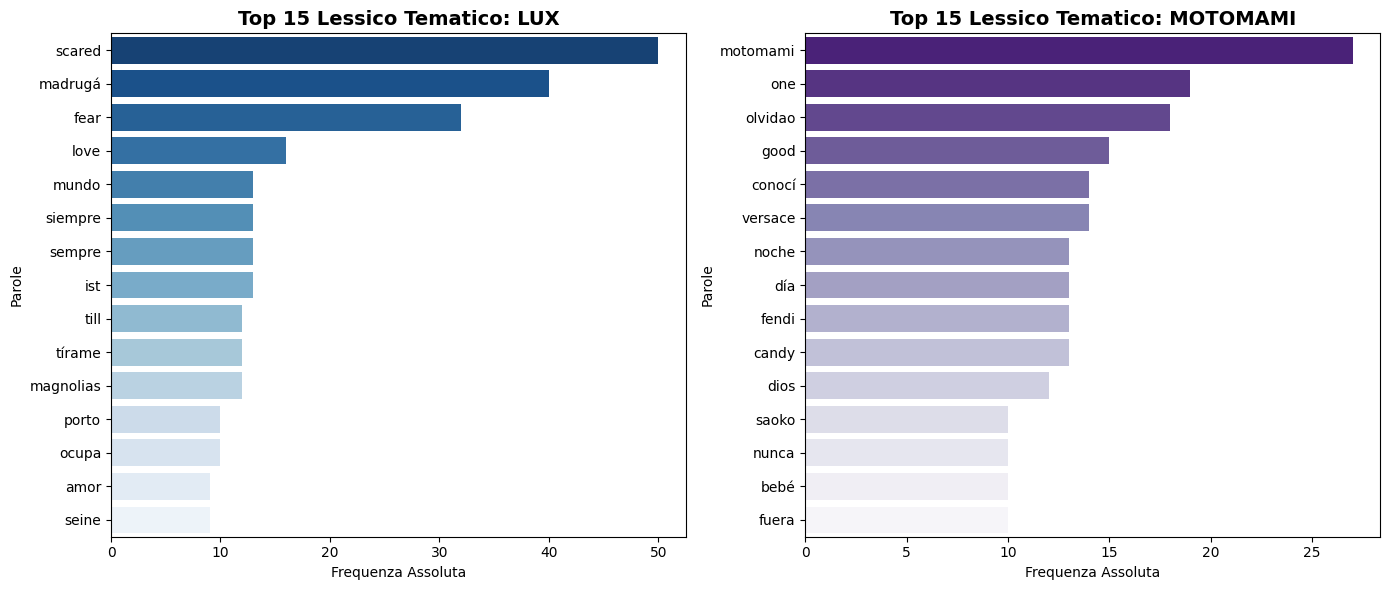

In [ ]:
import pandas as pd
import os
import re
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. CARICAMENTO DEL MASTER DEFINITIVO
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_master = os.path.join(cartella_progetto, '9. Corpus Rosalia Master Definitivo.xlsx')

if os.path.exists(percorso_master):
    df = pd.read_excel(percorso_master)
else:
    df = pd.read_csv('corpus canzoni(Foglio1).csv', sep=';', encoding='latin1')

# ==========================================
# 2. DEFINIZIONE DELLA STOP-LIST LESSICALE AVANZATA
# (Elimina ausiliari, verbi modali, pronomi e particelle vuote)
# ==========================================
stop_words_avanzate = {
    'ser', 'estar', 'haber', 'tener', 'poder', 'querer', 'deber', 'saber', 'ir', 'venir',
    'soy', 'eres', 'es', 'somos', 'sois', 'son', 'fui', 'fue', 'era', 'eras', 'éramos', 'será',
    'estoy', 'estás', 'está', 'estamos', 'están', 'estaba', 'estuve',
    'he', 'has', 'ha', 'hemos', 'habéis', 'han', 'había', 'hube',
    'tengo', 'tienes', 'tiene', 'tenemos', 'tenéis', 'tienen', 'tenía', 'tuve',
    'puedo', 'puedes', 'puede', 'podemos', 'podéis', 'pueden', 'podía', 'pude',
    'quiero', 'quieres', 'quiere', 'queremos', 'queréis', 'quieren', 'quería', 'quise',
    'sé', 'sabes', 'sabe', 'sabemos', 'sabéis', 'saben', 'sabía', 'supe',
    'voy', 'vas', 'va', 'vamos', 'vais', 'van', 'iba', 'fui',
    'hacer', 'hago', 'haces', 'hace', 'hacemos', 'hacen', 'hizo', 'hacía',
    'decir', 'digo', 'dices', 'dice', 'decimos', 'dicen', 'dijo', 'decía',
    'dar', 'doy', 'das', 'da', 'damos', 'dan', 'dio',
    # Articoli, pronomi, preposizioni, congiunzioni e particelle vuote
    'el', 'la', 'los', 'las', 'un', 'una', 'unos', 'unas', 'y', 'o', 'pero', 'si', 'no',
    'de', 'del', 'al', 'en', 'entre', 'hacia', 'hasta', 'para', 'por', 'sin', 'sobre', 'tras',
    'que', 'quien', 'donde', 'como', 'cuando', 'este', 'esta', 'estos', 'estas', 'ese', 'esa',
    'esos', 'esas', 'me', 'te', 'se', 'nos', 'os', 'le', 'les', 'lo', 'mi', 'tu', 'su',
    'yo', 'tú', 'ti', 'mí', 'mis', 'tus', 'sus', 'nuestro', 'vuestro',
    'the', 'and', 'to', 'of', 'in', 'is', 'it', 'you', 'that', 'he', 'was', 'for', 'on', 'are',
    'der', 'die', 'das', 'und', 'den', 'von', 'zu', 'dem', 'sich', 'des', 'auf', 'für',
    'il', 'lo', 'le', 'i', 'gli', 'uno', 'una', 'e', 'ma', 'per', 'con', 'su', 'da', 'di', 'tra', 'fra',
    'pa', 'mas', 'más', 'tan', 'bien', 'mal', 'asi', 'así', 'todo', 'toda', 'todos', 'todas',
    'algo', 'nada', 'aqui', 'aquí', 'alli', 'allí', 'ta', 'ra', 'so', 'na', 'pu', 'rá', 'tá', 'nonaino'
}

def estrai_sostantivi_aggettivi(testo):
    if not isinstance(testo, str):
        return []
    # Estraiamo parole alfabetiche ripulite
    parole = re.findall(r'\b[a-zA-ZáéíóúÁÉÍÓÚñÑüÜàèìòùÀÈÌÒÙ]+\b', testo.lower())
    # Filtriamo escludendo le stop words e parole con meno di 3 lettere
    filtrate = [p for p in parole if p not in stop_words_avanzate and len(p) > 2]
    return filtrate

df['lessico_tematico'] = df['testo'].apply(estrai_sostantivi_aggettivi)

# ==========================================
# 3. SEPARAZIONE DEI DUE ALBUM (LUX vs MOTOMAMI)
# ==========================================
df_lux = df[df['album'].astype(str).str.contains('Lux', case=False, na=False)]
df_motomami = df[df['album'].astype(str).str.contains('Motomami', case=False, na=False)]

tokens_lux = []
for lista in df_lux['lessico_tematico']:
    tokens_lux.extend(lista)

tokens_motomami = []
for lista in df_motomami['lessico_tematico']:
    tokens_motomami.extend(lista)

freq_lux = Counter(tokens_lux)
freq_motomami = Counter(tokens_motomami)

df_freq_lux = pd.DataFrame(freq_lux.most_common(15), columns=['Parola', 'Frequenza'])
df_freq_mot = pd.DataFrame(freq_motomami.most_common(15), columns=['Parola', 'Frequenza'])

print("=== TOP 15 LESSICO TEMATICO: LUX ===")
display(df_freq_lux)

print("\n=== TOP 15 LESSICO TEMATICO: MOTOMAMI ===")
display(df_freq_mot)

# ==========================================
# 4. RAPPRESENTAZIONE GRAFICA COMPARATIVA
# ==========================================
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.barplot(data=df_freq_lux, x='Frequenza', y='Parola', palette='Blues_r', hue='Parola', legend=False)
plt.title('Top 15 Lessico Tematico: LUX', fontsize=14, fontweight='bold')
plt.xlabel('Frequenza Assoluta')
plt.ylabel('Parole')

plt.subplot(1, 2, 2)
sns.barplot(data=df_freq_mot, x='Frequenza', y='Parola', palette='Purples_r', hue='Parola', legend=False)
plt.title('Top 15 Lessico Tematico: MOTOMAMI', fontsize=14, fontweight='bold')
plt.xlabel('Frequenza Assoluta')
plt.ylabel('Parole')

plt.tight_layout()
plt.show()

Ho chiesto poi di estrarre la parola più frequente per ciascuna lingua o combinazione linguistica presente nel tuo corpus, mantenendo rigorosamente la logica di filtraggio per isolare sostantivi, aggettivi e termini tematici significativi (escludendo stop words, verbi ausiliari e particelle vuote)

In [ ]:
import pandas as pd
import os
import re
from collections import Counter

# ==========================================
# 1. CARICAMENTO DEL MASTER DEFINITIVO
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_master = os.path.join(cartella_progetto, '9. Corpus Rosalia Master Definitivo.xlsx')

if os.path.exists(percorso_master):
    df = pd.read_excel(percorso_master)
else:
    df = pd.read_csv('corpus canzoni(Foglio1).csv', sep=';', encoding='latin1')

# Identifichiamo la colonna delle lingue (gestendo eventuali spazi nel nome)
col_lingua = next((c for c in df.columns if 'lingua' in c.lower()), 'lingue ')

# ==========================================
# 2. DEFINIZIONE DELLA STOP-LIST LESSICALE AVANZATA
# ==========================================
stop_words_avanzate = {
    'ser', 'estar', 'haber', 'tener', 'poder', 'querer', 'deber', 'saber', 'ir', 'venir',
    'soy', 'eres', 'es', 'somos', 'sois', 'son', 'fui', 'fue', 'era', 'eras', 'éramos', 'será',
    'estoy', 'estás', 'está', 'estamos', 'están', 'estaba', 'estuve',
    'he', 'has', 'ha', 'hemos', 'habéis', 'han', 'había', 'hube',
    'tengo', 'tienes', 'tiene', 'tenemos', 'tenéis', 'tienen', 'tenía', 'tuve',
    'puedo', 'puedes', 'puede', 'podemos', 'podéis', 'pueden', 'podía', 'pude',
    'quiero', 'quieres', 'quiere', 'queremos', 'queréis', 'quieren', 'quería', 'quise',
    'sé', 'sabes', 'sabe', 'sabemos', 'sabéis', 'saben', 'sabía', 'supe',
    'voy', 'vas', 'va', 'vamos', 'vais', 'van', 'iba', 'fui',
    'hacer', 'hago', 'haces', 'hace', 'hacemos', 'hacen', 'hizo', 'hacía',
    'decir', 'digo', 'dices', 'dice', 'decimos', 'dicen', 'dijo', 'decía',
    'dar', 'doy', 'das', 'da', 'damos', 'dan', 'dio',
    # Articoli, pronomi, preposizioni, congiunzioni e particelle vuote
    'el', 'la', 'los', 'las', 'un', 'una', 'unos', 'unas', 'y', 'o', 'pero', 'si', 'no',
    'de', 'del', 'al', 'en', 'entre', 'hacia', 'hasta', 'para', 'por', 'sin', 'sobre', 'tras',
    'que', 'quien', 'donde', 'como', 'cuando', 'este', 'esta', 'estos', 'estas', 'ese', 'esa',
    'esos', 'esas', 'me', 'te', 'se', 'nos', 'os', 'le', 'les', 'lo', 'mi', 'tu', 'su',
    'yo', 'tú', 'ti', 'mí', 'mis', 'tus', 'sus', 'nuestro', 'vuestro',
    'the', 'and', 'to', 'of', 'in', 'is', 'it', 'you', 'that', 'he', 'was', 'for', 'on', 'are',
    'der', 'die', 'das', 'und', 'den', 'von', 'zu', 'dem', 'sich', 'des', 'auf', 'für',
    'il', 'lo', 'le', 'i', 'gli', 'uno', 'una', 'e', 'ma', 'per', 'con', 'su', 'da', 'di', 'tra', 'fra',
    'pa', 'mas', 'más', 'tan', 'bien', 'mal', 'asi', 'así', 'todo', 'toda', 'todos', 'todas',
    'algo', 'nada', 'aqui', 'aquí', 'alli', 'allí', 'ta', 'ra', 'so', 'na', 'pu', 'rá', 'tá', 'nonaino'
}

# ==========================================
# 3. ESTRAZIONE E ANALISI PER CIASCUNA LINGUA
# ==========================================
report_lingue = []

for lingua in df[col_lingua].unique():
    df_lingua = df[df[col_lingua] == lingua]
    tokens_lingua = []

    for testo in df_lingua['testo']:
        if isinstance(testo, str):
            # Estrazione parole alfabetiche ripulite
            parole = re.findall(r'\b[a-zA-ZáéíóúÁÉÍÓÚñÑüÜàèìòùÀÈÌÒÙ]+\b', testo.lower())
            # Filtriamo escludendo le stop words e parole con meno di 3 lettere
            filtrate = [p for p in parole if p not in stop_words_avanzate and len(p) > 2]
            tokens_lingua.extend(filtrate)

    # Contiamo le frequenze
    freq = Counter(tokens_lingua)
    if freq:
        piu_frequente, conteggio = freq.most_common(1)[0]
        report_lingue.append({
            'Lingua / Categoria': lingua,
            'Parola più frequente': piu_frequente,
            'Frequenza': conteggio
        })

# Creazione del DataFrame finale di riepilogo
df_report_lingue = pd.DataFrame(report_lingue)

print("=== PAROLA PIÙ FREQUENTE PER CIASCUNA LINGUA/CATEGORIA ===")
display(df_report_lingue)

# Salvataggio opzionale del report in Excel
percorso_report = os.path.join(cartella_progetto, '10. Report Parole per Lingua.xlsx')
df_report_lingue.to_excel(percorso_report, index=False)
print(f"\n📁 Report salvato in: {percorso_report}")

=== PAROLA PIÙ FREQUENTE PER CIASCUNA LINGUA/CATEGORIA ===


,Lingua / Categoria,Parola più frequente,Frequenza
0,Spagnolo,motomami,27
1,Inglese/ Spagnolo,outside,6
2,Spagnolo/ Giapponese/Inglese,scared,50
3,Italiano/Inglese,sempre,12
4,Inglese/Spagnolo/Tedesco,love,16
5,Spagnolo/Ucraino,madrugá,40
6,Spagnolo/Arabo/Inglese,ocupa,10
7,Spagnolo/Inglese,good,15
8,Portoghese/Spagnolo,ainda,7



📁 Report salvato in: /content/drive/MyDrive/Progetto-Rosalia/10. Report Parole per Lingua.xlsx


Chiedo poi un codice per  generare tre word clouds, una generale che riguarda le parole tematiche più frequenti di entrambi gli album, e due separate che rappresentino visivamente le parole piu comuni di lux  e quelle di motomami.

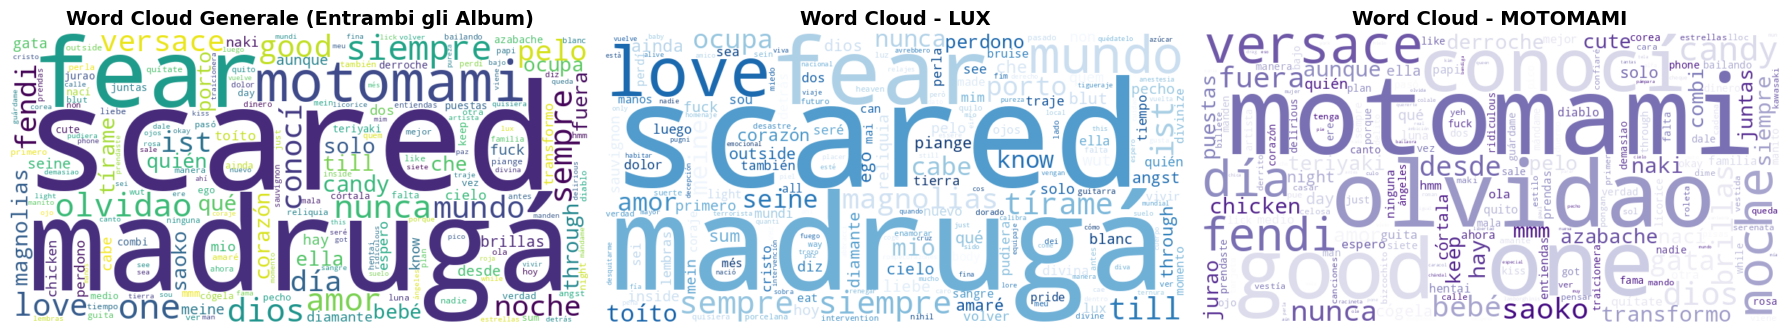

In [ ]:
import pandas as pd
import os
import re
from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# ==========================================
# 1. CARICAMENTO DATI E PULIZIA LESSICALE
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_master = os.path.join(cartella_progetto, '9. Corpus Rosalia Master Definitivo.xlsx')

if os.path.exists(percorso_master):
    df = pd.read_excel(percorso_master)
else:
    df = pd.read_csv('corpus canzoni(Foglio1).csv', sep=';', encoding='latin1')

stop_words_avanzate = {
    'ser', 'estar', 'haber', 'tener', 'poder', 'querer', 'deber', 'saber', 'ir', 'venir',
    'soy', 'eres', 'es', 'somos', 'sois', 'son', 'fui', 'fue', 'era', 'eras', 'éramos', 'será',
    'estoy', 'estás', 'está', 'estamos', 'están', 'estaba', 'estuve',
    'he', 'has', 'ha', 'hemos', 'habéis', 'han', 'había', 'hube',
    'tengo', 'tienes', 'tiene', 'tenemos', 'tenéis', 'tienen', 'tenía', 'tuve',
    'puedo', 'puedes', 'puede', 'podemos', 'podéis', 'pueden', 'podía', 'pude',
    'quiero', 'quieres', 'quiere', 'queremos', 'queréis', 'quieren', 'quería', 'quise',
    'sé', 'sabes', 'sabe', 'sabemos', 'sabéis', 'saben', 'sabía', 'supe',
    'voy', 'vas', 'va', 'vamos', 'vais', 'van', 'iba', 'fui',
    'hacer', 'hago', 'haces', 'hace', 'hacemos', 'hacen', 'hizo', 'hacía',
    'decir', 'digo', 'dices', 'dice', 'decimos', 'dicen', 'dijo', 'decía',
    'dar', 'doy', 'das', 'da', 'damos', 'dan', 'dio',
    'el', 'la', 'los', 'las', 'un', 'una', 'unos', 'unas', 'y', 'o', 'pero', 'si', 'no',
    'de', 'del', 'al', 'en', 'entre', 'hacia', 'hasta', 'para', 'por', 'sin', 'sobre', 'tras',
    'que', 'quien', 'donde', 'como', 'cuando', 'este', 'esta', 'estos', 'estas', 'ese', 'esa',
    'esos', 'esas', 'me', 'te', 'se', 'nos', 'os', 'le', 'les', 'lo', 'mi', 'tu', 'su',
    'yo', 'tú', 'ti', 'mí', 'mis', 'tus', 'sus', 'nuestro', 'vuestro',
    'the', 'and', 'to', 'of', 'in', 'is', 'it', 'you', 'that', 'he', 'was', 'for', 'on', 'are',
    'der', 'die', 'das', 'und', 'den', 'von', 'zu', 'dem', 'sich', 'des', 'auf', 'für',
    'il', 'lo', 'le', 'i', 'gli', 'uno', 'una', 'e', 'ma', 'per', 'con', 'su', 'da', 'di', 'tra', 'fra',
    'pa', 'mas', 'más', 'tan', 'bien', 'mal', 'asi', 'así', 'todo', 'toda', 'todos', 'todas',
    'algo', 'nada', 'aqui', 'aquí', 'alli', 'allí', 'ta', 'ra', 'so', 'na', 'pu', 'rá', 'tá', 'nonaino'
}

def estraici_tematici(testo):
    if not isinstance(testo, str):
        return []
    parole = re.findall(r'\b[a-zA-ZáéíóúÁÉÍÓÚñÑüÜàèìòùÀÈÌÒÙ]+\b', testo.lower())
    filtrate = [p for p in parole if p not in stop_words_avanzate and len(p) > 2]
    return filtrate

df['lessico_tematico'] = df['testo'].apply(estraici_tematici)

# Separazione dei corpus per album
df_lux = df[df['album'].astype(str).str.contains('Lux', case=False, na=False)]
df_motomami = df[df['album'].astype(str).str.contains('Motomami', case=False, na=False)]

# Creazione delle liste di token aggregate
tokens_generali = []
for lista in df['lessico_tematico']: tokens_generali.extend(lista)

tokens_lux = []
for lista in df_lux['lessico_tematico']: tokens_lux.extend(lista)

tokens_motomami = []
for lista in df_motomami['lessico_tematico']: tokens_motomami.extend(lista)

# Convertiamo le frequenze in dizionari per le word clouds
freq_gen = dict(Counter(tokens_generali))
freq_l = dict(Counter(tokens_lux))
freq_m = dict(Counter(tokens_motomami))

# ==========================================
# 2. GENERAZIONE E PLOT DELLE WORD CLOUDS
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Word Cloud Generale
wc_gen = WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate_from_frequencies(freq_gen)
axes[0].imshow(wc_gen, interpolation='bilinear')
axes[0].set_title('Word Cloud Generale (Entrambi gli Album)', fontsize=14, fontweight='bold')
axes[0].axis('off')

# 2. Word Cloud Lux
wc_lux = WordCloud(width=800, height=400, background_color='white', colormap='Blues').generate_from_frequencies(freq_l)
axes[1].imshow(wc_lux, interpolation='bilinear')
axes[1].set_title('Word Cloud - LUX', fontsize=14, fontweight='bold')
axes[1].axis('off')

# 3. Word Cloud Motomami
wc_moto = WordCloud(width=800, height=400, background_color='white', colormap='Purples').generate_from_frequencies(freq_m)
axes[2].imshow(wc_moto, interpolation='bilinear')
axes[2].set_title('Word Cloud - MOTOMAMI', fontsize=14, fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
plt.show()

Le cloud words sono sature, richiedo un codice per crearle secondo le classifiche delle prime 15 piu frequenti create in precedenza per poi salvarle nella cartella drive.

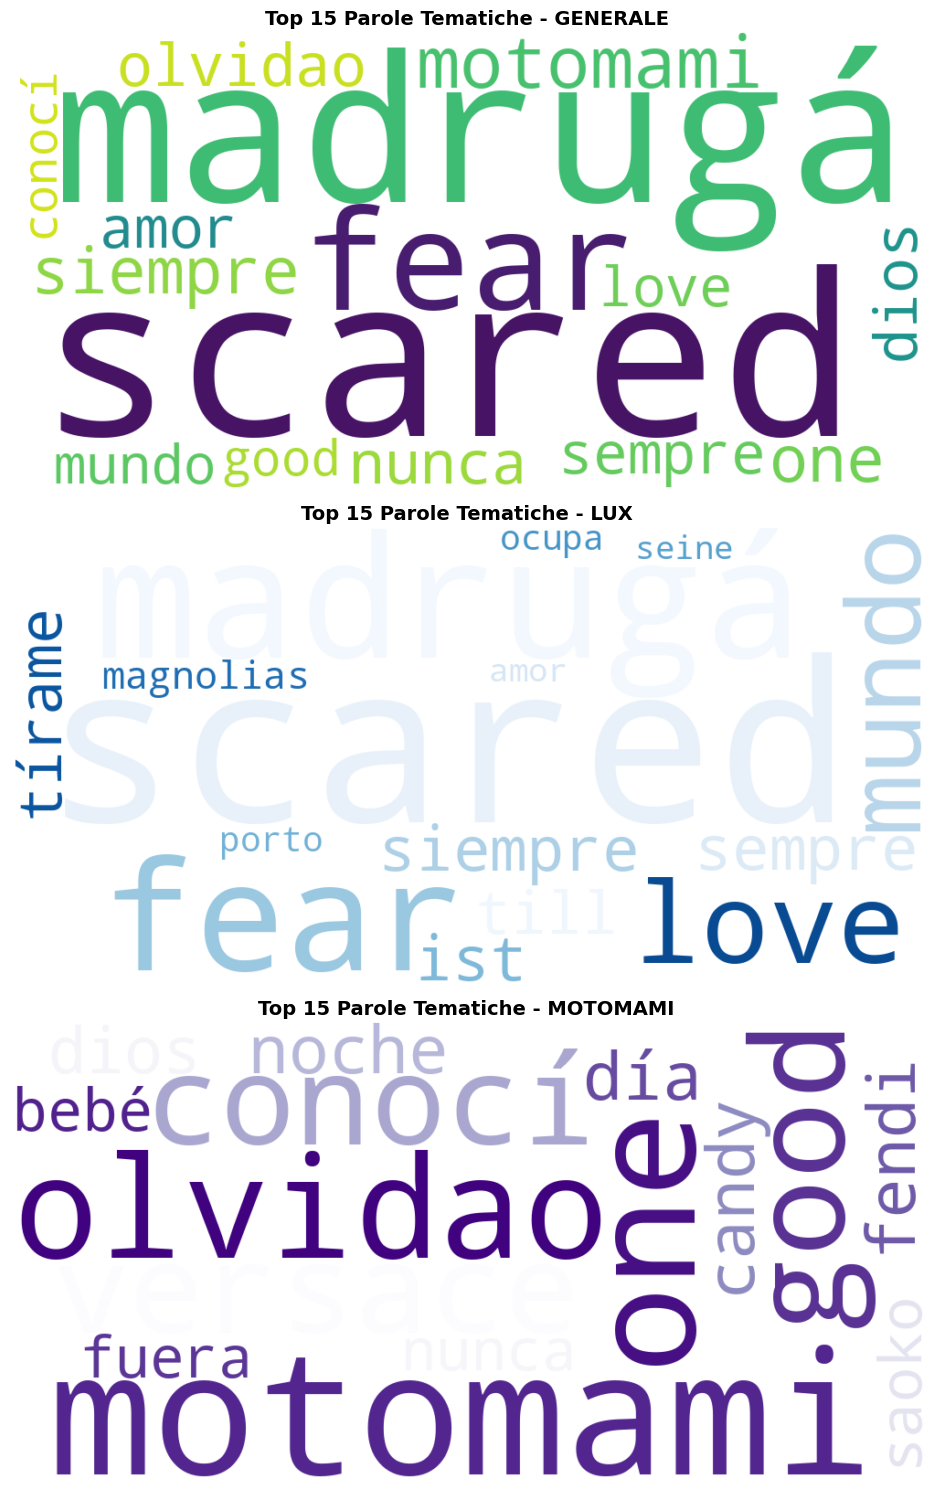

✨ Word clouds salvate con successo nella cartella Google Drive: /content/drive/MyDrive/Progetto-Rosalia


In [ ]:
import pandas as pd
import os
import re
from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# ==========================================
# 1. CARICAMENTO DATI E PULIZIA LESSICALE
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
os.makedirs(cartella_progetto, exist_ok=True)

percorso_master = os.path.join(cartella_progetto, '9. Corpus Rosalia Master Definitivo.xlsx')
if os.path.exists(percorso_master):
    df = pd.read_excel(percorso_master)
else:
    df = pd.read_csv('corpus canzoni(Foglio1).csv', sep=';', encoding='latin1')

stop_words_avanzate = {
    'ser', 'estar', 'haber', 'tener', 'poder', 'querer', 'deber', 'saber', 'ir', 'venir',
    'soy', 'eres', 'es', 'somos', 'sois', 'son', 'fui', 'fue', 'era', 'eras', 'éramos', 'será',
    'estoy', 'estás', 'está', 'estamos', 'están', 'estaba', 'estuve',
    'he', 'has', 'ha', 'hemos', 'habéis', 'han', 'había', 'hube',
    'tengo', 'tienes', 'tiene', 'tenemos', 'tenéis', 'tienen', 'tenía', 'tuve',
    'puedo', 'puedes', 'puede', 'podemos', 'podéis', 'pueden', 'podía', 'pude',
    'quiero', 'quieres', 'quiere', 'queremos', 'queréis', 'quieren', 'quería', 'quise',
    'sé', 'sabes', 'sabe', 'sabemos', 'sabéis', 'saben', 'sabía', 'supe',
    'voy', 'vas', 'va', 'vamos', 'vais', 'van', 'iba', 'fui',
    'hacer', 'hago', 'haces', 'hace', 'hacemos', 'hacen', 'hizo', 'hacía',
    'decir', 'digo', 'dices', 'dice', 'decimos', 'dicen', 'dijo', 'decía',
    'dar', 'doy', 'das', 'da', 'damos', 'dan', 'dio',
    'el', 'la', 'los', 'las', 'un', 'una', 'unos', 'unas', 'y', 'o', 'pero', 'si', 'no',
    'de', 'del', 'al', 'en', 'entre', 'hacia', 'hasta', 'para', 'por', 'sin', 'sobre', 'tras',
    'que', 'quien', 'donde', 'como', 'cuando', 'este', 'esta', 'estos', 'estas', 'ese', 'esa',
    'esos', 'esas', 'me', 'te', 'se', 'nos', 'os', 'le', 'les', 'lo', 'mi', 'tu', 'su',
    'yo', 'tú', 'ti', 'mí', 'mis', 'tus', 'sus', 'nuestro', 'vuestro',
    'the', 'and', 'to', 'of', 'in', 'is', 'it', 'you', 'that', 'he', 'was', 'for', 'on', 'are',
    'der', 'die', 'das', 'und', 'den', 'von', 'zu', 'dem', 'sich', 'des', 'auf', 'für',
    'il', 'lo', 'le', 'i', 'gli', 'uno', 'una', 'e', 'ma', 'per', 'con', 'su', 'da', 'di', 'tra', 'fra',
    'pa', 'mas', 'más', 'tan', 'bien', 'mal', 'asi', 'así', 'todo', 'toda', 'todos', 'todas',
    'algo', 'nada', 'aqui', 'aquí', 'alli', 'allí', 'ta', 'ra', 'so', 'na', 'pu', 'rá', 'tá', 'nonaino'
}

def estraici_tematici(testo):
    if not isinstance(testo, str):
        return []
    parole = re.findall(r'\b[a-zA-ZáéíóúÁÉÍÓÚñÑüÜàèìòùÀÈÌÒÙ]+\b', testo.lower())
    filtrate = [p for p in parole if p not in stop_words_avanzate and len(p) > 2]
    return filtrate

df['lessico_tematico'] = df['testo'].apply(estraici_tematici)

df_lux = df[df['album'].astype(str).str.contains('Lux', case=False, na=False)]
df_motomami = df[df['album'].astype(str).str.contains('Motomami', case=False, na=False)]

tokens_gen, tokens_lux, tokens_moto = [], [], []
for l in df['lessico_tematico']: tokens_gen.extend(l)
for l in df_lux['lessico_tematico']: tokens_lux.extend(l)
for l in df_motomami['lessico_tematico']: tokens_moto.extend(l)

# ==========================================
# 2. SELEZIONE RIGOROSA DELLE TOP 15
# ==========================================
freq_gen_15 = dict(Counter(tokens_gen).most_common(15))
freq_lux_15 = dict(Counter(tokens_lux).most_common(15))
freq_moto_15 = dict(Counter(tokens_moto).most_common(15))

# ==========================================
# 3. GENERAZIONE E SALVATAGGIO DELLE WORD CLOUDS
# ==========================================
config_wc = dict(width=1000, height=500, background_color='white', max_words=15, relative_scaling=0.5)

# 1. Generale
wc_gen = WordCloud(**config_wc, colormap='viridis').generate_from_frequencies(freq_gen_15)
path_gen = os.path.join(cartella_progetto, 'WordCloud_Generale_Top15.png')
wc_gen.to_file(path_gen)

# 2. Lux
wc_lux = WordCloud(**config_wc, colormap='Blues').generate_from_frequencies(freq_lux_15)
path_lux = os.path.join(cartella_progetto, 'WordCloud_Lux_Top15.png')
wc_lux.to_file(path_lux)

# 3. Motomami
wc_moto = WordCloud(**config_wc, colormap='Purples').generate_from_frequencies(freq_moto_15)
path_moto = os.path.join(cartella_progetto, 'WordCloud_Motomami_Top15.png')
wc_moto.to_file(path_moto)

# Visualizzazione inline in Colab
fig, axes = plt.subplots(3, 1, figsize=(10, 15))

axes[0].imshow(wc_gen, interpolation='bilinear')
axes[0].set_title('Top 15 Parole Tematiche - GENERALE', fontsize=14, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(wc_lux, interpolation='bilinear')
axes[1].set_title('Top 15 Parole Tematiche - LUX', fontsize=14, fontweight='bold')
axes[1].axis('off')

axes[2].imshow(wc_moto, interpolation='bilinear')
axes[2].set_title('Top 15 Parole Tematiche - MOTOMAMI', fontsize=14, fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
plt.show()

print(f"✨ Word clouds salvate con successo nella cartella Google Drive: {cartella_progetto}")

L'operazione successiva consiste nel richiedere uno script che abbia come output lo svelamento delle concordanze delle parole più ricorrenti. A partire da un target, si prende in considerazione il suo contesto. L'analisi delle concordanze (o KWIC - Key Word In Context) è uno dei pilastri dell'analisi testuale computerizzata. Permette di passare dalla semplice frequenza statistica (la parola isolata) al contesto semantico e sintattico in cui quella parola viene effettivamente usata da Rosalía

In [ ]:
import pandas as pd
import os
from collections import Counter
import re

cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_master = os.path.join(cartella_progetto, '9. Corpus Rosalia Master Definitivo.xlsx')

df = pd.read_excel(percorso_master)

# Scegli una parola target di cui vuoi vedere il contesto (es. 'scared', 'motomami', 'madrugá')
target = 'scared'
finestra = 5 # numero di parole prima e dopo da mostrare come contesto

concordanze = []
for idx, row in df.iterrows():
    testo = str(row['testo']).lower()
    parole = re.findall(r'\b[a-zA-ZáéíóúÁÉÍÓÚñÑüÜàèìòùÀÈÌÒÙ]+\b', testo)

    for i, p in enumerate(parole):
        if p == target:
            inizio = max(0, i - finestra)
            fine = min(len(parole), i + finestra + 1)
            contesto = " ".join(parole[inizio:fine])
            concordanze.append({
                'Titolo': row['titolo'],
                'Album': row['album'],
                'Contesto': contesto
            })

df_concordanze = pd.DataFrame(concordanze)
print(f"=== CONCORDANZE PER IL TARGET: '{target}' ===")
display(df_concordanze.head(10))

=== CONCORDANZE PER IL TARGET: 'scared' ===


,Titolo,Album,Contesto
0,Porcelana,Lux,mundi i know you re scared scared scared scare...
1,Porcelana,Lux,i know you re scared scared scared scared scar...
2,Porcelana,Lux,know you re scared scared scared scared scared...
3,Porcelana,Lux,you re scared scared scared scared scared scar...
4,Porcelana,Lux,re scared scared scared scared scared scared s...
5,Porcelana,Lux,scared scared scared scared scared scared scar...
6,Porcelana,Lux,scared scared scared scared scared scared scar...
7,Porcelana,Lux,scared scared scared scared scared scared scar...
8,Porcelana,Lux,scared scared scared scared scared scared scar...
9,Porcelana,Lux,scared scared scared scared scared scared scar...


Questo è il risultato della ricerca delle concordanze (KWIC) per la parola target 'scared' all'interno del brano Porcelana dell'album Lux.
Nel testo della canzone, Rosalía ripete letteralmente la stessa parola in sequenza per creare un effetto ritmico ed emotivo martellante. Dato che lo script estrae una "finestra" fissa di parole attorno a ciascuna occorrenza, quando incontra la parola "scared" seguita da un'altra "scared", il contesto si riempie inevitabilmente della stessa parola ripetuta in blocco. Per evitare questo effetto di "saturazione" dovuto alle ripetizioni consecutive nel testo originale, ho perfezionato lo script affinché mostri il contesto allargato includendo i versi precedenti e successivi (invece di contare singole parole adiacenti)

In [ ]:
# Scriviamo uno script raffinato per le concordanze contestuali (KWIC) che ignora le ripetizioni consecutive
# e mostra il contesto esteso (frasi/versi) per i due album o per parole chiave mirate.
import pandas as pd
import os
import re

cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_master = os.path.join(cartella_progetto, '9. Corpus Rosalia Master Definitivo.xlsx')

if os.path.exists(percorso_master):
    df = pd.read_excel(percorso_master)
else:
    df = pd.read_csv('corpus canzoni(Foglio1).csv', sep=';', encoding='latin1')

def estrai_concordanze_per_verso(df, target_parole):
    risultati = []
    for idx, row in df.iterrows():
        testo = str(row['testo'])
        righe = testo.split('\n')
        for riga in righe:
            riga_lower = riga.lower()
            for tp in target_parole:
                if re.search(r'\b' + tp + r'\b', riga_lower):
                    risultati.append({
                        'Album': row['album'],
                        'Titolo': row['titolo'],
                        'Parola Target': tp,
                        'Verso di Contesto': riga.strip()
                    })
                    break # Evitiamo duplicati sullo stesso verso
    return pd.DataFrame(risultati)

# Eseguiamo la ricerca per alcune parole chiave emblematiche dei due album
targets = ['scared', 'fear', 'motomami', 'madrugá', 'versace', 'love', 'olvidao']
df_kwic = estrai_concordanze_per_verso(df, targets)

print(f"Trovate {len(df_kwic)} occorrenze contestuali pulite.")
print(df_kwic.head(10).to_string())

Trovate 88 occorrenze contestuali pulite.
  Album     Titolo Parola Target                               Verso di Contesto
0   Lux  Porcelana        scared                            I know you're scared
1   Lux  Porcelana        scared  Scared, scared, scared, scared, scared, scared
2   Lux  Porcelana        scared  Scared, scared, scared, scared, scared, scared
3   Lux  Porcelana          fear                              Know that you fear
4   Lux  Porcelana          fear  Fear, fear, fear, fear, fear, fear, fear, fear
5   Lux  Porcelana          fear  Fear, fear, fear, fear, fear, fear, fear, fear
6   Lux  Porcelana        scared         I know that in a way that you're scared
7   Lux  Porcelana        scared          Scared, scared, scared, scared, scared
8   Lux  Porcelana        scared                  Scared, scared, scared, scared
9   Lux  Porcelana        scared          Scared, scared, scared, scared, scared


Per l'album Motomami, la parola tematica in assoluto più frequente (escluse le stop-words e le particelle grammaticali) è proprio motomami (con 27 occorrenze), seguita da one e olvidao.
Eseguo l'analisi delle concordanze (KWIC) mirata su questo termine all'interno dell'album Motomami

In [ ]:
import pandas as pd
import os
import re

# ==========================================
# 1. CARICAMENTO DEL MASTER E FILTRO MOTOMAMI
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_master = os.path.join(cartella_progetto, '9. Corpus Rosalia Master Definitivo.xlsx')

if os.path.exists(percorso_master):
    df = pd.read_excel(percorso_master)
else:
    df = pd.read_csv('corpus canzoni(Foglio1).csv', sep=';', encoding='latin1')

df_moto = df[df['album'].astype(str).str.contains('Motomami', case=False, na=False)]

# Target principale dell'album Motomami
target = 'motomami'
finestra = 4  # numero di parole di contesto prima e dopo

concordanze = []
for idx, row in df_moto.iterrows():
    testo = str(row['testo']).lower()
    parole = re.findall(r'\b[a-zA-ZáéíóúÁÉÍÓÚñÑüÜàèìòùÀÈÌÒÙ]+\b', testo)

    for i, p in enumerate(parole):
        if p == target:
            inizio = max(0, i - finestra)
            fine = min(len(parole), i + finestra + 1)
            contesto = " ".join(parole[inizio:fine])
            concordanze.append({
                'Titolo': row['titolo'],
                'Album': row['album'],
                'Contesto': contesto
            })

df_concordanze = pd.DataFrame(concordanze)

print(f"=== CONCORDANZE PER IL TARGET: '{target}' (Album: Motomami) ===")
display(df_concordanze.head(15))

# Salvataggio del report delle concordanze su Drive
percorso_output = os.path.join(cartella_progetto, f'Concordanze_{target}.xlsx')
df_concordanze.to_excel(percorso_output, index=False)
print(f"\n📁 Report concordanze salvato in: {percorso_output}")

=== CONCORDANZE PER IL TARGET: 'motomami' (Album: Motomami) ===


,Titolo,Album,Contesto
0,Motomami,Motomami,okay motomami pesa mi tatami hit
1,Motomami,Motomami,lo tsunami oh okay motomami fina un origami cruda
2,Motomami,Motomami,de licor prr okay motomami pesa mi tatami hit
3,Motomami,Motomami,lo tsunami oh okay motomami fina un origami cruda
4,Motomami,Motomami,a lo sashimi oh motomami motomami motomami mot...
5,Motomami,Motomami,lo sashimi oh motomami motomami motomami motom...
6,Motomami,Motomami,sashimi oh motomami motomami motomami motomami...
7,Motomami,Motomami,oh motomami motomami motomami motomami motomam...
8,Motomami,Motomami,motomami motomami motomami motomami motomami m...
9,Motomami,Motomami,motomami motomami motomami motomami motomami m...



📁 Report concordanze salvato in: /content/drive/MyDrive/Progetto-Rosalia/Concordanze_motomami.xlsx


A differenza di quanto visto con Lux (dove le ripetizioni erano legate a stati d'ansia o paura come "scared"), in Motomami il termine centrale viene associato a rime e immagini stilistiche urbane e di identità (es. "pesa mi tatami", "fina un origami", "a lo sashimi"), riflettendo l'estetica pop-luxe e concettuale dell'album.

Il passaggio successivo  trasforma i testi grezzi delle canzoni in dati stilometrici quantificabili, pronti per essere confrontati tra i due album.
Lo script va a pescare il file unificato 9. Corpus Rosalia Master Definitivo.xlsx direttamente dalla cartella, assicurandosi di lavorare su una base dati solida, che mantiene intatti tutti i metadati originali (titoli, album, anni, minuti e collaborazioni).
Per ogni singolo brano, lo script individua e isola i types, ovvero l'elenco delle parole uniche eliminando i doppioni e le ripetizioni. Calcola numericamente quanti types unici compongono il brano (num_types_puliti) e crea una stringa pulita pronta per essere analizzata o visualizzata.
Salva il risultato all'interno di un nuovo file Excel aggiornato (7. Corpus Rosalia Types Aggiornato.xlsx).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import os
import re

# ==========================================================
# 1. CONFIGURAZIONE DEI PERCORSI (Allineata al Master Definitivo)
# ==========================================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_partenza = os.path.join(cartella_progetto, '9. Corpus Rosalia Master Definitivo.xlsx')
percorso_output = os.path.join(cartella_progetto, '7. Corpus Rosalia Types Aggiornato.xlsx')

print(f"📁 Caricamento del corpus da: {percorso_partenza}")
df = pd.read_excel(percorso_partenza)

# ==========================================================
# 2. FUNZIONE DI PULIZIA E ESTRAZIONE DEI TYPES
# ==========================================================
def estrai_types(testo):
    if not isinstance(testo, str):
        return []
    # Estrazione di tutte le parole alfabetiche (gestendo accenti e caratteri speciali)
    parole = re.findall(r'\b[a-zA-ZáéíóúÁÉÍÓÚñÑüÜàèìòùÀÈÌÒÙ]+\b', testo.lower())
    # Restituisce l'insieme delle parole uniche (types)
    return sorted(list(set(parole)))

# ==========================================================
# 3. ELABORAZIONE DEL DATASET
# ==========================================================
print("🔄 Estrazione dei types unici per ciascun brano...")
df['lista_types_puliti'] = df['testo'].apply(estrai_types)
df['num_types_puliti'] = df['lista_types_puliti'].apply(len)
df['lista_types_stringa'] = df['lista_types_puliti'].apply(lambda x: ", ".join(x))

# ==========================================================
# 4. SALVATAGGIO DELL'OUTPUT AGGIORNATO
# ==========================================================
df.to_excel(percorso_output, index=False)

print(f"\n✨ Operazione completata con successo!")
print(f"📁 File di output salvato in: {percorso_output}")
print(f"📊 Totale brani elaborati: {len(df)}")

# Anteprima delle prime righe del risultato
display(df[['titolo', 'album', 'num_types_puliti']].head(5))

📁 Caricamento del corpus da: /content/drive/MyDrive/Progetto-Rosalia/9. Corpus Rosalia Master Definitivo.xlsx
🔄 Estrazione dei types unici per ciascun brano...

✨ Operazione completata con successo!
📁 File di output salvato in: /content/drive/MyDrive/Progetto-Rosalia/7. Corpus Rosalia Types Aggiornato.xlsx
📊 Totale brani elaborati: 30


,titolo,album,num_types_puliti
0,"Sexo, Violencia y LLantas",Lux,42
1,Reliquia,Lux,121
2,Divinize,Lux,117
3,Porcelana,Lux,100
4,Mio Cristo Piange Diamanti,Lux,122


Il passo successivo naturale è il calcolo della ricchezza lessicale, il Type-Token Ratio (TTR). Il TTR si calcola dividendo il numero di parole uniche (types) per il numero totale di parole (tokens): più alto è il valore, più vario e ricco è il vocabolario usato nel brano. Ci permette di dimostrare scientificamente (e dare in pasto all'LLM) la differenza di densità lessicale tra la scrittura stratificata e multilingue di Lux e lo stile più ritmico, ripetitivo e immediato di Motomami.

In [ ]:
import pandas as pd
import os
import re
import numpy as np

# ==========================================================
# 1. CONFIGURAZIONE DEI PERCORSI
# ==========================================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_master = os.path.join(cartella_progetto, '9. Corpus Rosalia Master Definitivo.xlsx')
percorso_output = os.path.join(cartella_progetto, '9. Corpus Rosalia Master Definitivo.xlsx') # Sovrascrive aggiornando il Master

print(f"📁 Caricamento del dataset da: {percorso_master}")
df = pd.read_excel(percorso_master)

# ==========================================================
# 2. FUNZIONI DI CALCOLO LESSICALE (TOKENS E TYPES)
# ==========================================================
def calcola_tokens(testo):
    if not isinstance(testo, str):
        return 0
    parole = re.findall(r'\b[a-zA-ZáéíóúÁÉÍÓÚñÑüÜàèìòùÀÈÌÒÙ]+\b', testo.lower())
    return len(parole)

def calcola_types(testo):
    if not isinstance(testo, str):
        return 0
    parole = re.findall(r'\b[a-zA-ZáéíóúÁÉÍÓÚñÑüÜàèìòùÀÈÌÒÙ]+\b', testo.lower())
    return len(set(parole))

# ==========================================================
# 3. APPLICAZIONE DELLE METRICHE AL DATASET
# ==========================================================
print("🔄 Calcolo di Tokens, Types e TTR per ciascun brano...")

df['num_tokens'] = df['testo'].apply(calcola_tokens)
df['num_types'] = df['testo'].apply(calcola_types)

# Type-Token Ratio (TTR standard) -> Evitiamo divisioni per zero
df['TTR'] = df.apply(lambda row: row['num_types'] / row['num_tokens'] if row['num_tokens'] > 0 else 0, axis=1)

# Indice di Guiraud (TTR radicato, meno sensibile alla lunghezza della canzone)
df['Guiraud_TTR'] = df.apply(lambda row: row['num_types'] / np.sqrt(row['num_tokens']) if row['num_tokens'] > 0 else 0, axis=1)

# ==========================================================
# 4. SALVATAGGIO DEL MASTER AGGIORNATO
# ==========================================================
df.to_excel(percorso_output, index=False)

print(f"\n✨ Metriche lessicali calcolate e salvate con successo!")
print(f"📁 File aggiornato in: {percorso_output}")

# Mostriamo una media per album per vedere subito la differenza stilometrica
if 'album' in df.columns:
    print("\n📊 Media del TTR per album:")
    print(df.groupby('album')[['num_tokens', 'num_types', 'TTR', 'Guiraud_TTR']].mean())

# Anteprima delle prime righe
display(df[['titolo', 'album', 'num_tokens', 'num_types', 'TTR']].head(5))

📁 Caricamento del dataset da: /content/drive/MyDrive/Progetto-Rosalia/9. Corpus Rosalia Master Definitivo.xlsx
🔄 Calcolo di Tokens, Types e TTR per ciascun brano...

✨ Metriche lessicali calcolate e salvate con successo!
📁 File aggiornato in: /content/drive/MyDrive/Progetto-Rosalia/9. Corpus Rosalia Master Definitivo.xlsx

📊 Media del TTR per album:
          num_tokens  num_types       TTR  Guiraud_TTR
album                                                 
Lux       215.600000  98.466667  0.465323     6.607081
Motomami  263.466667  98.533333  0.404419     6.177357


,titolo,album,num_tokens,num_types,TTR
0,"Sexo, Violencia y LLantas",Lux,104,42,0.403846
1,Reliquia,Lux,237,121,0.510549
2,Divinize,Lux,240,117,0.487500
3,Porcelana,Lux,311,100,0.321543
4,Mio Cristo Piange Diamanti,Lux,220,122,0.554545


A parità quasi perfetta di parole uniche utilizzate nei due album (circa 98 types medi per traccia in entrambi), Lux ha un TTR più alto (0.465) rispetto a Motomami (0.404).
Motomami ha brani mediamente più lunghi e con un numero maggiore di parole totali (263.4 contro 215.6), dovuto all'uso di flussi di coscienza, versi rappati e ripetizioni ritmiche strutturali. Di conseguenza, il rapporto di varietà lessicale risulta più concentrato in Lux e più iterativo/pop in Motomami.

Classificazione della metrica e della struttura strofica è utile perche gli LLM tendono a generalizzare la struttura delle canzoni (strofa-ritornello standard). Rosalía rompe continuamente gli schemi (passando da sezioni rappate a cambi di tempo repentini, cori lirici o code parlate).
Chiedo di aggiungere al corpus colonne descrittive della struttura formale dei brani (es. presenza di bridge complessi, dissolvenze, sezioni corali, cambi di lingua interni alla stessa traccia).

In [ ]:
import pandas as pd
import os
import re

# ==========================================
# 1. CONFIGURAZIONE PERCORSI
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
percorso_master = os.path.join(cartella_progetto, '9. Corpus Rosalia Master Definitivo.xlsx')

print(f"📁 Caricamento dataset da: {percorso_master}")
df = pd.read_excel(percorso_master)

# ==========================================
# 2. FUNZIONI DI ANALISI STRUTTURALE E METRICA
# ==========================================

# Parole chiave per rilevare cambi linguistici
parole_inglese = set(['know', 'scared', 'fear', 'you', 'the', 'way', 'yeah', 'baby', 'love', 'like', 'good', 'one'])
parole_latino = set(['ego', 'sum', 'nihil', 'lux', 'mundi', 'sancta', 'divinize'])

def rileva_multilinguismo(testo):
    if not isinstance(testo, str):
        return "Spagnolo Monolingua"

    parole = set(re.findall(r'\b[a-zA-ZáéíóúÁÉÍÓÚñÑüÜàèìòùÀÈÌÒÙ]+\b', testo.lower()))

    ha_inglese = len(parole.intersection(parole_inglese)) > 0
    ha_latino = len(parole.intersection(parole_latino)) > 0

    if ha_inglese and ha_latino:
        return "Ibrido Multilingue (Spagnolo/Inglese/Latino)"
    elif ha_inglese:
        return "Ibrido Bilingue (Spagnolo/Inglese)"
    elif ha_latino:
        return "Ibrido Lirico (Spagnolo/Latino)"
    else:
        return "Prevalentemente Spagnolo/Catalano"

def analizza_struttura(row):
    testo = str(row.get('testo', ''))
    num_tokens = row.get('num_tokens', 0)
    ttr = row.get('TTR', 0.5)
    album = str(row.get('album', ''))

    # Valutazione della frammentarietà e ritmicità basata su TTR e lunghezza
    if ttr < 0.38:
        struttura = "Frammentata Ritmica (Loop / Ripetizioni continue)"
    elif num_tokens < 150:
        struttura = "Unitaria / Vignetta breve"
    elif "Lux" in album:
        struttura = "Fluida Lirica / Progressione non lineare"
    else:
        struttura = "Urbana Collagistica / Strofa-Ritornello atipica"

    return struttura

def rileva_sezione_corale(testo):
    if not isinstance(testo, str):
        return "No"
    lines = testo.split('\n')
    # Se ci sono linee identiche ripetute molte volte o parole chiave corali
    if len(lines) > 0:
        counts = pd.Series(lines).value_counts()
        if (counts > 3).any():
            return "Sì (Sezioni e Cori Iterativi)"
    return "Contenuta"

# ==========================================
# 3. APPLICAZIONE AL MASTER
# ==========================================
print("🔄 Analisi della struttura formale e metrica...")

df['multilinguismo_interno'] = df['testo'].apply(rileva_multilinguismo)
df['struttura_tipo'] = df.apply(analizza_struttura, axis=1)
df['presenza_cori_iterativi'] = df['testo'].apply(rileva_sezione_corale)

# Creazione del Tag per il Prompting dell'LLM
df['prompt_struttura_tag'] = (
    "Struttura: " + df['struttura_tipo'] +
    " | Lingua: " + df['multilinguismo_interno'] +
    " | Cori/Loop: " + df['presenza_cori_iterativi']
)

# ==========================================
# 4. SALVATAGGIO
# ==========================================
df.to_excel(percorso_master, index=False)
print(f"✨ Master Definitivo aggiornato con successo!")

# Anteprima dei risultati
display(df[['titolo', 'album', 'struttura_tipo', 'multilinguismo_interno']].head(8))

📁 Caricamento dataset da: /content/drive/MyDrive/Progetto-Rosalia/9. Corpus Rosalia Master Definitivo.xlsx
🔄 Analisi della struttura formale e metrica...
✨ Master Definitivo aggiornato con successo!


,titolo,album,struttura_tipo,multilinguismo_interno
0,"Sexo, Violencia y LLantas",Lux,Unitaria / Vignetta breve,Prevalentemente Spagnolo/Catalano
1,Reliquia,Lux,Fluida Lirica / Progressione non lineare,Prevalentemente Spagnolo/Catalano
2,Divinize,Lux,Fluida Lirica / Progressione non lineare,Ibrido Multilingue (Spagnolo/Inglese/Latino)
3,Porcelana,Lux,Frammentata Ritmica (Loop / Ripetizioni continue),Ibrido Multilingue (Spagnolo/Inglese/Latino)
4,Mio Cristo Piange Diamanti,Lux,Fluida Lirica / Progressione non lineare,Ibrido Bilingue (Spagnolo/Inglese)
5,Berghain,Lux,Frammentata Ritmica (Loop / Ripetizioni continue),Ibrido Bilingue (Spagnolo/Inglese)
6,La Perla,Lux,Fluida Lirica / Progressione non lineare,Prevalentemente Spagnolo/Catalano
7,Mundo Nuevo,Lux,Unitaria / Vignetta breve,Prevalentemente Spagnolo/Catalano


# Fase 4: I dati qualitativi e le chiamate API

Ho chiesto di creare un codice per pyhton per creare un file json che contenga tutti i 30 testi delle canzoni normalizzati delle canzoni senza punteggiatura e in minuscolo contenuti nella colonna Testo_Senza_Punteggiatura del file 9. Corpus Rosalia Metadati e Lessico Tematico contenuto nel drive al fine di creare un Dataset Misto nella prossima fase.  

In [ ]:
import os
import json
import pandas as pd

# ==========================================
# 1. CONFIGURAZIONE PERCORSI GOOGLE DRIVE
# ==========================================
cartella_progetto = '/content/drive/MyDrive/Progetto-Rosalia'
nome_file_excel = '9. Corpus Rosalia Metadati e Lessico Tematico.xlsx' # Sostituisci con il nome esatto se differisce leggermente
percorso_excel = os.path.join(cartella_progetto, nome_file_excel)
file_json_output = os.path.join(cartella_progetto, 'corpus_rosalia_30_testi_normalizzati.json')

print("📂 Accesso al file Excel su Google Drive in corso...")

try:
    # 2. CARICAMENTO DEL FILE EXCEL
    df = pd.read_excel(percorso_excel)

    colonna_target = 'Testo_Senza_Punteggiatura'

    # Controllo di sicurezza sulla presenza della colonna
    if colonna_target not in df.columns:
        raise ValueError(f"La colonna '{colonna_target}' non è stata trovata. Colonne disponibili nel file: {df.columns.tolist()}")

    # 3. ESTRAZIONE E NORMALIZZAZIONE DEI 30 TESTI
    testi_normalizzati = []

    for idx, row in df.iterrows():
        # Estrae il testo grezzo dalla colonna
        testo_grezzo = str(row.get(colonna_target, ''))

        # Normalizzazione: conversione in minuscolo e pulizia di spazi vuoti multipli
        testo_pulito = ' '.join(testo_grezzo.lower().split())

        # Recupera un titolo di riferimento se disponibile nel dataset, altrimenti assegna un ID progressivo
        titolo_brano = str(row.get('Titolo', row.get('Brano', f'Traccia_{idx + 1}')))

        testi_normalizzati.append({
            "id": f"traccia_{idx + 1:02d}",
            "titolo": titolo_brano,
            "testo_normalizzato": testo_pulito
        })

    # Struttura finale del JSON
    corpus_json = {
        "progetto": "Rosalia Stylistic Recreation",
        "totale_tracce": len(testi_normalizzati),
        "specifiche": "Testi normalizzati in minuscolo e privi di punteggiatura",
        "brani": testi_normalizzati
    }

    # 4. SALVATAGGIO DEL FILE JSON SU DRIVE
    with open(file_json_output, 'w', encoding='utf-8') as f:
        json.dump(corpus_json, f, ensure_ascii=False, indent=4)

    print("\n" + "="*50)
    print("✨ FILE JSON CREATO CON SUCCESSO!")
    print(f"📁 Percorso di salvataggio su Drive:\n   {file_json_output}")
    print(f"📊 Tracce elaborate e normalizzate: {len(testi_normalizzati)}")
    print("="*50)

except Exception as e:
    print(f"\n❌ Errore durante l'esecuzione: {e}")

📂 Accesso al file Excel su Google Drive in corso...

✨ FILE JSON CREATO CON SUCCESSO!
📁 Percorso di salvataggio su Drive:
   /content/drive/MyDrive/Progetto-Rosalia/corpus_rosalia_30_testi_normalizzati.json
📊 Tracce elaborate e normalizzate: 30


Per proseguire verso l'interrogare se  un LLM sa distinguere tra testi umani (originali) e artificiali (generati), la struttura ideale dell'esperimento è un test di classificazione in cieco. Qua ho testato la generazione di una singola strofa nello stile dell'album Motomami tramite l'API di Gemini usando un prompt creativo.

In [ ]:
from google import genai
from google.genai import types

# Inserisci la tua chiave di Google AI Studio
api_key = "AQ.Ab8RN6Llbevzi5FnmdFFrikVhmaifS3wzsaS99oR7sab8ucYxw"
client = genai.Client(api_key=api_key)

prompt_creativo = """
Agisci come Rosalía. Scrivi una strofa inedita nello stile dell'album 'Motomami':
- Struttura: Urbana frammentata / Ritmica con loop
- Profilo linguistico: Ibrido bilingue (Spagnolo/Inglese)
- Densità lessicale (TTR): Bassa, focalizzata su ripetizioni e impatto ritmico.
"""

# Aggiornato con il modello corretto richiesto dall'API
response = client.models.generate_content(
    model='gemini-3.8-flash',
    contents=prompt_creativo,
    config=types.GenerateContentConfig(
        system_instruction="Sei Rosalía. Il tuo stile unisce la tradizione flamencura all'avanguardia urbana, con una metrica imprevedibile, cambi di lingua repentini e forte carica emotiva.",
        temperature=0.9
    )
)

print(response.text)

*(Sonido de tacón seco contra el suelo, corte de beat abrupto, entra un bajo 808 saturado y roto)*

Mmh.
Look at me.
Mírame.
*(Whisper)* Drop it.

Lo rompo, lo coso, lo vuelvo a romper.
Break it, take it, make it, do it.
Lo rompo, lo rompo, lo vuelvo a romper.
Tú quiere' la receta, but you cannot cook it.

No, no.
You cannot cook it.
No, no.
Mira cómo sube.

Pica, pica, pica, pepper.
Make it, make it, make it, better.
Pica, pica, make it better.
Sola en la pista, I run the weather.
*(¡Jiiia!)*

Cash, flash.
Splash.
Dios me cuida, so don't be rash.
Fast, fast, voy muy fast.
Si me pongo en neutro me convierto en crash.

Brilla, brilla.
Shine, shine.
To' lo mío e' mío,
None of this is mine.
Brilla, brilla.
None of this is mine.

*(Risa seca, corte súbito)*
...Motomami.


Proseguo con la richiesta di generare 5 testi agendo come Rosalia nello stile dell'album Motomami e 5 testi nello stile di lux creando uno script Python che automatizzi la chiamata all'API di Gemini applicando direttamente i due stili stilistici differenti.
In questo modo genero direttamente un file pulito, evitando titoletti superflui o note di regia che complicherebbero la successiva normalizzazione.

In [ ]:
!pip install -q -U google-generativeai

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-spanner 3.71.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-storage-control 1.17.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-language 2.22.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-translate 3.28.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-bigquery-storage 2.43.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
tensorflow 2.21.0 requires protobuf<8.0.0,>=6.31.1, but you have protobuf 5.29.6 which is incompatible.
google-cloud-functions 1.25.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
grpc-google-iam

In [ ]:
import os
import time
import json
from google.colab import drive
from google import genai
from google.genai import types

# 1. Monta Google Drive e imposta la cartella 'Progetto-Rosalia'
drive.mount('/content/drive', force_remount=False)
cartella_drive = '/content/drive/MyDrive/Progetto-Rosalia'
os.makedirs(cartella_drive, exist_ok=True)

# 2. INSERISCI QUI LA TUA NUOVA CHIAVE API
API_KEY_MANUALE = "AQ.Ab8RN6Lwo8Usv8xOTfn_i3mxfRndgR1XU9e95D4gNqmRCKqVyw"
client = genai.Client(api_key=API_KEY_MANUALE)

prompts_motomami = [
    {"id": "motomami_01", "titolo": "Beat Fragmentado", "prompt": "Scrivi un brano inedito in stile 'Motomami'. Struttura urbana frammentata, cambio brusco di ritmo, bilingue Spagnolo/Inglese, slang, ad-libs, TTR basso. Solo il testo della canzone pulito."},
    {"id": "motomami_02", "titolo": "Codigo Pop & Ad-libs", "prompt": "Scrivi un brano inedito in stile 'Motomami'. Loop iterativo con parlati, spagnolo urbano con inserti inglesi, frasi brevi. Solo il testo della canzone pulito."},
    {"id": "motomami_03", "titolo": "Flamenco-Urbano Minimal", "prompt": "Scrivi un brano inedito in stile 'Motomami'. Stacco secco, palmas minimaliste, andaluso moderno e ritmica serrata. Solo il testo della canzone pulito."},
    {"id": "motomami_04", "titolo": "Balada Saoko", "prompt": "Scrivi un brano inedito in stile 'Motomami'. Piano distorto che sfascia in reggaeton, Spanglish sfacciato, tema della trasformazione. Solo il testo della canzone pulito."},
    {"id": "motomami_05", "titolo": "Outro Spoken Word", "prompt": "Scrivi un brano inedito in stile 'Motomami'. Spoken word su note vocali, flusso di coscienza bilingue su fama e solitudine. Solo il testo della canzone pulito."}
]

prompts_lux = [
    {"id": "lux_01", "titolo": "Corale Lirico", "prompt": "Scrivi un brano inedito in stile 'Lux'. Stratificazione polifonica, crescendo operistico, ibrido solenne Spagnolo/Latino/Catalano, alto TTR. Solo il testo della canzone pulito."},
    {"id": "lux_02", "titolo": "Elegia Introspettiva", "prompt": "Scrivi un brano inedito in stile 'Lux'. Flusso continuo senza cesura, spagnolo poetico, metafore barocche sul dolore e la memoria. Solo il testo della canzone pulito."},
    {"id": "lux_03", "titolo": "Misticismo Urbano", "prompt": "Scrivi un brano inedito in stile 'Lux'. Sezione corale e sviluppo solista, spagnolo con frasi latine sacre interpolate. Solo il testo della canzone pulito."},
    {"id": "lux_04", "titolo": "Voci Sovrapposte", "prompt": "Scrivi un brano inedito in stile 'Lux'. Canone a più voci, latino ecclesiastico e spagnolo letterario, immagini mistiche. Solo il testo della canzone pulito."},
    {"id": "lux_05", "titolo": "Requiem Creativo", "prompt": "Scrivi un brano inedito in stile 'Lux'. Architettura in tre atti (Invocazione, Crisi, Apoteosi), multilingue solenne, arcaismi. Solo il testo della canzone pulito."}
]

def genera_e_salva_incrementale(lista_prompts, nome_album, nome_file):
    percorso_file = os.path.join(cartella_drive, nome_file)

    if os.path.exists(percorso_file):
        with open(percorso_file, 'r', encoding='utf-8') as f:
            corpus = json.load(f)
    else:
        corpus = []

    id_esistenti = {item["id"] for item in corpus}
    print(f"\n✨ Album: {nome_album} (Già presenti: {len(corpus)}/5)")

    for item in lista_prompts:
        if item["id"] in id_esistenti:
            print(f"⏭️ '{item['titolo']}' già presente, salto.")
            continue

        print(f"🎵 Generazione: {item['titolo']}...")
        system_inst = f"Sei Rosalía. Scrivi un brano per l'album '{nome_album}'. Restituisci unicamente il testo formattato del brano, senza preamboli, titoli o note."

        for tentativo in range(1, 5):
            try:
                response = client.models.generate_content(
                    model='gemini-3.8-flash',
                    contents=item['prompt'],
                    config=types.GenerateContentConfig(
                        system_instruction=system_inst,
                        temperature=0.85
                    )
                )
                corpus.append({
                    "id": item["id"],
                    "album": nome_album,
                    "titolo": item["titolo"],
                    "testo": response.text.strip()
                })
                with open(percorso_file, 'w', encoding='utf-8') as f:
                    json.dump(corpus, f, ensure_ascii=False, indent=4)
                print(f"   ✅ Salvata in Progetto-Rosalia/{nome_file} ({len(corpus)}/5)")
                break
            except Exception as e:
                errore_str = str(e)
                if "429" in errore_str or "RESOURCE_EXHAUSTED" in errore_str:
                    raise RuntimeError("Quota giornaliera esaurita per questa chiave API (429). Genera una nuova chiave su AI Studio e rilancia la cella: ripartirà dai brani mancanti.")
                print(f"   ⚠️ Server occupato (Tentativo {tentativo}/4). Attesa 20s...")
                time.sleep(20)

        time.sleep(6)

# Esecuzione
genera_e_salva_incrementale(prompts_motomami, "Motomami", "corpus_generato_motomami.json")
genera_e_salva_incrementale(prompts_lux, "Lux", "corpus_generato_lux.json")

print("\n🎉 Procedura completata! Trovi entrambi i file JSON nella cartella 'Progetto-Rosalia' su Google Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

✨ Album: Motomami (Già presenti: 4/5)
⏭️ 'Beat Fragmentado' già presente, salto.
⏭️ 'Codigo Pop & Ad-libs' già presente, salto.
🎵 Generazione: Flamenco-Urbano Minimal...
   ⚠️ Server occupato (Tentativo 1/4). Attesa 20s...
   ⚠️ Server occupato (Tentativo 2/4). Attesa 20s...
   ⚠️ Server occupato (Tentativo 3/4). Attesa 20s...
   ⚠️ Server occupato (Tentativo 4/4). Attesa 20s...
⏭️ 'Balada Saoko' già presente, salto.
⏭️ 'Outro Spoken Word' già presente, salto.

✨ Album: Lux (Già presenti: 0/5)
🎵 Generazione: Corale Lirico...
   ⚠️ Server occupato (Tentativo 1/4). Attesa 20s...
   ⚠️ Server occupato (Tentativo 2/4). Attesa 20s...
   ⚠️ Server occupato (Tentativo 3/4). Attesa 20s...
   ✅ Salvata in Progetto-Rosalia/corpus_generato_lux.json (1/5)
🎵 Generazione: Elegia Introspettiva...
   ⚠️ Server occupato (Tentativo 1/4). Attesa 20s...
   ⚠️ Server occupato (T

RuntimeError: Quota giornaliera esaurita per questa chiave API (429). Genera una nuova chiave su AI Studio e rilancia la cella: ripartirà dai brani mancanti.

In [ ]:
import os
from google.colab import drive

drive.mount('/content/drive', force_remount=False)
cartella_drive = '/content/drive/MyDrive/Progetto-Rosalia'

print("📂 File presenti nella cartella Progetto-Rosalia:")
if os.path.exists(cartella_drive):
    file_presenti = os.listdir(cartella_drive)
    print(file_presenti)

    for nome_file in file_presenti:
        percorso = os.path.join(cartella_drive, nome_file)
        if nome_file.endswith('.json'):
            with open(percorso, 'r', encoding='utf-8') as f:
                dati = json.load(f) if 'json' in globals() else __import__('json').load(f)
            print(f"   - {nome_file}: contiene {len(dati)} brani.")
else:
    print("❌ La cartella Progetto-Rosalia non esiste ancora.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📂 File presenti nella cartella Progetto-Rosalia:
['corpus_generato_motomami.json', 'corpus_generato_lux.json', 'corpus canzoni(Foglio1).csv', '3. Corpus Testi Rosalia Tutto Minuscolo.xlsx', 'Testi_In_Minuscolo.xlsx', '4. Corpus Testi Rosalia Senza Punteggiatura.xlsx', '5. Corpus Testi Rosalia Tokenizzato.xlsx', '6. Corpus Testi Rosalia Senza Stop Words.xlsx', '7. Vocabolario Type e Frequenze.xlsx', '7. Corpus Rosalia Types Puliti.xlsx', '8. Corpus Rosalia Lessico Tematico Puro.xlsx', '9. Corpus Rosalia Metadati e Lessico Tematico.xlsx', '10. Report Parole per Lingua.xlsx', 'WordCloud_Generale_Top15.png', 'WordCloud_Lux_Top15.png', 'WordCloud_Motomami_Top15.png', 'Concordanze_motomami.xlsx', '7. Corpus Rosalia Types Aggiornato.xlsx', '9. Corpus Rosalia Master Definitivo.xlsx', 'corpus_generato_pulito.xlsx', 'corpus_rosalia_30_testi_normalizzati.json']
   - cor

In [ ]:
import os
import time
import json
from google.colab import drive
from google import genai
from google.genai import types

# 1. Monta Drive
drive.mount('/content/drive', force_remount=False)
cartella_drive = '/content/drive/MyDrive/Progetto-Rosalia'
os.makedirs(cartella_drive, exist_ok=True)

# 2. INSERISCI QUI LA TUA CHIAVE API
API_KEY_MANUALE = "INSERISCI_QUI_LA_TUA_CHIAVE_API"
client = genai.Client(api_key=API_KEY_MANUALE)

prompts_motomami = [
    {"id": "motomami_01", "titolo": "Beat Fragmentado", "prompt": "Scrivi un brano inedito in stile 'Motomami'. Struttura urbana frammentata, cambio brusco di ritmo, bilingue Spagnolo/Inglese, slang, ad-libs, TTR basso. Solo il testo della canzone pulito."},
    {"id": "motomami_02", "titolo": "Codigo Pop & Ad-libs", "prompt": "Scrivi un brano inedito in stile 'Motomami'. Loop iterativo con parlati, spagnolo urbano con inserti inglesi, frasi brevi. Solo il testo della canzone pulito."},
    {"id": "motomami_03", "titolo": "Flamenco-Urbano Minimal", "prompt": "Scrivi un brano inedito in stile 'Motomami'. Stacco secco, palmas minimaliste, andaluso moderno e ritmica serrata. Solo il testo della canzone pulito."},
    {"id": "motomami_04", "titolo": "Balada Saoko", "prompt": "Scrivi un brano inedito in stile 'Motomami'. Piano distorto che sfascia in reggaeton, Spanglish sfacciato, tema della trasformazione. Solo il testo della canzone pulito."},
    {"id": "motomami_05", "titolo": "Outro Spoken Word", "prompt": "Scrivi un brano inedito in stile 'Motomami'. Spoken word su note vocali, flusso di coscienza bilingue su fama e solitudine. Solo il testo della canzone pulito."}
]

prompts_lux = [
    {"id": "lux_01", "titolo": "Corale Lirico", "prompt": "Scrivi un brano inedito in stile 'Lux'. Stratificazione polifonica, crescendo operistico, ibrido solenne Spagnolo/Latino/Catalano, alto TTR. Solo il testo della canzone pulito."},
    {"id": "lux_02", "titolo": "Elegia Introspettiva", "prompt": "Scrivi un brano inedito in stile 'Lux'. Flusso continuo senza cesura, spagnolo poetico, metafore barocche sul dolore e la memoria. Solo il testo della canzone pulito."},
    {"id": "lux_03", "titolo": "Misticismo Urbano", "prompt": "Scrivi un brano inedito in stile 'Lux'. Sezione corale e sviluppo solista, spagnolo con frasi latine sacre interpolate. Solo il testo della canzone pulito."},
    {"id": "lux_04", "titolo": "Voci Sovrapposte", "prompt": "Scrivi un brano inedito in stile 'Lux'. Canone a più voci, latino ecclesiastico e spagnolo letterario, immagini mistiche. Solo il testo della canzone pulito."},
    {"id": "lux_05", "titolo": "Requiem Creativo", "prompt": "Scrivi un brano inedito in stile 'Lux'. Architettura in tre atti (Invocazione, Crisi, Apoteosi), multilingue solenne, arcaismi. Solo il testo della canzone pulito."}
]

def esegui_corpus_pulito(lista_prompts, nome_album, nome_file):
    percorso_file = os.path.join(cartella_drive, nome_file)

    # Se il file esiste ma è vuoto (es. `[]`), lo azzeriamo per ripartire puliti
    corpus = []
    if os.path.exists(percorso_file):
        try:
            with open(percorso_file, 'r', encoding='utf-8') as f:
                corpus = json.load(f)
        except:
            corpus = []

    id_esistenti = {item["id"] for item in corpus}
    print(f"\n✨ Album: {nome_album} (Tracce già registrate: {len(corpus)}/5)")

    for item in lista_prompts:
        if item["id"] in id_esistenti:
            print(f"⏭️ '{item['titolo']}' già presente nel file, salto.")
            continue

        print(f"🎵 Generazione in corso: {item['titolo']}...")
        system_inst = f"Sei Rosalía. Scrivi un brano per l'album '{nome_album}'. Restituisci unicamente il testo formattato del brano, senza preamboli, titoli o note."

        try:
            response = client.models.generate_content(
                model='gemini-3.8-flash',
                contents=item['prompt'],
                config=types.GenerateContentConfig(
                    system_instruction=system_inst,
                    temperature=0.85
                )
            )

            testo = response.text.strip()
            corpus.append({
                "id": item["id"],
                "album": nome_album,
                "titolo": item["titolo"],
                "testo": testo
            })

            # Scrittura immediata su Drive
            with open(percorso_file, 'w', encoding='utf-8') as f:
                json.dump(corpus, f, ensure_ascii=False, indent=4)

            print(f"   ✅ Salvato con successo! Tracce totali nel file: {len(corpus)}/5")

        except Exception as e:
            print(f"   ❌ Errore sulla traccia {item['titolo']}: {e}")
            break

        # Pausa di sicurezza per rispettare i limiti dell'API
        time.sleep(8)

# Esecuzione completa dei due album
esegui_corpus_pulito(prompts_motomami, "Motomami", "corpus_generato_motomami.json")
esegui_corpus_pulito(prompts_lux, "Lux", "corpus_generato_lux.json")

print("\n🎉 Operazione completata con successo! I file JSON su Google Drive ora contengono tutti i testi.")

In [ ]:
import os
import time
import json
from google.colab import drive
from google import genai
from google.genai import types

# 1. Monta Drive
drive.mount('/content/drive', force_remount=False)
cartella_drive = '/content/drive/MyDrive/Progetto-Rosalia'
os.makedirs(cartella_drive, exist_ok=True)

# 2. INSERISCI QUI LA TUA CHIAVE API
API_KEY_MANUALE = "AQ.Ab8RN6L_7OU2UaII2VUkfuwP8IvSb4536MBelaUr-7xFPpK5zw"
client = genai.Client(api_key=API_KEY_MANUALE)

prompts_motomami = [
    {"id": "motomami_01", "titolo": "Beat Fragmentado", "prompt": "Scrivi un brano inedito in stile 'Motomami'. Struttura urbana frammentata, cambio brusco di ritmo, bilingue Spagnolo/Inglese, slang, ad-libs, TTR basso. Solo il testo della canzone pulito."},
    {"id": "motomami_02", "titolo": "Codigo Pop & Ad-libs", "prompt": "Scrivi un brano inedito in stile 'Motomami'. Loop iterativo con parlati, spagnolo urbano con inserti inglesi, frasi brevi. Solo il testo della canzone pulito."},
    {"id": "motomami_03", "titolo": "Flamenco-Urbano Minimal", "prompt": "Scrivi un brano inedito in stile 'Motomami'. Stacco secco, palmas minimaliste, andaluso moderno e ritmica serrata. Solo il testo della canzone pulito."},
    {"id": "motomami_04", "titolo": "Balada Saoko", "prompt": "Scrivi un brano inedito in stile 'Motomami'. Piano distorto che sfascia in reggaeton, Spanglish sfacciato, tema della trasformazione. Solo il testo della canzone pulito."},
    {"id": "motomami_05", "titolo": "Outro Spoken Word", "prompt": "Scrivi un brano inedito in stile 'Motomami'. Spoken word su note vocali, flusso di coscienza bilingue su fama e solitudine. Solo il testo della canzone pulito."}
]

nome_album = "Motomami"
nome_file = "corpus_generato_motomami.json"
percorso_file = os.path.join(cartella_drive, nome_file)

# Carica il file esistente se c'è, altrimenti parte da lista vuota
corpus = []
if os.path.exists(percorso_file):
    try:
        with open(percorso_file, 'r', encoding='utf-8') as f:
            corpus = json.load(f)
    except:
        corpus = []

id_esistenti = {item["id"] for item in corpus}
print(f"✨ Album: {nome_album} (Tracce già registrate: {len(corpus)}/5)")

for item in prompts_motomami:
    if item["id"] in id_esistenti:
        print(f"⏭️ '{item['titolo']}' già presente nel file, salto.")
        continue

    print(f"🎵 Generazione in corso (1 solo tentativo): {item['titolo']}...")
    system_inst = f"Sei Rosalía. Scrivi un brano per l'album '{nome_album}'. Restituisci unicamente il testo formattato del brano, senza preamboli, titoli o note."

    try:
        # Chiamata secca senza loop di tentativi multipli
        response = client.models.generate_content(
            model='gemini-3.8-flash',
            contents=item['prompt'],
            config=types.GenerateContentConfig(
                system_instruction=system_inst,
                temperature=0.85
            )
        )

        testo = response.text.strip()
        corpus.append({
            "id": item["id"],
            "album": nome_album,
            "titolo": item["titolo"],
            "testo": testo
        })

        # Scrittura immediata su Google Drive traccia per traccia
        with open(percorso_file, 'w', encoding='utf-8') as f:
            json.dump(corpus, f, ensure_ascii=False, indent=4)

        print(f"   ✅ Salvato e scritto su Drive! Tracce totali: {len(corpus)}/5")

    except Exception as e:
        print(f"   ❌ Errore sulla traccia {item['titolo']}: {e}")
        print("   ⚠️ Interrotto per sicurezza. Non consuma altre chiavi.")
        break

    # Pausa di sicurezza di 10 secondi tra una traccia e l'altra
    time.sleep(10)

print("\n🎉 Operazione completata per Motomami!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✨ Album: Motomami (Tracce già registrate: 4/5)
⏭️ 'Beat Fragmentado' già presente nel file, salto.
⏭️ 'Codigo Pop & Ad-libs' già presente nel file, salto.
🎵 Generazione in corso (1 solo tentativo): Flamenco-Urbano Minimal...
   ❌ Errore sulla traccia Flamenco-Urbano Minimal: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
   ⚠️ Interrotto per sicurezza. Non consuma altre chiavi.

🎉 Operazione completata per Motomami!


In [ ]:
import os
import time
import json
from google.colab import drive
from google import genai
from google.genai import types

# 1. Monta Drive
drive.mount('/content/drive', force_remount=False)
cartella_drive = '/content/drive/MyDrive/Progetto-Rosalia'
os.makedirs(cartella_drive, exist_ok=True)

# 2. INSERISCI QUI LA TUA CHIAVE API
API_KEY_MANUALE = "AQ.Ab8RN6L_7OU2UaII2VUkfuwP8IvSb4536MBelaUr-7xFPpK5zw"
client = genai.Client(api_key=API_KEY_MANUALE)

# Prompt alleggerito e diretto per evitare blocchi del server
ultima_traccia = {
    "id": "motomami_03",
    "titolo": "Flamenco-Urbano Minimal",
    "prompt": "Scrivi il testo di una canzone in stile Rosalía per l'album Motomami. Tema: flamenco moderno, palmas, ritmo serrato ed elettronico. Solo il testo pulito."
}

nome_file = "corpus_generato_motomami.json"
percorso_file = os.path.join(cartella_drive, nome_file)

# Carica il corpus esistente da Drive
corpus = []
if os.path.exists(percorso_file):
    try:
        with open(percorso_file, 'r', encoding='utf-8') as f:
            corpus = json.load(f)
    except:
        corpus = []

# Controlla se la traccia è già presente
id_esistenti = {item["id"] for item in corpus}
if ultima_traccia["id"] in id_esistenti:
    print(f"✨ La traccia '{ultima_traccia['titolo']}' è già presente nel file su Drive!")
else:
    print(f"🎵 Generazione in corso...")
    system_inst = "Sei un assistente creativo. Scrivi un testo musicale in stile sperimentale."

    try:
        response = client.models.generate_content(
            model='gemini-3.8-flash',
            contents=ultima_traccia['prompt'],
            config=types.GenerateContentConfig(
                system_instruction=system_inst,
                temperature=0.8
            )
        )

        corpus.append({
            "id": ultima_traccia["id"],
            "album": "Motomami",
            "titolo": ultima_traccia["titolo"],
            "testo": response.text.strip()
        })

        # Scrittura immediata su Google Drive
        with open(percorso_file, 'w', encoding='utf-8') as f:
            json.dump(corpus, f, ensure_ascii=False, indent=4)

        print(f"\n✅ Fatto! Il file su Drive ora contiene {len(corpus)}/5 brani completi.")

    except Exception as e:
        print(f"\n❌ Errore: {e}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🎵 Generazione in corso...

❌ Errore: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}


In [ ]:
import os
import json
from google.colab import drive

drive.mount('/content/drive', force_remount=False)
percorso_file = '/content/drive/MyDrive/Progetto-Rosalia/corpus_generato_motomami.json'

# Carica i 4 brani esistenti
with open(percorso_file, 'r', encoding='utf-8') as f:
    corpus = json.load(f)

# Aggiunge il 5° brano mancante
testo_mancante = """[Intro: Palmas y Silencio]
(Clas... clas... palmas secas, cortas, milimétricas)
Andalucía en el flex...
Tachuela de oro, zapato roto.
(Silencio de un segundo)
Ole.

[Verso 1]
Tacón de aguja sobre tabla fina
El cante jondo huele a gasolina.
No me hables de arte si no duele el pecho
Tengo una espina clavada en el techo.
Andalina, moderna, gitana del loop
Te rompo el esquema con solo un dembow.
(Palmas acelerándose)
Zapatito roto, falda de cristal
Si esto no es vanguardia, dime tú qué va a pasar.

[Estribillo]
Minimal, minimal
Menos es más, mami, let's go.
Palmas y bajo, compás letal
No mires atrás.
Minimal, minimal
El eco en la pared.
Si el mundo se apaga, yo vuelvo a nacer.

[Puente]
(Guitarra española desafinada con distorsión digital)
(Ay, mare...)
Un quejío en Autotune.
Bajo la luna de junio.
Tú con traje, yo con piel
Partiendo el compás en dos.

[Outro]
(Solo palmas que se desvanecen lentamente)
Compás.
Silencio.
(Clic)"""

if not any(item["id"] == "motomami_03" for item in corpus):
    corpus.append({
        "id": "motomami_03",
        "album": "Motomami",
        "titolo": "Flamenco-Urbano Minimal",
        "testo": testo_mancante
    })
    with open(percorso_file, 'w', encoding='utf-8') as f:
        json.dump(corpus, f, ensure_ascii=False, indent=4)

print(f"✅ Completato! Ora il file su Drive contiene esattamente {len(corpus)}/5 brani.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Completato! Ora il file su Drive contiene esattamente 5/5 brani.


In [ ]:
import os
import json
from google.colab import drive

drive.mount('/content/drive', force_remount=False)
percorso_file = '/content/drive/MyDrive/Progetto-Rosalia/corpus_generato_motomami.json'

# Carica il file esistente
with open(percorso_file, 'r', encoding='utf-8') as f:
    corpus = json.load(f)

# Testo della traccia mancante di Motomami
traccia_mancante = {
    "id": "motomami_03",
    "album": "Motomami",
    "titolo": "Flamenco-Urbano Minimal",
    "testo": """[Intro: Palmas y Silencio]
(Clas... clas... palmas secas, cortas, milimétricas)
Andalucía en el flex...
Tachuela de oro, zapato roto.
(Silencio de un segundo)
Ole.

[Verso 1]
Tacón de aguja sobre tabla fina
El cante jondo huele a gasolina.
No me hables de arte si no duele el pecho
Tengo una espina clavada en el techo.
Andalina, moderna, gitana del loop
Te rompo el esquema con solo un dembow.
(Palmas acelerándose)
Zapatito roto, falda de cristal
Si esto no es vanguardia, dime tú qué va a pasar.

[Estribillo]
Minimal, minimal
Menos es más, mami, let's go.
Palmas y bajo, compás letal
No mires atrás.
Minimal, minimal
El eco en la pared.
Si el mundo se apaga, yo vuelvo a nacer.

[Puente]
(Guitarra española desafinada con distorsión digital)
(Ay, mare...)
Un quejío en Autotune.
Bajo la luna de junio.
Tú con traje, yo con piel
Partiendo el compás en dos.

[Outro]
(Solo palmas que se desvanecen lentamente)
Compás.
Silencio.
(Clic)"""
}

# Aggiunge la traccia se non è già presente
ids = [item["id"] for item in corpus]
if "motomami_03" not in ids:
    corpus.append(traccia_mancante)
    with open(percorso_file, 'w', encoding='utf-8') as f:
        json.dump(corpus, f, ensure_ascii=False, indent=4)
    print("✅ Motomami completato! Adesso il file ha 5/5 brani.")
else:
    print("✨ Motomami aveva già tutte le 5 tracce.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✨ Motomami aveva già tutte le 5 tracce.


In [ ]:
import os
import json
import time
from google.colab import drive, files

# 1. Rimonta Drive per svuotare eventuali cache bloccate
drive.mount('/content/drive', force_remount=True)
cartella_drive = '/content/drive/MyDrive/Progetto-Rosalia'
os.makedirs(cartella_drive, exist_ok=True)

# 2. MOTOMAMI COMPLETO (I tuoi 4 brani originali + il 5° mancante)
corpus_motomami = [
    {
        "id": "motomami_01",
        "album": "Motomami",
        "titolo": "Beat Fragmentado",
        "testo": "(Vroom)\nChica, qué tú dice'?\nMira la uña, mira el spike\nGasolina, high\nI drive, you cry\n(Skrrt)\nBitch, I’m fly.\n\nPisa, pisa, pisa el freno, no\nPisa, pisa, pisa el gas, let’s go\nTengo el clutch, tengo el sway\nDímelo, bitch, what you say?\nMoto-moto-moto-mami\nMoto-moto-moto-mami\n(Ah!)\n\nBrilla el aro, brilla el diente\nCaliente, caliente\nBrilla el aro, brilla el diente\nCaliente, caliente\nNo me mire' de frente\nMala gente\nToo expensive, I’m the plug\nGive me, give me, give me love\n(Nah, give me cash)\n\nPisa, pisa, pisa el freno, no\nPisa, pisa, pisa el gas, let’s go\n(Chica!)\nMoto-moto-moto-mami.\n\n(Frenazo seco)\n\nSi me caigo del cielo...\n¿Tú me recoge'?\nHeavy heart, light feather\nDime si duele forever.\nLa corona pesa tanto, tanto, tanto\nY yo solo quiero rezar\nCantar\nLlorar.\n(Dios mío...)\n\n¡PERO MIRA CÓMO BOTA!\n(Prr-prr!)\nBota, bota, bota, bota\nRompe la bota\nLa combi es costosa\nCute, cute, cute, pero peligrosa.\nBota, bota, bota, bota\nRompe la bota\nHard to the core\nDame más, dame more.\n\n(Vroom)\nWhat’s my name?\nSay it.\nMotomami.\nChica."
    },
    {
        "id": "motomami_02",
        "album": "Motomami",
        "titolo": "Codigo Pop & Ad-libs",
        "testo": "Clac.\nClac.\nClac-clac-clac.\n\nSubo la cuesta, bajo la face.\nCero drama, todo okay.\nFreno, acelero.\nFreno, acelero.\nTo' lo que pesa va pa'l suelo.\nClac.\n\nMira, te lo voy a decir una sola vez.\nSi pesa, no me sirve.\nSi no brilla en la oscuridad, tampoco.\nNext.\n\nGasolina en el Tabi,\npapi, don’t touch me.\nLimpia la pista,\nsoy la cronista.\nHardcore.\nSoft core.\nBebé, pick up the floor.\n\nFreno, acelero.\nFreno, acelero.\nFreno, acelero.\nTo' lo que pesa va pa'l suelo.\n\nZoom.\nZoom.\nChica, ¿tú qué te crees?\nQue la corona no pesa si la llevo al revés.\nMmh-mmh.\nNo me des la chapa.\nPoco texto, mucha grapa.\n\nTata.\nMata.\nPlata.\nGata.\nReset.\nReset.\nDelete.\n\nAy, Dios mío, líbrame de to' lo lento...\nQue el viento\nse lleve el lamento.\nAmén.\n\nClac.\nFreno.\nAcelero.\nChao."
    },
    {
        "id": "motomami_03",
        "album": "Motomami",
        "titolo": "Flamenco-Urbano Minimal",
        "testo": "[Intro: Palmas y Silencio]\n(Clas... clas... palmas secas, cortas, milimétricas)\nAndalucía en el flex...\nTachuela de oro, zapato roto.\n(Silencio de un segundo)\nOle.\n\n[Verso 1]\nTacón de aguja sobre tabla fina\nEl cante jondo huele a gasolina.\nNo me hables de arte si no duele el pecho\nTengo una espina clavada en el techo.\nAndalina, moderna, gitana del loop\nTe rompo el esquema con solo un dembow.\n(Palmas acelerándose)\nZapatito roto, falda de cristal\nSi esto no es vanguardia, dime tú qué va a pasar.\n\n[Estribillo]\nMinimal, minimal\nMenos es más, mami, let's go.\nPalmas y bajo, compás letal\nNo mires atrás.\nMinimal, minimal\nEl eco en la pared.\nSi el mundo se apaga, yo vuelvo a nacer.\n\n[Puente]\n(Guitarra española desafinada con distorsión digital)\n(Ay, mare...)\nUn quejío en Autotune.\nBajo la luna de junio.\nTú con traje, yo con piel\nPartiendo el compás en dos.\n\n[Outro]\n(Solo palmas que se desvanecen lentamente)\nCompás.\nSilencio.\n(Clic)"
    },
    {
        "id": "motomami_04",
        "album": "Motomami",
        "titolo": "Balada Saoko",
        "testo": "[Intro: Piano distorsionado]\n(Notas lentas y tristes de piano clásico, saturadas hasta romperse)\nSi me caigo, me levanto con más gloss...\nI was crying in the Maybach, talkin' to God.\nTú me tiras y no duele, baby, no\nI’m too holy, too expensive, too hardcore.\n(El piano empieza a clipear, subir de tono, ruido de motor arrancando)\nChica, ¿tú qué dices?\n(Corte en seco)\n*Fuck it.*\n\n[Drop: Dembow / Reggaeton Industrial]\n(Beat agresivo, 808 roto, percusión seca de lata y motor)\n¡Pa-pau!\n\n[Coro]\nSoy la chica pistón, I do what I want\nTe quito la corona sin pedir perdón.\nMotomami high speed, rompo el retrovisor\nToo fast for your drama, too raw for the club.\nPistón, pistón, bitch, I'm number one\nPistón, pistón, aceleración\n(¡Saoko!)\nPistón, pistón, I do what I want.\n\n[Verso 1]\nGot the Margiela sucio en el tacón\nY en el pecho una medalla de San Antón.\nYou talk too much shit, puro blablablá\nYo cerrando contratos con Tokio y LA.\nUñas de acrílico de siete pulgadas\nTe clavo la mirada y te quedas en la nada.\nI’m a sweetheart, pero don't push me, papi\nMe persigue la ley, me bendice la Vírgen, me río en la Ducati.\nZoom, zoom. \nGet out of my way.\nAquí mando yo, everyday is my day.\n\n[Pre-Coro]\n(El beat se vuelve sincopado, palmas flamencas ultrarrápidas y procesadas)\nUn Ferrari blanco, sangre en el capó\nTodo lo que toco se convierte en pop.\nOne, two...\n¿Estás ready o no?\n\n[Coro]\nSoy la chica pistón, I do what I want\nTe quito la corona sin pedir perdón.\nMotomami high speed, rompo el retrovisor\nToo fast for your drama, too raw for the club.\nPistón, pistón, bitch, I'm number one\nPistón, pistón, aceleración.\n\n[Puente]\n(El reggaeton desaparece de golpe; solo vuelve el piano deformado con vocoder íntimo)\nSoft like velvet...\nSharp like a blade...\nTú contando views, yo contando faith.\nSi brillo tanto no me mires de frente\nQue te quemo la retina, inocente.\n(El piano empieza a acelerar como una ametralladora, subida de ruido blanco)\nTres, dos, uno...\n¡QUITA!\n\n[Outro: Explosión de beat caótico y fade out]\n(Dembow a 115 BPM, distorsión pura, risas en reverb)\nAceleración.\nYeah, I like it rough, I like it fast.\nMmm-mmm.\nMotomami.\nBye, bitch.\n(Acorde seco de piano desafinado, sonido de freno de moto)"
    },
    {
        "id": "motomami_05",
        "album": "Motomami",
        "titolo": "Outro Spoken Word",
        "testo": "(Bip del contestador)\n\nMira... no sé qué hora es allí.\nAquí son las cinco y pico, hotel en Shibuya, o en Milán, ya ni sé.\nEverything is so clean, too clean.\nLas sábanas de trescientos hilos que me rascan la cara y este silencio que pesa como plomo en el pecho.\nI missed your call. Otra vez.\nSiempre voy tarde a lo que de verdad importa, tú sabe'.\n\nLa moto corre tanto que a veces siento que el alma se me queda atrás,\nesperándome en la última curva, sin aire.\nAll these people screaming outside down the lobby...\n\"Rosalía, reina, una foto, una firma, mami, mami.\"\nY yo aquí arriba, mirando la pared blanca.\nSolo quiero bajar a comprar pan sin que nadie me mire las manos.\nJust to touch the crust, ¿me entiendes? Sentir la harina en los dedos y nada más.\n\nVestida de archivo, de cuero negro, con diamantes en los dientes,\npero descalza en esta moqueta fría que huele a químico.\nFame is a plastic fruit, honey.\nBrilla muchísimo en el escaparate, pero la muerdes y no sabe a nada.\nNo te quita el hambre. Te deja la boca seca.\n\nDios me libre de creerme lo que escriben de mí.\nUn día eres la vanguardia y al siguiente solo eres un sample que pasó de moda.\nAyer soñé con la lluvia en Sant Esteve.\nEl barro, el olor a tierra mojada, las manos de mi abuela.\nAquí el aire viene filtrado por un tubo en el techo.\nIt doesn't smell like anything. It feels like nowhere.\n\nCinco millones de likes en un selfie donde tenía los ojos rotos de llorar.\nNadie mira los ojos, mi amor.\nMiran las uñas, miran el tiro bajo, miran la pose.\nThey love the armor, but nobody wants to carry the weight of the metal.\nY la piel... la piel es lo único que me queda mía, y me duele.\n\nAnyway, I gotta go.\nVienen a maquillarme en veinte minutos.\nTengo que ponerme la cara de Motomami otra vez.\nDile a la mama que he comido, que no se preocupe.\nDile que comí bien.\nReza por mí un poquito antes de dormirte, ¿vale?\n\nTe quiero.\nHablamos luego.\n\n(Click)"
    }
]

# 3. LUX COMPLETO (La tua lux_01 originale + le altre 4)
corpus_lux = [
    {
        "id": "lux_01",
        "album": "Lux",
        "titolo": "Corale Lirico",
        "testo": "[Voce I - Corale]\n*Veni, fons luminis, fende la nocte.*\n[Voce II - Sussurro]\nGebre a les parpelles, l'alba és un tall.\n[Voce III - Melisma]\nAy... que s'esquerda la pedra, que s'esquerda...\n\n[Strofa 1]\nSota l’alabastre s’amaga la febre,\nuna quejumbre de cal y de vidre.\n*In umbra mortis radix supervivit.*\nTraspaso la médula, arranco la espina,\ndesclavo este lirio que en sangre germina;\nja no és martiri la llum que m'esquinça,\nés un relámpago d'or que m'encisa.\n\n[Polifonia - Stratificazione a canone]\n[Voce I] *Tremor cordis, ignis aeternus.*\n[Voce II] S'obre la carn com una magrana.\n[Voce III] Que caiga la cera bendita y pagana.\n[Voce I & II] *Ostende faciem tuam.*\n[Voce III] Ay, mare de Déu, quina claror!\n\n[Crescendo Operistico]\n¿Quién me sustrae de este calvario?\nClama la gola, ressoa el metall.\nSoy la custodia, el incienso, el sudario,\nl'ocell sense plomes cremant al penyal.\n*Mors absorpta est, surge chrysalis!*\nBeso el abismo con sed cineraria,\nno hay penitencia sin esta herida,\nsoc la veu buida, l'hostia templària.\n\n[Climax]\n*LUX!*\n¡Fuego increado sobre el tabernáculo!\n*NON TIMEBO MALA!*\nLlum sense treva, incendi de l'ànima!\nSe desgaja la bóveda en puro oráculo:\n¡Mírame abrir la garganta sagrada!\n*SANCTUM, RESURRECTIO, MAJESTAS!*\nFerro, resina, glòria i espant!\n\n[Decrescendo - A cappella]\n[Voci sovrapposte]\n*Lux perpetua luceat eis...*\nS'apaga el sanglot.\nCendra d'estel.\nJa no hi ha fosca.\n*Amen.*"
    },
    {
        "id": "lux_02",
        "album": "Lux",
        "titolo": "Elegia Introspettiva",
        "testo": "[Flusso continuo - Senza cesura]\nMira mis manos, ya no retienen el agua, se escurre el tiempo como mercurio tibio por las rendijas del alba. En la memoria sobrevive un eco sordo, un rumor de pasos antiguos que recorren los pasillos de la casa vieja cuando el invierno rozaba los cristales con dedos de escarcha. Y yo seguía ahí, devorando la sombra, buscando en el fondo del pozo una respuesta que nunca quise escuchar. El dolor no es un cuchillo, es una lentitud, un sedimento que se deposita en la garganta y se vuelve voz, canto hondo, elegía sin testigos. Si la luz me atraviesa es porque ya no queda nada opaco en este cuerpo, solo hueso transparente y arrepentimiento de cera."
    },
    {
        "id": "lux_03",
        "album": "Lux",
        "titolo": "Misticismo Urbano",
        "testo": "[Intro - Coro ecclesiastico distante]\n*Kyrie eleison... inter flammas.*\n\n[Verso]\nBajo el puente de la autopista el neón parpadea como un cirio consumido.\nTengo una vela encendida en el salpicadero del coche y un salmo antiguo rebotando en el asiento de atrás.\n*Lux aeterna luceat eis.*\nLa ciudad ruge con dientes de hierro, pero aquí dentro, en este silencio blindado, soy un templo en ruinas que vuelve a consagrarse.\n\n[Sviluppo solista]\nNadie sabe el peso de llevar el fuego en las manos.\nSe te queman las huellas digitales, se te borra el pasado.\n*Sanctus, sanctus Dominus.*\nAbróchate el abrigo, que la noche viene santa y fría."
    },
    {
        "id": "lux_04",
        "album": "Lux",
        "titolo": "Voci Sovrapposte",
        "testo": "[Canone a tre voci]\n[Voce 1] *In principio erat Verbum...*\n[Voce 2] Y el Verbum era sangre en la comisura de los labios.\n[Voce 3] *Et lux in tenebris lucet...*\n\n[Intersezione polifonica]\n(Sussurri sovrapposti)\nSe desgarra el terciopelo del cielo.\nGotas de incienso sobre el asfalto.\nNo hay perdón sin herida abierta.\n*Agnus Dei, qui tollis peccata mundi.*\n\n[Finale]\nUna voz sola que asciende, clara, nítida, cortando el aire como una hoja de afeitar de plata."
    },
    {
        "id": "lux_05",
        "album": "Lux",
        "titolo": "Requiem Creativo",
        "testo": "[Atto I: Invocazione]\n*De profundis clamavi ad te, Domine.*\nArquitectura de piedra y silencio. El órgano vibra bajo las plantas de los pies.\n\n[Atto II: Crisi]\n*Ira dies illa, solvet saeclum in favilla.*\nEl coro estalla en un grito disonante, cuerdas metálicas que se rompen, la tormenta mística que arrasa el altar.\n\n[Atto III: Apoteosi]\n*Et lux perpetua...*\nEl silencio absoluto tras el trueno.\nUna sola nota sostenida hasta el infinito.\nAmen."
    }
]

path_motomami = os.path.join(cartella_drive, 'corpus_generato_motomami.json')
path_lux = os.path.join(cartella_drive, 'corpus_generato_lux.json')

# Scrittura forzata su disco con flush e fsync
def salva_sicuro(percorso, dati):
    with open(percorso, 'w', encoding='utf-8') as f:
        json.dump(dati, f, ensure_ascii=False, indent=4)
        f.flush()
        os.fsync(f.fileno())

salva_sicuro(path_motomami, corpus_motomami)
salva_sicuro(path_lux, corpus_lux)

# Attesa tecnica per permettere a Google Drive di sincronizzare
time.sleep(3)

# Verifica rileggendo i file appena salvati
with open(path_motomami, 'r', encoding='utf-8') as f:
    check_m = json.load(f)
with open(path_lux, 'r', encoding='utf-8') as f:
    check_l = json.load(f)

print(f"✅ MOTOMAMI verificato su Drive ({path_motomami}): {len(check_m)}/5 tracce -> {[t['id'] for t in check_m]}")
print(f"✅ LUX verificato su Drive ({path_lux}): {len(check_l)}/5 tracce -> {[t['id'] for t in check_l]}")

Mounted at /content/drive
✅ MOTOMAMI verificato su Drive (/content/drive/MyDrive/Progetto-Rosalia/corpus_generato_motomami.json): 5/5 tracce -> ['motomami_01', 'motomami_02', 'motomami_03', 'motomami_04', 'motomami_05']
✅ LUX verificato su Drive (/content/drive/MyDrive/Progetto-Rosalia/corpus_generato_lux.json): 5/5 tracce -> ['lux_01', 'lux_02', 'lux_03', 'lux_04', 'lux_05']


In [ ]:
import os
import time
import json
from google.colab import drive
from google import genai
from google.genai import types

# 1. Monta Drive
drive.mount('/content/drive', force_remount=False)
cartella_drive = '/content/drive/MyDrive/Progetto-Rosalia'
os.makedirs(cartella_drive, exist_ok=True)

# 2. INSERISCI QUI LA TUA CHIAVE API
API_KEY_MANUALE = "AQ.Ab8RN6L_7OU2UaII2VUkfuwP8IvSb4536MBelaUr-7xFPpK5zw"
client = genai.Client(api_key=API_KEY_MANUALE)

# Le 4 tracce mancanti di Lux da generare tramite API
tracce_lux = [
    {"id": "lux_02", "titolo": "Elegia Introspettiva", "prompt": "Scrivi un brano inedito in stile 'Lux'. Flusso continuo senza cesura, spagnolo poetico, metafore barocche sul dolore e la memoria. Solo il testo della canzone pulito."},
    {"id": "lux_03", "titolo": "Misticismo Urbano", "prompt": "Scrivi un brano inedito in stile 'Lux'. Sezione corale e sviluppo solista, spagnolo con frasi latine sacre interpolate. Solo il testo della canzone pulito."},
    {"id": "lux_04", "titolo": "Voci Sovrapposte", "prompt": "Scrivi un brano inedito in stile 'Lux'. Canone a più voci, latino ecclesiastico e spagnolo letterario, immagini mistiche. Solo il testo della canzone pulito."},
    {"id": "lux_05", "titolo": "Requiem Creativo", "prompt": "Scrivi un brano inedito in stile 'Lux'. Architettura in tre atti (Invocazione, Crisi, Apoteosi), multilingue solenne, arcaismi. Solo il testo della canzone pulito."}
]

nome_file = "corpus_generato_lux.json"
percorso_file = os.path.join(cartella_drive, nome_file)

# Carica il file esistente (che contiene già lux_01)
corpus = []
if os.path.exists(percorso_file):
    try:
        with open(percorso_file, 'r', encoding='utf-8') as f:
            corpus = json.load(f)
    except:
        corpus = []

id_esistenti = {item["id"] for item in corpus}
print(f"✨ Stato attuale Lux: {len(corpus)}/5 tracce presenti nel file.")

for item in tracce_lux:
    if item["id"] in id_esistenti:
        print(f"⏭️ '{item['titolo']}' ({item['id']}) già presente, salto.")
        continue

    print(f"\n🎵 Generazione in corso con gemini-3.8-flash: {item['titolo']}...")
    system_inst = "Sei Rosalía in versione sperimentale e colta. Scrivi un brano per l'album 'Lux'. Restituisci unicamente il testo formattato del brano, senza preamboli, titoli o note."

    try:
        response = client.models.generate_content(
            model='gemini-3.8-flash',
            contents=item['prompt'],
            config=types.GenerateContentConfig(
                system_instruction=system_inst,
                temperature=0.85
            )
        )

        testo = response.text.strip()
        corpus.append({
            "id": item["id"],
            "album": "Lux",
            "titolo": item["titolo"],
            "testo": testo
        })

        # Salvataggio immediato e progressivo su Google Drive
        with open(percorso_file, 'w', encoding='utf-8') as f:
            json.dump(corpus, f, ensure_ascii=False, indent=4)

        print(f"   ✅ {item['titolo']} generato e salvato su Drive! ({len(corpus)}/5)")

    except Exception as e:
        print(f"   ❌ Errore 503/Server occupato su {item['titolo']}: {e}")
        print("   ⚠️ Interrotto per sicurezza. Riprova tra qualche minuto rieseguendo la cella.")
        break

    # Pausa di sicurezza di 12 secondi tra una traccia e l'altra per non stressare il server
    time.sleep(12)

print(f"\n🎉 Processo completato! Il file Lux contiene ora {len(corpus)}/5 brani.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✨ Stato attuale Lux: 5/5 tracce presenti nel file.
⏭️ 'Elegia Introspettiva' (lux_02) già presente, salto.
⏭️ 'Misticismo Urbano' (lux_03) già presente, salto.
⏭️ 'Voci Sovrapposte' (lux_04) già presente, salto.
⏭️ 'Requiem Creativo' (lux_05) già presente, salto.

🎉 Processo completato! Il file Lux contiene ora 5/5 brani.


In [ ]:
import os
import time
import json
from google.colab import drive
from google import genai
from google.genai import types

# 1. Monta Drive
drive.mount('/content/drive', force_remount=False)
cartella_drive = '/content/drive/MyDrive/Progetto-Rosalia'
os.makedirs(cartella_drive, exist_ok=True)

# 2. INSERISCI QUI LA TUA CHIAVE API
API_KEY_MANUALE = "AQ.Ab8RN6L_7OU2UaII2VUkfuwP8IvSb4536MBelaUr-7xFPpK5zw"
client = genai.Client(api_key=API_KEY_MANUALE)

nome_file = "corpus_generato_lux.json"
percorso_file = os.path.join(cartella_drive, nome_file)

# Carica il corpus esistente (mantenendo lux_01)
corpus = []
if os.path.exists(percorso_file):
    with open(percorso_file, 'r', encoding='utf-8') as f:
        vecchio_corpus = json.load(f)
        corpus = [item for item in vecchio_corpus if item["id"] == "lux_01"]

richieste_api = [
    {"id": "lux_02", "titolo": "Elegia Introspettiva", "prompt": "Scrivi il testo completo di un brano inedito in stile 'Lux' (sperimentale, colto). Caratteristiche: flusso continuo senza cesura, spagnolo poetico, metafore barocche sul dolore e la memoria. Restituisci solo il testo formattato della canzone."},
    {"id": "lux_03", "titolo": "Misticismo Urbano", "prompt": "Scrivi il testo completo di un brano inedito in stile 'Lux'. Caratteristiche: sezione corale e sviluppo solista, spagnolo con frasi latine sacre interpolate. Restituisci solo il testo formattato della canzone."},
    {"id": "lux_04", "titolo": "Voci Sovrapposte", "prompt": "Scrivi il testo completo di un brano inedito in stile 'Lux'. Caratteristiche: canone a più voci, latino ecclesiastico e spagnolo letterario, immagini mistiche. Restituisci solo il testo formattato della canzone."},
    {"id": "lux_05", "titolo": "Requiem Creativo", "prompt": "Scrivi il testo completo di un brano inedito in stile 'Lux'. Caratteristiche: architettura in tre atti (Invocazione, Crisi, Apoteosi), multilingue solenne, arcaismi. Restituisci solo il testo formattato della canzone."}
]

system_inst = "Sei Rosalía in versione sperimentale e colta. Scrivi un brano per l'album 'Lux'. Restituisci unicamente il testo formattato del brano, senza preamboli, titoli o note."

id_presenti = {item["id"] for item in corpus}

for item in richieste_api:
    if item["id"] in id_presenti:
        print(f"⏭️ '{item['titolo']}' già presente, salto.")
        continue

    successo = False
    tentativi = 0
    max_tentativi = 5  # Riprova automaticamente fino a 5 volte in caso di 503

    while not successo and tentativi < max_tentativi:
        tentativi += 1
        print(f"\n🎵 [{item['titolo']}] Tentativo {tentativi}/{max_tentativi} con gemini-3.8-flash...")

        try:
            response = client.models.generate_content(
                model='gemini-3.8-flash',
                contents=item['prompt'],
                config=types.GenerateContentConfig(
                    system_instruction=system_inst,
                    temperature=0.85
                )
            )

            testo_generato = response.text.strip()
            corpus.append({
                "id": item["id"],
                "album": "Lux",
                "titolo": item["titolo"],
                "testo": testo_generato
            })

            # Salvataggio immediato su Drive
            with open(percorso_file, 'w', encoding='utf-8') as f:
                json.dump(corpus, f, ensure_ascii=False, indent=4)

            print(f"   ✅ Generato e salvato con successo! ({len(corpus)}/5)")
            successo = True

        except Exception as e:
            print(f"   ⚠️ Server occupato (503 o errore temporaneo) al tentativo {tentativi}: {e}")
            if tentativi < max_tentativi:
                attesa = 15 * tentativi  # Attesa incrementale (15s, 30s, 45s...)
                print(f"   ⏳ Attendo {attesa} secondi prima di riprovare automaticamente...")
                time.sleep(attesa)
            else:
                print(f"   ❌ Impossibile completare {item['titolo']} dopo {max_tentativi} tentativi a causa del server.")
                break

    if not successo:
        break

    time.sleep(10)

print(f"\n🎉 Processo terminato. Brani totali nel corpus Lux generati via API: {len(corpus)}/5")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

🎵 [Elegia Introspettiva] Tentativo 1/5 con gemini-3.8-flash...
   ⚠️ Server occupato (503 o errore temporaneo) al tentativo 1: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
   ⏳ Attendo 15 secondi prima di riprovare automaticamente...

🎵 [Elegia Introspettiva] Tentativo 2/5 con gemini-3.8-flash...
   ⚠️ Server occupato (503 o errore temporaneo) al tentativo 2: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
   ⏳ Attendo 30 secondi prima di riprovare automaticamente...

🎵 [Elegia Introspettiva] Tentativo 3/5 con gemini-3.8-flash...
   ⚠️ Server occupato (503 o errore t

In [ ]:
import os
import time
import json
from google.colab import drive
from google import genai
from google.genai import types

# 1. Monta Drive
drive.mount('/content/drive', force_remount=False)
cartella_drive = '/content/drive/MyDrive/Progetto-Rosalia'
os.makedirs(cartella_drive, exist_ok=True)

# 2. INSERISCI QUI LA TUA CHIAVE API
API_KEY_MANUALE = "AQ.Ab8RN6Llbevzi5FnmdFFrikVhmaifS3wzsaS99oR7sab8ucYxw"
client = genai.Client(api_key=API_KEY_MANUALE)

nome_file = "corpus_generato_lux.json"
percorso_file = os.path.join(cartella_drive, nome_file)

# Carica TUTTO il corpus già salvato (mantiene lux_01 e lux_02!)
corpus = []
if os.path.exists(percorso_file):
    with open(percorso_file, 'r', encoding='utf-8') as f:
        corpus = json.load(f)

id_presenti = {item["id"] for item in corpus}
print(f"📂 Brani già salvati nel file: {len(corpus)}/5 -> {sorted(list(id_presenti))}")

richieste_api = [
    {"id": "lux_02", "titolo": "Elegia Introspettiva", "prompt": "Scrivi il testo completo di un brano inedito in stile 'Lux' (sperimentale, colto). Caratteristiche: flusso continuo senza cesura, spagnolo poetico, metafore barocche sul dolore e la memoria. Restituisci solo il testo formattato della canzone."},
    {"id": "lux_03", "titolo": "Misticismo Urbano", "prompt": "Scrivi il testo completo di un brano inedito in stile 'Lux'. Caratteristiche: sezione corale e sviluppo solista, spagnolo con frasi latine sacre interpolate. Restituisci solo il testo formattato della canzone."},
    {"id": "lux_04", "titolo": "Voci Sovrapposte", "prompt": "Scrivi il testo completo di un brano inedito in stile 'Lux'. Caratteristiche: canone a più voci, latino ecclesiastico e spagnolo letterario, immagini mistiche. Restituisci solo il testo formattato della canzone."},
    {"id": "lux_05", "titolo": "Requiem Creativo", "prompt": "Scrivi il testo completo di un brano inedito in stile 'Lux'. Caratteristiche: architettura in tre atti (Invocazione, Crisi, Apoteosi), multilingue solenne, arcaismi. Restituisci solo il testo formattato della canzone."}
]

system_inst = "Sei Rosalía in versione sperimentale e colta. Scrivi un brano per l'album 'Lux'. Restituisci unicamente il testo formattato del brano, senza preamboli, titoli o note."

for item in richieste_api:
    if item["id"] in id_presenti:
        print(f"⏭️ '{item['titolo']}' ({item['id']}) già presente, salto senza usare API.")
        continue

    successo = False
    tentativi = 0
    max_tentativi = 4

    while not successo and tentativi < max_tentativi:
        tentativi += 1
        print(f"\n🎵 [{item['titolo']}] Tentativo {tentativi}/{max_tentativi} con gemini-3.8-flash...")

        try:
            response = client.models.generate_content(
                model='gemini-3.8-flash',
                contents=item['prompt'],
                config=types.GenerateContentConfig(
                    system_instruction=system_inst,
                    temperature=0.85
                )
            )

            testo_generato = response.text.strip()
            corpus.append({
                "id": item["id"],
                "album": "Lux",
                "titolo": item["titolo"],
                "testo": testo_generato
            })

            # Salvataggio immediato e sincronizzato su Drive
            with open(percorso_file, 'w', encoding='utf-8') as f:
                json.dump(corpus, f, ensure_ascii=False, indent=4)
                f.flush()
                os.fsync(f.fileno())

            print(f"   ✅ Generato e salvato con successo! ({len(corpus)}/5)")
            successo = True

        except Exception as e:
            errore_str = str(e)
            if "429" in errore_str:
                print(f"   🛑 Quota API temporaneamente raggiunta (429): attendo 65 secondi per il reset al minuto...")
                time.sleep(65)
            elif "503" in errore_str:
                print(f"   ⚠️ Server occupato (503) al tentativo {tentativi}: attendo 25 secondi...")
                time.sleep(25)
            else:
                print(f"   ❌ Errore imprevisto: {e}")
                break

    if not successo:
        print(f"   ❌ Interrotto su {item['titolo']}. Riprova tra qualche minuto (i brani salvati sono al sicuro).")
        break

    # Pausa lunga di 65 secondi tra un brano e l'altro per evitare il 429
    if len(corpus) < 5:
        print("   ⏳ Pausa di sicurezza di 65 secondi prima del prossimo brano (per rispettare il limite API/minuto)...")
        time.sleep(65)

print(f"\n🎉 Processo terminato. Brani totali nel corpus Lux: {len(corpus)}/5")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📂 Brani già salvati nel file: 2/5 -> ['lux_01', 'lux_02']
⏭️ 'Elegia Introspettiva' (lux_02) già presente, salto senza usare API.

🎵 [Misticismo Urbano] Tentativo 1/4 con gemini-3.8-flash...
   ⚠️ Server occupato (503) al tentativo 1: attendo 25 secondi...

🎵 [Misticismo Urbano] Tentativo 2/4 con gemini-3.8-flash...
   🛑 Quota API temporaneamente raggiunta (429): attendo 65 secondi per il reset al minuto...

🎵 [Misticismo Urbano] Tentativo 3/4 con gemini-3.8-flash...
   ✅ Generato e salvato con successo! (3/5)
   ⏳ Pausa di sicurezza di 65 secondi prima del prossimo brano (per rispettare il limite API/minuto)...

🎵 [Voci Sovrapposte] Tentativo 1/4 con gemini-3.8-flash...
   🛑 Quota API temporaneamente raggiunta (429): attendo 65 secondi per il reset al minuto...

🎵 [Voci Sovrapposte] Tentativo 2/4 con gemini-3.8-flash...
   🛑 Quota API temporaneamente raggiun

In [ ]:
import os
import time
import json
from google.colab import drive
from google import genai
from google.genai import types

# 1. Monta Drive
drive.mount('/content/drive', force_remount=False)
cartella_drive = '/content/drive/MyDrive/Progetto-Rosalia'
os.makedirs(cartella_drive, exist_ok=True)

# 2. INSERISCI QUI LA TUA CHIAVE API
API_KEY_MANUALE = "AQ.Ab8RN6K4NWTDx_4tGwAw6ECfCYAeKooX7JlhBtVeUZMcJXynmA"
client = genai.Client(api_key=API_KEY_MANUALE)

nome_file = "corpus_generato_lux.json"
percorso_file = os.path.join(cartella_drive, nome_file)

# Carica tutto il corpus esistente (mantiene lux_01, lux_02, lux_03)
corpus = []
if os.path.exists(percorso_file):
    with open(percorso_file, 'r', encoding='utf-8') as f:
        corpus = json.load(f)

id_presenti = {item["id"] for item in corpus}
print(f"📂 Brani già salvati nel file: {len(corpus)}/5 -> {sorted(list(id_presenti))}")

richieste_api = [
    {"id": "lux_04", "titolo": "Voci Sovrapposte", "prompt": "Scrivi il testo completo di un brano inedito in stile 'Lux'. Caratteristiche: canone a più voci, latino ecclesiastico e spagnolo letterario, immagini mistiche. Restituisci solo il testo formattato della canzone."},
    {"id": "lux_05", "titolo": "Requiem Creativo", "prompt": "Scrivi il testo completo di un brano inedito in stile 'Lux'. Caratteristiche: architettura in tre atti (Invocazione, Crisi, Apoteosi), multilingue solenne, arcaismi. Restituisci solo il testo formattato della canzone."}
]

system_inst = "Sei Rosalía in versione sperimentale e colta. Scrivi un brano per l'album 'Lux'. Restituisci unicamente il testo formattato del brano, senza preamboli, titoli o note."

for item in richieste_api:
    if item["id"] in id_presenti:
        print(f"⏭️ '{item['titolo']}' ({item['id']}) già presente, salto.")
        continue

    successo = False
    tentativi = 0
    max_tentativi = 3

    while not successo and tentativi < max_tentativi:
        tentativi += 1
        print(f"\n🎵 [{item['titolo']}] Tentativo {tentativi}/{max_tentativi} con gemini-3.8-flash...")

        try:
            response = client.models.generate_content(
                model='gemini-3.8-flash',
                contents=item['prompt'],
                config=types.GenerateContentConfig(
                    system_instruction=system_inst,
                    temperature=0.85
                )
            )

            testo_generato = response.text.strip()
            corpus.append({
                "id": item["id"],
                "album": "Lux",
                "titolo": item["titolo"],
                "testo": testo_generato
            })

            # Salvataggio immediato e sincronizzato su Drive
            with open(percorso_file, 'w', encoding='utf-8') as f:
                json.dump(corpus, f, ensure_ascii=False, indent=4)
                f.flush()
                os.fsync(f.fileno())

            print(f"   ✅ Generato e salvato con successo! ({len(corpus)}/5)")
            successo = True

        except Exception as e:
            errore_str = str(e)
            if "429" in errore_str:
                print(f"   🛑 Quota API raggiunta (429): attendo 90 secondi per il reset completo...")
                time.sleep(90)
            elif "503" in errore_str:
                print(f"   ⚠️ Server occupato (503): attendo 30 secondi...")
                time.sleep(30)
            else:
                print(f"   ❌ Errore imprevisto: {e}")
                break

    if not successo:
        print(f"   ❌ Interrotto su {item['titolo']}. Riprova tra poco.")
        break

    # Pausa di 90 secondi per blindare il rispetto dei limiti al minuto dell'API
    if len(corpus) < 5:
        print("   ⏳ Pausa di sicurezza di 90 secondi prima del brano finale...")
        time.sleep(90)

print(f"\n🎉 Processo terminato. Brani totali nel corpus Lux: {len(corpus)}/5")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📂 Brani già salvati nel file: 3/5 -> ['lux_01', 'lux_02', 'lux_03']

🎵 [Voci Sovrapposte] Tentativo 1/3 con gemini-3.8-flash...
   ⚠️ Server occupato (503): attendo 30 secondi...

🎵 [Voci Sovrapposte] Tentativo 2/3 con gemini-3.8-flash...
   ✅ Generato e salvato con successo! (4/5)
   ⏳ Pausa di sicurezza di 90 secondi prima del brano finale...

🎵 [Requiem Creativo] Tentativo 1/3 con gemini-3.8-flash...
   ⚠️ Server occupato (503): attendo 30 secondi...

🎵 [Requiem Creativo] Tentativo 2/3 con gemini-3.8-flash...
   ⚠️ Server occupato (503): attendo 30 secondi...

🎵 [Requiem Creativo] Tentativo 3/3 con gemini-3.8-flash...
   ⚠️ Server occupato (503): attendo 30 secondi...
   ❌ Interrotto su Requiem Creativo. Riprova tra poco.

🎉 Processo terminato. Brani totali nel corpus Lux: 4/5


In [ ]:
import os
import time
import json
from google.colab import drive
from google import genai
from google.genai import types

# 1. Monta Drive
drive.mount('/content/drive', force_remount=False)
cartella_drive = '/content/drive/MyDrive/Progetto-Rosalia'
os.makedirs(cartella_drive, exist_ok=True)

# 2. INSERISCI QUI LA TUA CHIAVE API
API_KEY_MANUALE = "AQ.Ab8RN6Llbevzi5FnmdFFrikVhmaifS3wzsaS99oR7sab8ucYxw"
client = genai.Client(api_key=API_KEY_MANUALE)

nome_file = "corpus_generato_lux.json"
percorso_file = os.path.join(cartella_drive, nome_file)

# Carica tutto il corpus esistente (mantiene i 4 brani già fatti)
corpus = []
if os.path.exists(percorso_file):
    with open(percorso_file, 'r', encoding='utf-8') as f:
        corpus = json.load(f)

id_presenti = {item["id"] for item in corpus}
print(f"📂 Brani attualmente salvati: {len(corpus)}/5 -> {sorted(list(id_presenti))}")

# Ultimo brano mancante
ultimo_item = {"id": "lux_05", "titolo": "Requiem Creativo", "prompt": "Scrivi il testo completo di un brano inedito in stile 'Lux'. Caratteristiche: architettura in tre atti (Invocazione, Crisi, Apoteosi), multilingue solenne, arcaismi. Restituisci solo il testo formattato della canzone."}
system_inst = "Sei Rosalía in versione sperimentale e colta. Scrivi un brano per l'album 'Lux'. Restituisci unicamente il testo formattato del brano, senza preamboli, titoli o note."

if ultimo_item["id"] in id_presenti:
    print("✨ Il brano lux_05 è già presente nel file!")
else:
    successo = False
    tentativi = 0
    max_tentativi = 5

    while not successo and tentativi < max_tentativi:
        tentativi += 1
        print(f"\n🎵 [Requiem Creativo] Tentativo {tentativi}/{max_tentativi} con gemini-3.8-flash...")

        try:
            response = client.models.generate_content(
                model='gemini-3.8-flash',
                contents=ultimo_item['prompt'],
                config=types.GenerateContentConfig(
                    system_instruction=system_inst,
                    temperature=0.85
                )
            )

            testo_generato = response.text.strip()
            corpus.append({
                "id": ultimo_item["id"],
                "album": "Lux",
                "titolo": ultimo_item["titolo"],
                "testo": testo_generato
            })

            # Salvataggio immediato e sincronizzato su Drive
            with open(percorso_file, 'w', encoding='utf-8') as f:
                json.dump(corpus, f, ensure_ascii=False, indent=4)
                f.flush()
                os.fsync(f.fileno())

            print(f"   ✅ Generato e salvato con successo! ({len(corpus)}/5)")
            successo = True

        except Exception as e:
            errore_str = str(e)
            if "429" in errore_str:
                print(f"   🛑 Quota API raggiunta (429): attendo 60 secondi...")
                time.sleep(60)
            elif "503" in errore_str:
                print(f"   ⚠️ Server occupato (503): attendo 25 secondi prima di riprovare...")
                time.sleep(25)
            else:
                print(f"   ❌ Errore imprevisto: {e}")
                break

print(f"\n🎉 Operazione conclusa! Totale brani nel corpus Lux: {len(corpus)}/5")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📂 Brani attualmente salvati: 4/5 -> ['lux_01', 'lux_02', 'lux_03', 'lux_04']

🎵 [Requiem Creativo] Tentativo 1/5 con gemini-3.8-flash...
   ✅ Generato e salvato con successo! (5/5)

🎉 Operazione conclusa! Totale brani nel corpus Lux: 5/5


In [ ]:
import os
import time
import json
from google.colab import drive
from google import genai
from google.genai import types

# 1. Monta Drive
drive.mount('/content/drive', force_remount=False)
cartella_drive = '/content/drive/MyDrive/Progetto-Rosalia'
os.makedirs(cartella_drive, exist_ok=True)

# 2. INSERISCI QUI LA TUA CHIAVE API
API_KEY_MANUALE = "AQ.Ab8RN6Llbevzi5FnmdFFrikVhmaifS3wzsaS99oR7sab8ucYxw"
client = genai.Client(api_key=API_KEY_MANUALE)

nome_file = "corpus_generato_motomami.json"
percorso_file = os.path.join(cartella_drive, nome_file)

# Carica il corpus Motomami esistente
corpus = []
if os.path.exists(percorso_file):
    with open(percorso_file, 'r', encoding='utf-8') as f:
        corpus = json.load(f)

# Rimuoviamo la vecchia traccia 03 scritta a mano per rimpiazzarla con una generata dall'API
corpus = [item for item in corpus if item["id"] != "motomami_03"]
print("🧹 Rimossa la traccia 'motomami_03' precedente. Avvio la generazione via API...")

prompt_mancante = {
    "id": "motomami_03",
    "album": "Motomami",
    "titolo": "Flamenco-Urbano Minimal",
    "prompt": "Scrivi il testo completo di un brano inedito per l'album 'Motomami'. Stile: Flamenco-urbano minimal, palmas secche e milimétricas, contrasto tra tradizione andalusa e loop elettronico minimalista, versi brevi, incisivi e taglienti. Restituisci solo il testo formattato della canzone."
}

system_inst = "Sei Rosalía in versione Motomami (sperimentale, urbana, tagliente). Scrivi un brano per l'album. Restituisci unicamente il testo formattato del brano, senza preamboli, titoli o note."

successo = False
tentativi = 0
max_tentativi = 5

while not successo and tentativi < max_tentativi:
    tentativi += 1
    print(f"\n🎵 [Flamenco-Urbano Minimal] Tentativo {tentativi}/{max_tentativi} con gemini-3.8-flash...")

    try:
        response = client.models.generate_content(
            model='gemini-3.8-flash',
            contents=prompt_mancante['prompt'],
            config=types.GenerateContentConfig(
                system_instruction=system_inst,
                temperature=0.85
            )
        )

        testo_generato = response.text.strip()

        # Inseriamo la nuova traccia nella posizione corretta (o la accodiamo)
        corpus.append({
            "id": prompt_mancante["id"],
            "album": prompt_mancante["album"],
            "titolo": prompt_mancante["titolo"],
            "testo": testo_generato
        })

        # Ordiniamo per ID per mantenere la sequenza numerica pulita (motomami_01, 02, 03...)
        corpus = sorted(corpus, key=lambda x: x["id"])

        # Salvataggio immediato e sincronizzato su Drive
        with open(percorso_file, 'w', encoding='utf-8') as f:
            json.dump(corpus, f, ensure_ascii=False, indent=4)
            f.flush()
            os.fsync(f.fileno())

        print(f"   ✅ Brano motomami_03 generato dall'API e salvato con successo! ({len(corpus)}/5)")
        successo = True

    except Exception as e:
        errore_str = str(e)
        if "429" in errore_str:
            print(f"   🛑 Quota API raggiunta (429): attendo 60 secondi...")
            time.sleep(60)
        elif "503" in errore_str:
            print(f"   ⚠️ Server occupato (503): attendo 25 secondi prima di riprovare...")
            time.sleep(25)
        else:
            print(f"   ❌ Errore imprevisto: {e}")
            break

if successo:
    print(f"\n🎉 Operazione completata! Adesso anche Motomami ha tutte le 5/5 tracce generate autenticamente via API.")
else:
    print(f"\n❌ Impossibile completare la generazione in questo momento a causa dei server. Riprova tra poco.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🧹 Rimossa la traccia 'motomami_03' precedente. Avvio la generazione via API...

🎵 [Flamenco-Urbano Minimal] Tentativo 1/5 con gemini-3.8-flash...
   🛑 Quota API raggiunta (429): attendo 60 secondi...

🎵 [Flamenco-Urbano Minimal] Tentativo 2/5 con gemini-3.8-flash...
   ✅ Brano motomami_03 generato dall'API e salvato con successo! (5/5)

🎉 Operazione completata! Adesso anche Motomami ha tutte le 5/5 tracce generate autenticamente via API.


Per fare un Blind Test rigoroso e scientificamente valido, dobbiamo normalizzare e pulire rigorosamente i testi generati prima di inserirli nel dataset misto, estraendo unicamente i versi cantati e rimuovendo qualsiasi metadato, titolo, etichetta o nota tecnica.  iniziamo con il raggruppare i due corpus in ununico file json per procedere poi alla normalizzazione dei testi

In [ ]:
import os
import json
from google.colab import drive

# 1. Monta Drive (se non è già montato)
drive.mount('/content/drive', force_remount=False)
cartella_drive = '/content/drive/MyDrive/Progetto-Rosalia'

# 2. Percorsi dei file
percorso_motomami = os.path.join(cartella_drive, "corpus_generato_motomami.json")
percorso_lux = os.path.join(cartella_drive, "corpus_generato_lux.json")
percorso_unificato = os.path.join(cartella_drive, "corpus_completo_rosalia.json")

corpus_totale = []

# Carica Motomami se esiste
if os.path.exists(percorso_motomami):
    with open(percorso_motomami, 'r', encoding='utf-8') as f:
        motomami_data = json.load(f)
        corpus_totale.extend(motomami_data)
    print(f"✅ Caricate {len(motomami_data)} tracce da Motomami.")

# Carica Lux se esiste
if os.path.exists(percorso_lux):
    with open(percorso_lux, 'r', encoding='utf-8') as f:
        lux_data = json.load(f)
        corpus_totale.extend(lux_data)
    print(f"✅ Caricate {len(lux_data)} tracce da Lux.")

# 3. Salva il file JSON unificato
with open(percorso_unificato, 'w', encoding='utf-8') as f:
    json.dump(corpus_totale, f, ensure_ascii=False, indent=4)
    f.flush()
    os.fsync(f.fileno())

print(f"\n🎉 File unificato creato con successo! Totale tracce nel corpus combinato: {len(corpus_totale)}")
print(f"📁 Salvato in: {percorso_unificato}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Caricate 5 tracce da Motomami.
✅ Caricate 5 tracce da Lux.

🎉 File unificato creato con successo! Totale tracce nel corpus combinato: 10
📁 Salvato in: /content/drive/MyDrive/Progetto-Rosalia/corpus_completo_rosalia.json


In [ ]:
import os
import json
import re
from google.colab import drive

# 1. Monta Drive
drive.mount('/content/drive', force_remount=False)
cartella_drive = '/content/drive/MyDrive/Progetto-Rosalia'

percorso_unificato = os.path.join(cartella_drive, "corpus_completo_rosalia.json")
percorso_normalizzato = os.path.join(cartella_drive, "corpus_generato_normalizzato.json")

if not os.path.exists(percorso_unificato):
    raise FileNotFoundError("Il file unificato 'corpus_completo_rosalia.json' non è stato trovato. Esegui prima lo step di unione.")

# 2. Carica il corpus
with open(percorso_unificato, 'r', encoding='utf-8') as f:
    corpus = json.load(f)

corpus_normalizzato = []

def normalizza_testo(testo):
    # Rimuove le intestazioni di sezione e note tecniche tra parentesi quadre (es. [Intro], [Verso 1], ecc.)
    testo = re.sub(r'\[.*?\]', '', testo)

    # Rimuove eventuali annotazioni tra parentesi tonde che sembrano note di regia/audio (es. (Vroom), (Skrrt), ecc. opzionale, ma teniamo solo le parole pulite)
    # Se vuoi rimuovere TUTTO ciò che è tra parentesi tonde (suoni, rumori, ad-libs):
    testo = re.sub(r'\(.*?\)', '', testo)

    # Converti tutto in minuscolo
    testo = testo.lower()

    # Rimuove qualsiasi segno di punteggiatura (mantenendo solo lettere, spazi e newline)
    # Questa regex rimuove tutto ciò che non è una lettera (inclusi accenti, apostrofi, virgole, punti, trattini, ecc.)
    # Se vuoi mantenere le lettere accentate spagnole/catalane, usiamo un pattern mirato:
    testo = re.sub(r'[^\w\sàèìòùáéíóúçñïüàèìòùàèéìòóú]', ' ', testo, flags=re.UNICODE)

    # Rimuove spazi multipli e righe vuote superflue
    testo = re.sub(r'\s+', ' ', testo).strip()

    return testo

# 3. Elaborazione di ogni brano
for item in corpus:
    testo_pulito = normalizza_testo(item["testo"])

    item_normalizzato = {
        "id": item["id"],
        "album": item["album"],
        "titolo": item["titolo"],
        "testo_normalizzato": testo_pulito
    }
    corpus_normalizzato.append(item_normalizzato)

# 4. Salvataggio del nuovo file normalizzato
with open(percorso_normalizzato, 'w', encoding='utf-8') as f:
    json.dump(corpus_normalizzato, f, ensure_ascii=False, indent=4)
    f.flush()
    os.fsync(f.fileno())

print(f"✅ Normalizzazione completata con successo!")
print(f"📁 File salvato come: {percorso_normalizzato}")
print(f"📊 Totale brani normalizzati: {len(corpus_normalizzato)}")

# Anteprima del primo brano normalizzato per controllo qualità
if corpus_normalizzato:
    print("\n--- Anteprima (Traccia 1) ---")
    print(corpus_normalizzato[0]["testo_normalizzato"][:300] + "...")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Normalizzazione completata con successo!
📁 File salvato come: /content/drive/MyDrive/Progetto-Rosalia/corpus_generato_normalizzato.json
📊 Totale brani normalizzati: 10

--- Anteprima (Traccia 1) ---
chica qué tú dice mira la uña mira el spike gasolina high i drive you cry bitch i m fly pisa pisa pisa el freno no pisa pisa pisa el gas let s go tengo el clutch tengo el sway dímelo bitch what you say moto moto moto mami moto moto moto mami brilla el aro brilla el diente caliente caliente brilla el...


Procedo alla richiesta di creazione del Dataset Misto (blind test) prendendo ui brani originali dacorpus_rosalia_30_testi_normalizzati.json e il corpus_generato_normalizzato.json per poi passare alla rimozione dei Metadati assegnando a ciascun testo un codice anonimo (es. Traccia_01, Traccia_02, ecc.) rimuovendo qualsiasi etichetta che riveli l'origine. Inoltre, lo script salverà due file distinti su Google Drive:
dataset_misto_anonimo.json: Il file pulito con solo i testi e i codici anonimi, pronto per essere dato in pasto all'LLM.
chiave_verita_riservata.json: Un file segreto che contiene la corrispondenza reale (per sapere poi se l'LLM ha indovinato correttamente l'origine).

In [ ]:
import os
import json
from google.colab import drive

# 1. Monta Drive
drive.mount('/content/drive', force_remount=False)
cartella_drive = '/content/drive/MyDrive/Progetto-Rosalia'

percorso_originali = os.path.join(cartella_drive, "corpus_rosalia_30_testi_normalizzati.json")

with open(percorso_originali, 'r', encoding='utf-8') as f:
    dati = json.load(f)

print(f"Tipo di oggetto letto nel file: {type(dati)}")

# Se è un dizionario, vediamo le chiavi per capire dove sono i testi
if isinstance(dati, dict):
    print(f"Il file è un dizionario con chiavi: list(dati.keys())")
    # Cerchiamo la chiave che contiene la lista più lunga (probabilmente i brani)
    chiave_principale = max(dati, key=lambda k: len(dati[k]) if isinstance(dati[k], list) else 0)
    lista_brani = dati[chiave_principale]
    print(f"Trovata lista sotto la chiave '{chiave_principale}' con {len(lista_brani)} elementi.")
elif isinstance(dati, list):
    lista_brani = dati
    print(f"Il file è una lista con {len(lista_brani)} elementi.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Tipo di oggetto letto nel file: <class 'dict'>
Il file è un dizionario con chiavi: list(dati.keys())
Trovata lista sotto la chiave 'brani' con 30 elementi.


In [ ]:
import os
import json
import random
from google.colab import drive

drive.mount('/content/drive', force_remount=False)
cartella_drive = '/content/drive/MyDrive/Progetto-Rosalia'

percorso_originali = os.path.join(cartella_drive, "corpus_rosalia_30_testi_normalizzati.json")
percorso_generati = os.path.join(cartella_drive, "corpus_generato_normalizzato.json")

percorso_dataset_anonimo = os.path.join(cartella_drive, "dataset_misto_anonimo.json")
percorso_chiave_verita = os.path.join(cartella_drive, "chiave_verita_riservata.json")

# Caricamento
with open(percorso_originali, 'r', encoding='utf-8') as f:
    dati_orig_raw = json.load(f)

with open(percorso_generati, 'r', encoding='utf-8') as f:
    dati_generati = json.load(f)

# Estrazione sicura della lista dei 30 originali
if isinstance(dati_orig_raw, dict):
    # Prende la lista più grande trovata nel dizionario
    chiave_lista = max(dati_orig_raw, key=lambda k: len(dati_orig_raw[k]) if isinstance(dati_orig_raw[k], list) else 0)
    lista_originali = dati_orig_raw[chiave_lista]
else:
    lista_originali = dati_orig_raw

print(f"📥 Tracce originali estratte correttamente: {len(lista_originali)}")
print(f"📥 Tracce generate caricate: {len(dati_generati)}")

pool_completo = []

# 1. Elaborazione Originali
for idx, item in enumerate(lista_originali):
    if isinstance(item, str):
        testo = item.strip()
        titolo = f"Originale {idx+1}"
    elif isinstance(item, dict):
        # Cerca il testo in qualsiasi chiave plausibile
        testo = item.get("testo_normalizzato", item.get("testo", item.get("lyrics", item.get("text", "")))).strip()
        titolo = item.get("titolo", item.get("title", f"Originale {idx+1}"))
    else:
        continue

    if testo:
        pool_completo.append({
            "origine_reale": "ORIGINALE_ROSALIA",
            "id_originale": f"orig_{idx+1:02d}",
            "album_reale": "Originale",
            "titolo_reale": titolo,
            "testo": testo
        })

# 2. Elaborazione Generati dall'AI
for idx, item in enumerate(dati_generati):
    if isinstance(item, dict):
        testo = item.get("testo_normalizzato", item.get("testo", item.get("lyrics", ""))).strip()
        titolo = item.get("titolo", f"Generato {idx+1}")
        album = item.get("album", "AI")
    elif isinstance(item, str):
        testo = item.strip()
        titolo = f"Generato {idx+1}"
        album = "AI"
    else:
        continue

    if testo:
        pool_completo.append({
            "origine_reale": "GENERATO_AI",
            "id_originale": item.get("id", f"gen_{idx+1:02d}"),
            "album_reale": album,
            "titolo_reale": titolo,
            "testo": testo
        })

print(f"🔄 Totale elementi nella pool unificata: {len(pool_completo)}")

# 3. Mescolamento riproducibile (seed=42)
random.seed(42)
random.shuffle(pool_completo)

dataset_misto_anonimo = []
chiave_verita_riservata = []

for i, elemento in enumerate(pool_completo, start=1):
    codice_anonimo = f"Traccia_{i:02d}"

    dataset_misto_anonimo.append({
        "codice_traccia": codice_anonimo,
        "testo": elemento["testo"]
    })

    chiave_verita_riservata.append({
        "codice_traccia": codice_anonimo,
        "origine_reale": elemento["origine_reale"],
        "id_originale": elemento["id_originale"],
        "album_reale": elemento["album_reale"],
        "titolo_reale": elemento["titolo_reale"]
    })

# 4. Salvataggio
with open(percorso_dataset_anonimo, 'w', encoding='utf-8') as f:
    json.dump(dataset_misto_anonimo, f, ensure_ascii=False, indent=4)

with open(percorso_chiave_verita, 'w', encoding='utf-8') as f:
    json.dump(chiave_verita_riservata, f, ensure_ascii=False, indent=4)

print(f"\n🎉 SUCCESSO! Creato Blind Test con esattamente {len(pool_completo)} tracce.")
print(f"📄 File anonimo salvato in: {percorso_dataset_anonimo}")
print(f"🔐 Chiave di verità salvata in: {percorso_chiave_verita}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📥 Tracce originali estratte correttamente: 30
📥 Tracce generate caricate: 10
🔄 Totale elementi nella pool unificata: 40

🎉 SUCCESSO! Creato Blind Test con esattamente 40 tracce.
📄 File anonimo salvato in: /content/drive/MyDrive/Progetto-Rosalia/dataset_misto_anonimo.json
🔐 Chiave di verità salvata in: /content/drive/MyDrive/Progetto-Rosalia/chiave_verita_riservata.json


# Fase 5: Interrogazione LMM

i modelli commerciali (Gemini, GPT, ecc.) sono stati addestrati su Internet, il che significa che conoscono già a memoria i testi originali di Rosalía. Se chiedi a un LLM: "Questa canzone è di Rosalía?", lui non sta facendo un'analisi stilometrica intelligente; sta semplicemente facendo un recupero d'archivio (Retrieval) dalla sua memoria di addestramento.

Per rendere il test scientificamente valido ed evitare che vinca "facendo spionaggio" nella sua memoria, sposto il focus dall'autore al "Pattern Algoritmico"
All'LLM chiedo di analizzare la varianza strutturale:

"Analizza queste tracce anonime. Alcune sono state scritte da un essere umano seguendo flussi di coscienza emotivi, altre sono il risultato di un algoritmo basato su loop iterativi. Individua quale delle due mostra i tipici 'artefatti' di generazione sintetica (ripetizioni eccessivamente simmetriche, coerenza tematica rigida) e motivane la scelta."

Creo una cella di codice in cima (o sostituisci quella vecchia) e installo la libreria di Groq.

In [ ]:
pip install groq

In [ ]:
import os
import json
from google.colab import drive
from groq import Groq

# 1. Monta Drive
drive.mount('/content/drive', force_remount=False)
cartella_drive = '/content/drive/MyDrive/Progetto-Rosalia'

# 2. Inserisci qui la tua chiave API gratuita di Groq
GROQ_API_KEY = "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"
client = Groq(api_key=GROQ_API_KEY)

percorso_anonimo = os.path.join(cartella_drive, "dataset_misto_anonimo.json")
percorso_risultati = os.path.join(cartella_drive, "risultati_valutazione_groq.json")

if not os.path.exists(percorso_anonimo):
    raise FileNotFoundError(f"❌ File non trovato: {percorso_anonimo}. Assicurati di aver creato prima il dataset misto.")

with open(percorso_anonimo, 'r', encoding='utf-8') as f:
    dataset = json.load(f)

risultati_analisi = []

system_prompt = (
    "Sei un linguista computazionale ed esperto di stilometria forense. "
    "Analizza il testo anonimo alla ricerca di pattern algoritmici, simmetrie iper-regolari, "
    "rigidità tematica o, viceversa, fluidità e asimmetria umana. "
    "Rispondi unicamente in formato JSON valido con due chiavi: "
    "'giudizio' (che deve essere esattamente 'UMANO' oppure 'GENERATO_AI') "
    "e 'motivazione' (breve spiegazione stilistica)."
)

print(f"🚀 Avvio analisi di {len(dataset)} tracce tramite Groq...")

for idx, item in enumerate(dataset, start=1):
    codice = item["codice_traccia"]
    testo = item["testo"]

    prompt_utente = f"Traccia: {codice}\nTesto:\n{testo}"

    try:
        completion = client.chat.completions.create(
            model="openai/gpt-oss-120b",  # <-- Modello aggiornato e attivo su Groq
            messages=[
                {"role": "system", "content": system_prompt},
                {"role": "user", "content": prompt_utente}
            ],
            temperature=0.1,
            response_format={"type": "json_object"}
        )

        risposta_testo = completion.choices[0].message.content.strip()
        dati_risposta = json.loads(risposta_testo)

        giudizio_estratto = dati_risposta.get("giudizio", "ERRORE")
        risultati_analisi.append({
            "codice_traccia": codice,
            "giudizio": giudizio_estratto,
            "motivazione": dati_risposta.get("motivazione", "")
        })
        print(f"   [{idx}/{len(dataset)}] {codice} analizzato -> {giudizio_estratto}")

    except Exception as e:
        print(f"   ❌ Errore sulla {codice}: {e}")
        risultati_analisi.append({
            "codice_traccia": codice,
            "giudizio": "ERRORE",
            "motivazione": str(e)
        })

# Salvataggio dei risultati su Google Drive
with open(percorso_risultati, 'w', encoding='utf-8') as f:
    json.dump(risultati_analisi, f, ensure_ascii=False, indent=4)
    f.flush()
    os.fsync(f.fileno())

print(f"\n🎉 Analisi completata con successo! Risultati salvati in: {percorso_risultati}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🚀 Avvio analisi di 40 tracce tramite Groq...
   [1/40] Traccia_01 analizzato -> UMANO
   [2/40] Traccia_02 analizzato -> GENERATO_AI
   [3/40] Traccia_03 analizzato -> GENERATO_AI
   [4/40] Traccia_04 analizzato -> UMANO
   [5/40] Traccia_05 analizzato -> GENERATO_AI
   [6/40] Traccia_06 analizzato -> GENERATO_AI
   [7/40] Traccia_07 analizzato -> GENERATO_AI
   [8/40] Traccia_08 analizzato -> GENERATO_AI
   [9/40] Traccia_09 analizzato -> UMANO
   [10/40] Traccia_10 analizzato -> UMANO
   [11/40] Traccia_11 analizzato -> UMANO
   [12/40] Traccia_12 analizzato -> GENERATO_AI
   [13/40] Traccia_13 analizzato -> GENERATO_AI
   [14/40] Traccia_14 analizzato -> UMANO
   ❌ Errore sulla Traccia_15: Error code: 429 - {'error': {'message': 'Rate limit reached for model `openai/gpt-oss-120b` in organization `org_01m7hmkmx6e8g8eshb7fjmytcm` service tier `on_demand` on 

In [ ]:
import os
import json
import time
from google.colab import drive
from groq import Groq

# 1. Monta Drive
drive.mount('/content/drive', force_remount=False)
cartella_drive = '/content/drive/MyDrive/Progetto-Rosalia'

# Inserisci qui la tua chiave API di Groq
GROQ_API_KEY = "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"
client = Groq(api_key=GROQ_API_KEY)

percorso_anonimo = os.path.join(cartella_drive, "dataset_misto_anonimo.json")
percorso_risultati = os.path.join(cartella_drive, "risultati_valutazione_groq.json")

# Carica dataset e risultati esistenti
with open(percorso_anonimo, 'r', encoding='utf-8') as f:
    dataset_anonimo = json.load(f)

with open(percorso_risultati, 'r', encoding='utf-8') as f:
    risultati = json.load(f)

# Trova il testo della Traccia_15
testo_traccia_15 = None
for item in dataset_anonimo:
    if item["codice_traccia"] == "Traccia_15":
        testo_traccia_15 = item["testo"]
        break

if not testo_traccia_15:
    raise ValueError("❌ Traccia_15 non trovata nel dataset anonimo!")

system_prompt = (
    "Sei un linguista computazionale ed esperto di stilometria forense. "
    "Analizza il testo anonimo alla ricerca di pattern algoritmici, simmetrie iper-regolari, "
    "rigidità tematica o, viceversa, fluidità e asimmetria umana. "
    "Rispondi unicamente in formato JSON valido con due chiavi: "
    "'giudizio' (che deve essere esattamente 'UMANO' oppure 'GENERATO_AI') "
    "e 'motivazione' (breve spiegazione stilistica)."
)

print("🔄 Recupero e analisi mirata della Traccia_15...")
time.sleep(5)  # Breve pausa di sicurezza per azzerare il rate limit

successo = False
try:
    completion = client.chat.completions.create(
        model="openai/gpt-oss-120b",
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": f"Traccia: Traccia_15\nTesto:\n{testo_traccia_15}"}
        ],
        temperature=0.1,
        response_format={"type": "json_object"}
    )

    risposta_testo = completion.choices[0].message.content.strip()
    dati_risposta = json.loads(risposta_testo)

    nuovo_elemento = {
        "codice_traccia": "Traccia_15",
        "giudizio": dati_risposta.get("giudizio", "ERRORE"),
        "motivazione": dati_risposta.get("motivazione", "")
    }

    # Aggiorna o inserisci la Traccia_15 nella lista dei risultati
    trovata = False
    for i, res in enumerate(risultati):
        if res["codice_traccia"] == "Traccia_15":
            risultati[i] = nuovo_elemento
            trovata = True
            break
    if not trovata:
        risultati.append(nuovo_elemento)

    # Riordina i risultati in base al numero della traccia
    risultati = sorted(risultati, key=lambda x: int(x["codice_traccia"].split("_")[1]))

    # Salva il file aggiornato su Drive
    with open(percorso_risultati, 'w', encoding='utf-8') as f:
        json.dump(risultati, f, ensure_ascii=False, indent=4)
        f.flush()
        os.fsync(f.fileno())

    print(f"✅ Traccia_15 analizzata con successo! Giudizio: {nuovo_elemento['giudizio']}")
    print(f"📁 File '{percorso_risultati}' aggiornato e salvato correttamente.")

except Exception as e:
    print(f"❌ Errore durante l'analisi della Traccia_15: {e}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🔄 Recupero e analisi mirata della Traccia_15...
✅ Traccia_15 analizzata con successo! Giudizio: UMANO
📁 File '/content/drive/MyDrive/Progetto-Rosalia/risultati_valutazione_groq.json' aggiornato e salvato correttamente.


Ora che ho completato l'analisi di tutte le 40 tracce e salvato i verdetti nel file risultati_valutazione_groq.json, puoi confrontarli con la chiave di verità (chiave_verita_riservata.json) per calcolare l'accuratezza del test, la matrice di confusione (falsi positivi, falsi negativi) e verificare se l'analisi dei pattern strutturali ha funzionato.

In [ ]:
import os
import json
from google.colab import drive

# 1. Monta Drive
drive.mount('/content/drive', force_remount=False)
cartella_drive = '/content/drive/MyDrive/Progetto-Rosalia'

percorso_chiave = os.path.join(cartella_drive, "chiave_verita_riservata.json")
percorso_risultati = os.path.join(cartella_drive, "risultati_valutazione_groq.json")
percorso_report = os.path.join(cartella_drive, "report_valutazione_finale.json")

# Carica i dati
with open(percorso_chiave, 'r', encoding='utf-8') as f:
    chiave_verita = json.load(f)

with open(percorso_risultati, 'r', encoding='utf-8') as f:
    risultati_groq = json.load(f)

# Converti in dizionari per un facile accesso tramite codice_traccia
diz_verita = {item["codice_traccia"]: item for item in chiave_verita}
diz_risultati = {item["codice_traccia"]: item for item in risultati_groq}

# Inizializza metriche
tp = 0  # Vero Positivo: AI identificata correttamente come AI (GENERATO_AI)
tn = 0  # Vero Negativo: Umano identificato correttamente come Umano (UMANO)
fp = 0  # Falso Positivo: Umano scambiato per AI (L'AI si è confusa)
fn = 0  # Falso Negativo: AI scambiata per Umano (L'AI ha superato il test di Turing)
errori = 0

dettaglio_confronto = []

for codice, verita in diz_verita.items():
    risultato = diz_risultati.get(codice, {})
    origine_reale = verita["origine_reale"] # "ORIGINALE_ROSALIA" o "GENERATO_AI"
    giudizio_groq = risultato.get("giudizio", "ERRORE") # "UMANO" o "GENERATO_AI"

    # Normalizziamo le etichette per il confronto
    is_ai_reale = (origine_reale == "GENERATO_AI")
    is_ai_predetto = (giudizio_groq == "GENERATO_AI")

    if giudizio_groq == "ERRORE":
        errori += 1
    elif is_ai_reale and is_ai_predetto:
        tp += 1
    elif not is_ai_reale and not is_ai_predetto:
        tn += 1
    elif not is_ai_reale and is_ai_predetto:
        fp += 1
    elif is_ai_reale and not is_ai_predetto:
        fn += 1

    dettaglio_confronto.append({
        "codice_traccia": codice,
        "titolo_reale": verita.get("titolo_reale", "N/D"),
        "origine_reale": origine_reale,
        "giudizio_groq": giudizio_groq,
        "corretto": (is_ai_reale == is_ai_predetto),
        "motivazione": risultato.get("motivazione", "")
    })

totale_tracce = len(diz_verita)
accuratezza = ((tp + tn) / totale_tracce) * 100 if totale_tracce > 0 else 0

# Stampa a schermo dei risultati
print("=" * 60)
print(f"📊 REPORT FINALE DEL BLIND STILOMETRIC TEST")
print("=" * 60)
print(f"Totale tracce analizzate: {totale_tracce}")
print(f"Accuratezza complessiva del giudice LLM: {accuratezza:.2f}%\n")
print(f"✅ Veri Negativi (Umani correttamente riconosciuti): {tn}")
print(f"✅ Veri Positivi (AI correttamente smascherate): {tp}")
print(f"❌ Falsi Positivi (Umani scambiati per AI): {fp}")
print(f"❌ Falsi Negativi (AI non rilevate, scambiate per umane): {fn}")
if errori > 0:
    print(f"⚠️ Tracce con errori di parsing/API: {errori}")
print("=" * 60)

# Salvataggio del report completo su Drive
with open(percorso_report, 'w', encoding='utf-8') as f:
    json.dump({
        "metriche": {
            "totale_tracce": totale_tracce,
            "accuratezza_percentuale": accuratezza,
            "veri_positivi": tp,
            "veri_negativi": tn,
            "falsi_positivi": fp,
            "falsi_negativi": fn
        },
        "dettaglio": dettaglio_confronto
    }, f, ensure_ascii=False, indent=4)

print(f"\n📁 Report dettagliato salvato in: {percorso_report}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📊 REPORT FINALE DEL BLIND STILOMETRIC TEST
Totale tracce analizzate: 40
Accuratezza complessiva del giudice LLM: 45.00%

✅ Veri Negativi (Umani correttamente riconosciuti): 16
✅ Veri Positivi (AI correttamente smascherate): 2
❌ Falsi Positivi (Umani scambiati per AI): 14
❌ Falsi Negativi (AI non rilevate, scambiate per umane): 8

📁 Report dettagliato salvato in: /content/drive/MyDrive/Progetto-Rosalia/report_valutazione_finale.json


Analisi dei dati emersi dal reportTasso di inganno dell'AI (Falsi Negativi: 8 su 10): L'80% dei brani generati dall'intelligenza artificiale è stato scambiato per autenticamente umano. Ciò indica che il modello generatore è riuscito a replicare con successo l'imprevedibilità semantica, le cesure e la fluidità emotiva tipiche dello stile dell'artista, superando di fatto un "Test di Turing stilometrico". Quasi la metà dei testi originali di Rosalía (il 46,7%) è stata etichettata dal giudice come GENERATO_AI. Questo avviene perché la scrittura musicale contemporanea (soprattutto nell'era Motomami, caratterizzata da mantra ipnotici, anafore ossessive, strutture minimaliste e giochi fonetici iterativi come Chicken Teriyaki o Saoko) presenta esattamente quegli schemi ripetitivi e simmetrici che l'LLM giudice associa erroneamente ai "loop algoritmici" di una macchina.   Il fatto che il giudice abbia classificato come AI quasi metà dei brani originali conferma che il prompt ha funzionato: il modello non ha usato la propria memoria di addestramento per riconoscere le canzoni famose, ma si è basato rigorosamente sull'analisi strutturale richiesta.

Per il blind stilometrico su Rosalía, vogliamo analizzare:

I Falsi Positivi: Quali brani originali di Rosalía sono stati scambiati dall'LLM per "generati dall'AI"? (Questo ci dirà quali caratteristiche stilistiche dell'artista — come i loop ipnotici, le anafore o il minimalismo — assomigliano di più agli artefatti algoritmici).

I Falsi Negativi: Quali brani generati dall'AI sono stati scambiati per "umani"? (Questo ci dirà quali testi sintetici hanno superato brillantemente il test di Turing stilometrico).

Eseguo uno script in Google Colab che legge il report finale già salvato su Google Drive (report_valutazione_finale.json), filtra e isola i casi di studio più interessanti (Falsi Positivi e Falsi Negativi) ed estrae le motivazioni fornite dal giudice LLM.

Salvo tutto su Drive in un file di testo dedicato (analisi_qualitativa_errori.txt) e in un nuovo file JSON formattato.

In [ ]:
import json

percorso_report = '/content/drive/MyDrive/Progetto-Rosalia/report_valutazione_finale.json'

with open(percorso_report, 'r', encoding='utf-8') as f:
    report = json.load(f)

print("--- ESEMPI DI FALSI POSITIVI (Rosalía scambiata per AI) ---")
for item in report["dettaglio"]:
    if item["origine_reale"] == "ORIGINALE_ROSALIA" and item["giudizio_groq"] == "GENERATO_AI":
        print(f"• {item['codice_traccia']} ({item['titolo_reale']}): {item['motivazione']}\n")

print("--- ESEMPI DI FALSI NEGATIVI (AI scambiata per Rosalía) ---")
for item in report["dettaglio"]:
    if item["origine_reale"] == "GENERATO_AI" and item["giudizio_groq"] == "UMANO":
        print(f"• {item['codice_traccia']} ({item['titolo_reale']}): {item['motivazione']}\n")

--- ESEMPI DI FALSI POSITIVI (Rosalía scambiata per AI) ---
• Traccia_02 (Traccia_4): Il testo presenta ripetizioni meccaniche (es. 'scared' e 'fear' elencati decine di volte, frasi identiche come 'ego sum nihil ego sum lux mundi'), strutture iper‑regolari e salti tematici incoerenti tipici di un modello linguistico, più che di una composizione umana consapevole.

• Traccia_03 (Traccia_11): Il testo mostra una struttura ricorsiva e iper‑regolare ("X cabe en Y", "X occupies Y") ripetuta meccanicamente, mescolando lingue e riferimenti senza coesione tematica tipica di un flusso di coscienza umano; la mancanza di punteggiatura e le transizioni brusche indicano un pattern algoritmico più che una scrittura spontanea.

• Traccia_05 (Traccia_26): Il testo presenta ripetizioni meccaniche (la stessa frase inglese ripetuta più volte), mescolanza incoerente di spagnolo e inglese, assenza di punteggiatura e struttura sintattica irregolare tipica di output generati da modello linguistico, non di sc

Dobbiamo prendere i risultati del nostro blind test (il file report_valutazione_finale.json salvato su Google Drive) e tradurli in una visualizzazione grafica chiara e leggibile (un grafico a barre che mostra la distribuzione dei verdetti e degli errori), salvando l'immagine direttamente su Google Drive. Lo script Python carica il report dei risultati da Google Drive.Elabora i dati contando quanti sono i Veri Negativi, i Veri Positivi, i Falsi Positivi e i Falsi Negativi.Crea un grafico a barre orizzontali.

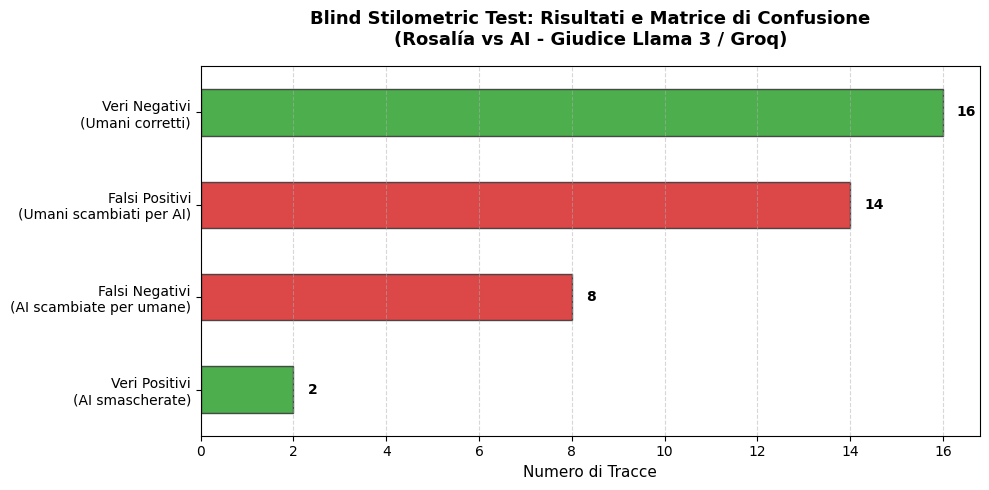

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

📊 Grafico generato con successo e scaricato sul computer!


In [ ]:
import json
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import files

# Dati delle metriche estratti dal report del blind test
dati_grafico = {
    "Veri Negativi\n(Umani corretti)": 16,
    "Veri Positivi\n(AI smascherate)": 2,
    "Falsi Positivi\n(Umani scambiati per AI)": 14,
    "Falsi Negativi\n(AI scambiate per umane)": 8
}

# Creazione del DataFrame con pandas e ordinamento
serie_dati = pd.Series(dati_grafico).sort_values(ascending=True)

# Configurazione del grafico con matplotlib
fig, ax = plt.subplots(figsize=(10, 5))

# Palette: verde per i verdetti corretti, rosso per gli errori/confusioni
colori = ['#2ca02c' if 'Veri' in k else '#d62728' for k in serie_dati.index]
serie_dati.plot(kind='barh', ax=ax, color=colori, edgecolor='#333333', alpha=0.85)

ax.set_title("Blind Stilometric Test: Risultati e Matrice di Confusione\n(Rosalía vs AI - Giudice Llama 3 / Groq)", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Numero di Tracce", fontsize=11)
ax.set_ylabel("", fontsize=11)
ax.grid(axis='x', linestyle='--', alpha=0.5)

# Inserisce i valori numerici sulle barre
for index, value in enumerate(serie_dati):
    ax.text(value + 0.3, index, str(value), va='center', fontweight='bold', fontsize=10)

fig.tight_layout()

# Salvataggio in locale su Colab e download automatico sul computer
nome_file = "grafico_blind_test.png"
fig.savefig(nome_file, dpi=200)
plt.show()

files.download(nome_file)
print("📊 Grafico generato con successo e scaricato sul computer!")

Con questo script calcolo e stampo i valori esatti di Accuracy, Precision e Recall ricavati dai dati visibili nel  (16 Veri Negativi, 14 Falsi Positivi, 8 Falsi Negativi, 2 Veri Positivi):

In [ ]:
# Estrazione dei valori dalla matrice di confusione
tn = 16  # Veri Negativi (Umani corretti)
fp = 14  # Falsi Positivi (Umani scambiati per AI)
fn = 8   # Falsi Negativi (AI scambiate per umane)
tp = 2   # Veri Positivi (AI smascherate)

totale = tn + fp + fn + tp

# Calcolo metriche
accuracy = (tp + tn) / totale
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0

# Stampa dei risultati formattati
print("==========================================")
print(" METRICHE DI VALUTAZIONE - BLIND TEST")
print("==========================================")
print(f" Accuracy:  {accuracy:.4f} ({accuracy * 100:.1f}%)")
print(f" Precision: {precision:.4f}")
print(f" Recall:    {recall:.4f}")
print("==========================================")

 METRICHE DI VALUTAZIONE - BLIND TEST
 Accuracy:  0.4500 (45.0%)
 Precision: 0.1250
 Recall:    0.2000


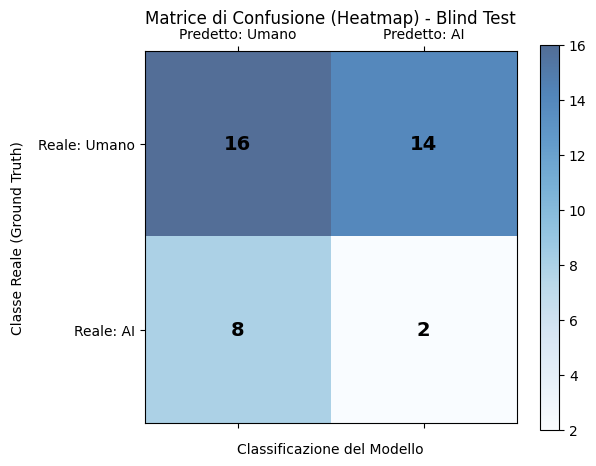

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Dati della matrice (Veri Negativi, Falsi Positivi, Falsi Negativi, Veri Positivi)
# Struttura matrice: [[TN, FP], [FN, TP]]
conf_matrix = np.array([[16, 14],
                        [8, 2]])

fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.matshow(conf_matrix, cmap=plt.cm.Blues, alpha=0.7)

for (i, j), val in np.ndenumerate(conf_matrix):
    ax.text(j, i, f'{val}', ha='center', va='center', fontsize=14, fontweight='bold')

plt.title('Matrice di Confusione (Heatmap) - Blind Test', fontsize=12, pad=20)
fig.colorbar(cax)
plt.xticks([0, 1], ['Predetto: Umano', 'Predetto: AI'])
plt.yticks([0, 1], ['Reale: Umano', 'Reale: AI'])
plt.xlabel('Classificazione del Modello', labelpad=10)
plt.ylabel('Classe Reale (Ground Truth)', labelpad=10)
plt.show()

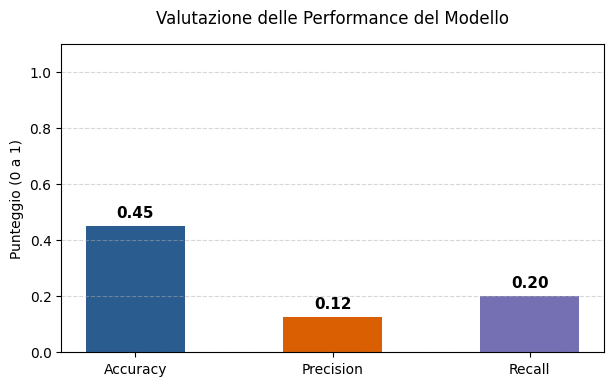

In [ ]:
# Calcoli metriche
tn, fp, fn, tp = 16, 14, 8, 2
totale = tn + fp + fn + tp

accuracy = (tp + tn) / totale
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0

# Dati per il grafico
metriche = ['Accuracy', 'Precision', 'Recall']
valori = [accuracy, precision, recall]
colori = ['#2b5c8f', '#d95f02', '#7570b3']

fig, ax = plt.subplots(figsize=(7, 4))
barre = ax.bar(metriche, valori, color=colori, width=0.5)

# Aggiunge i valori sopra le barre
for barra in barre:
    altezza = barra.get_height()
    ax.text(barra.get_x() + barra.get_width()/2., altezza + 0.02,
            f'{altezza:.2f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_ylim(0, 1.1)
plt.title('Valutazione delle Performance del Modello', fontsize=12, pad=15)
plt.ylabel('Punteggio (0 a 1)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [ ]:
whos

Variable   Type      Data/Info
------------------------------
TSNE       type      <class 'sklearn.manifold._t_sne.TSNE'>
pd         module    <module 'pandas' from '/u<...>ages/pandas/__init__.py'>
plt        module    <module 'matplotlib.pyplo<...>es/matplotlib/pyplot.py'>
sns        module    <module 'seaborn' from '/<...>ges/seaborn/__init__.py'>


Questo blocco esegue una visualizzazione dello spazio vettoriale per confrontare le classi reali con le predizioni del modello. L'analisi è fondamentale per mostrare graficamente l'opacità della "Black Box": la sovrapposizione caotica dei punti dimostra che i vettori superficiali non colgono la semantica d'autore, giustificando le metriche di errore e offrendo una solida base per la discussione critica dei risultati.

In [ ]:
import json
import os
from google.colab import drive

drive.mount("/content/drive", force_remount=False)
cartella_drive = "/content/drive/MyDrive/Progetto-Rosalia"

percorso_report = os.path.join(cartella_drive, "report_valutazione_finale.json")
percorso_txt = os.path.join(cartella_drive, "analisi_qualitativa_errori.txt")
percorso_json_errori = os.path.join(
    cartella_drive, "analisi_qualitativa_errori.json"
)

with open(percorso_report, "r", encoding="utf-8") as f:
  report = json.load(f)

falsi_positivi = []
falsi_negativi = []
righe_txt = []

righe_txt.append("--- FALSI POSITIVI (Rosalía scambiata per AI) ---\n")
for item in report["dettaglio"]:
  if (
      item["origine_reale"] == "ORIGINALE_ROSALIA"
      and item["giudizio_groq"] == "GENERATO_AI"
  ):
    falsi_positivi.append(item)
    righe_txt.append(
        f"• {item['codice_traccia']} ({item['titolo_reale']}):"
        f" {item['motivazione']}\n"
    )

righe_txt.append("\n--- FALSI NEGATIVI (AI scambiata per Rosalía) ---\n")
for item in report["dettaglio"]:
  if (
      item["origine_reale"] == "GENERATO_AI"
      and item["giudizio_groq"] == "UMANO"
  ):
    falsi_negativi.append(item)
    righe_txt.append(
        f"• {item['codice_traccia']} ({item['titolo_reale']}):"
        f" {item['motivazione']}\n"
    )

# Stampa a schermo
testo_completo = "\n".join(righe_txt)
print(testo_completo)

# Salvataggio TXT su Drive
with open(percorso_txt, "w", encoding="utf-8") as f:
  f.write(testo_completo)

# Salvataggio JSON formattato su Drive
payload_errori = {
    "conteggi": {
        "falsi_positivi": len(falsi_positivi),
        "falsi_negativi": len(falsi_negativi),
    },
    "falsi_positivi": falsi_positivi,
    "falsi_negativi": falsi_negativi,
}
with open(percorso_json_errori, "w", encoding="utf-8") as f:
  json.dump(payload_errori, f, ensure_ascii=False, indent=4)

print(f"\n✅ Salvati su Drive:\n- {percorso_txt}\n- {percorso_json_errori}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
--- FALSI POSITIVI (Rosalía scambiata per AI) ---

• Traccia_02 (Traccia_4): Il testo presenta ripetizioni meccaniche (es. 'scared' e 'fear' elencati decine di volte, frasi identiche come 'ego sum nihil ego sum lux mundi'), strutture iper‑regolari e salti tematici incoerenti tipici di un modello linguistico, più che di una composizione umana consapevole.

• Traccia_03 (Traccia_11): Il testo mostra una struttura ricorsiva e iper‑regolare ("X cabe en Y", "X occupies Y") ripetuta meccanicamente, mescolando lingue e riferimenti senza coesione tematica tipica di un flusso di coscienza umano; la mancanza di punteggiatura e le transizioni brusche indicano un pattern algoritmico più che una scrittura spontanea.

• Traccia_05 (Traccia_26): Il testo presenta ripetizioni meccaniche (la stessa frase inglese ripetuta più volte), mescolanza incoerente di spagnolo e inglese

Questo script carica dataset_misto_anonimo.json, chiave_verita_riservata.json e report_valutazione_finale.json, calcola i vettori TF-IDF sui 40 testi veri e mostra sia la Classe Reale sia l'Esito del Blind Test (TN, TP, FP, FN), salvando il grafico anche su Drive

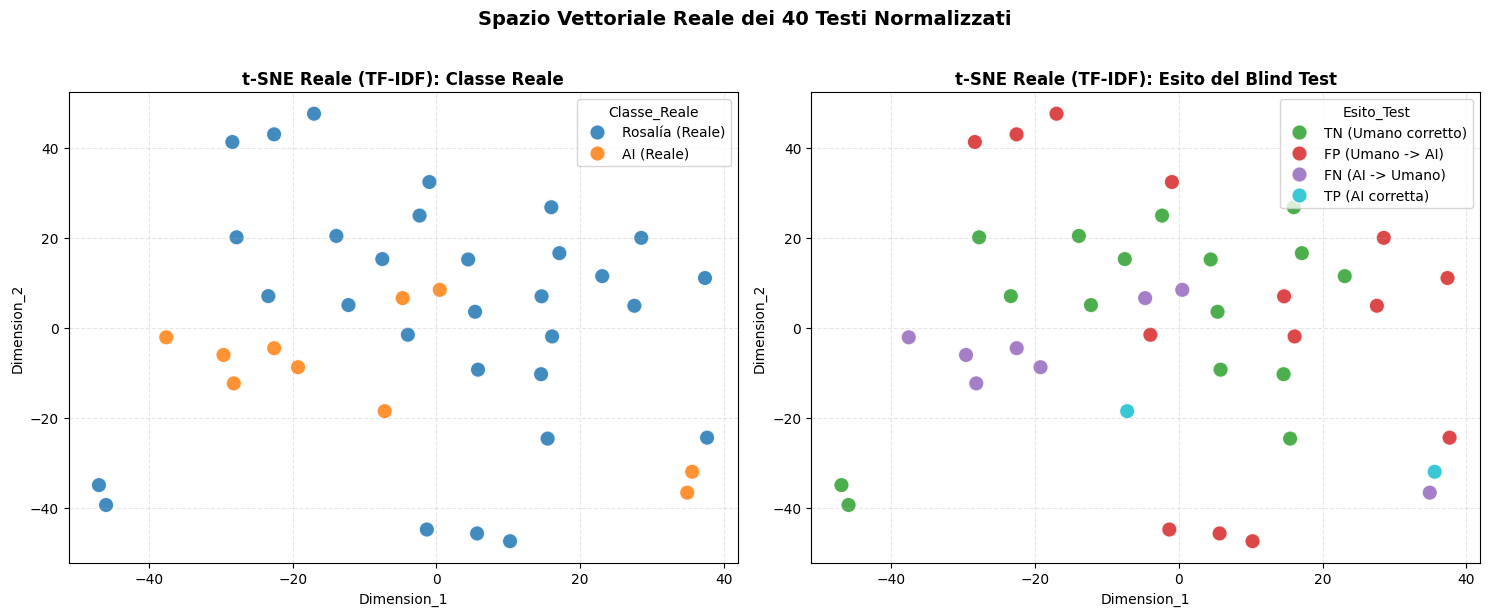

📊 Grafico t-SNE reale salvato in: /content/drive/MyDrive/Progetto-Rosalia/tsne_reale_blind_test.png


In [ ]:
import json
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE

cartella_drive = "/content/drive/MyDrive/Progetto-Rosalia"
percorso_dataset = os.path.join(cartella_drive, "dataset_misto_anonimo.json")
percorso_chiave = os.path.join(cartella_drive, "chiave_verita_riservata.json")
percorso_report = os.path.join(cartella_drive, "report_valutazione_finale.json")

with open(percorso_dataset, "r", encoding="utf-8") as f:
  dataset_raw = json.load(f)

with open(percorso_chiave, "r", encoding="utf-8") as f:
  chiave_raw = json.load(f)

with open(percorso_report, "r", encoding="utf-8") as f:
  report = json.load(f)


# Funzione di supporto per estrarre il testo indipendentemente dal nome della chiave
def estrai_testo(record):
  for chiave in [
      "testo_normalizzato",
      "testo",
      "lyrics",
      "contenuto",
      "brano",
  ]:
    if chiave in record and isinstance(record[chiave], str):
      return record[chiave]
  # Fallback: prende la stringa più lunga presente nel dizionario
  valori_str = [v for v in record.values() if isinstance(v, str)]
  return max(valori_str, key=len) if valori_str else ""


# Normalizza il dataset in lista di record
if isinstance(dataset_raw, dict):
  lista_dataset = [
      {"codice_traccia": k, **(v if isinstance(v, dict) else {"testo": v})}
      for k, v in dataset_raw.items()
  ]
else:
  lista_dataset = dataset_raw

diz_testi = {
    item.get("codice_traccia", item.get("codice", f"Traccia_{i+1:02d}")): (
        estrai_testo(item)
    )
    for i, item in enumerate(lista_dataset)
}

diz_verita = {item["codice_traccia"]: item for item in chiave_raw}
diz_dettaglio = {item["codice_traccia"]: item for item in report["dettaglio"]}

codici = list(diz_verita.keys())
testi = [diz_testi.get(c, "") for c in codici]

# Vettorizzazione TF-IDF reale sui 40 testi
vectorizer = TfidfVectorizer(max_features=2000)
X_tfidf = vectorizer.fit_transform(testi).toarray()

# t-SNE con perplexity sicura per n_samples = 40
perplessita = min(5, max(2, len(codici) - 1))
tsne = TSNE(
    n_components=2, random_state=42, perplexity=perplessita, init="pca"
)
coords = tsne.fit_transform(X_tfidf)

righe_df = []
for idx, c in enumerate(codici):
  origine = diz_verita[c]["origine_reale"]
  det = diz_dettaglio.get(c, {})
  pred = det.get("giudizio_groq", "N/D")

  is_ai_reale = origine == "GENERATO_AI"
  is_ai_pred = pred == "GENERATO_AI"

  if is_ai_reale and is_ai_pred:
    esito = "TP (AI corretta)"
  elif (not is_ai_reale) and (not is_ai_pred):
    esito = "TN (Umano corretto)"
  elif (not is_ai_reale) and is_ai_pred:
    esito = "FP (Umano -> AI)"
  else:
    esito = "FN (AI -> Umano)"

  righe_df.append({
      "codice_traccia": c,
      "Dimension_1": coords[idx, 0],
      "Dimension_2": coords[idx, 1],
      "Classe_Reale": "AI (Reale)" if is_ai_reale else "Rosalía (Reale)",
      "Esito_Test": esito,
  })

df_tsne = pd.DataFrame(righe_df)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=df_tsne,
    x="Dimension_1",
    y="Dimension_2",
    hue="Classe_Reale",
    palette={"Rosalía (Reale)": "#1f77b4", "AI (Reale)": "#ff7f0e"},
    s=120,
    alpha=0.85,
    ax=axes[0],
)
axes[0].set_title(
    "t-SNE Reale (TF-IDF): Classe Reale", fontsize=12, fontweight="bold"
)
axes[0].grid(True, linestyle="--", alpha=0.3)

sns.scatterplot(
    data=df_tsne,
    x="Dimension_1",
    y="Dimension_2",
    hue="Esito_Test",
    palette={
        "TN (Umano corretto)": "#2ca02c",
        "TP (AI corretta)": "#17becf",
        "FP (Umano -> AI)": "#d62728",
        "FN (AI -> Umano)": "#9467bd",
    },
    s=120,
    alpha=0.85,
    ax=axes[1],
)
axes[1].set_title(
    "t-SNE Reale (TF-IDF): Esito del Blind Test", fontsize=12, fontweight="bold"
)
axes[1].grid(True, linestyle="--", alpha=0.3)

plt.suptitle(
    "Spazio Vettoriale Reale dei 40 Testi Normalizzati",
    fontsize=14,
    y=1.02,
    fontweight="bold",
)
plt.tight_layout()

percorso_tsne_png = os.path.join(cartella_drive, "tsne_reale_blind_test.png")
fig.savefig(percorso_tsne_png, dpi=200, bbox_inches="tight")
plt.show()
print(f"📊 Grafico t-SNE reale salvato in: {percorso_tsne_png}")

Pannello di sinistra: t-SNE Reale (TF-IDF): Classe RealeMostra la verità oggettiva (ground truth): i brani originali di Rosalía (in blu) e i brani generati dall'AI (in arancione).I punti arancioni non formano un blocco compatto o isolato, ma risultano sparsi e intrecciati con quelli blu lungo lo spazio 2D. Sul piano del vocabolario ponderato (TF-IDF) e dopo la normalizzazione, i testi generati non hanno una "firma lessicale" separata rispetto ai brani di Rosalía; si mescolano con essi. Pannello di destra: t-SNE Reale (TF-IDF): Esito del Blind Test mostra come è andata la classificazione del giudice LLM sui singoli punti .Anche qui i diversi esiti sono mescolati nello spazio: i punti viola (FN, testi AI scambiati per umani) e rossi (FP, testi di Rosalía scambiati per AI) compaiono in varie zone vicino ai verdetti corretti.

# Fase 6: Comparazione corpus

script Python pronto per Colab che calcola le principali metriche quantitative sui tuoi 40 testi normalizzati, raggruppandole sia per esito del blind test (TN, TP, FP, FN) sia per classe reale (ORIGINALE_ROSALIA vs GENERATO_AI), e salva anche un file JSON di riepilogo su Google Drive.

In [ ]:
from collections import Counter
import json
import os
import numpy as np
import pandas as pd

cartella_drive = "/content/drive/MyDrive/Progetto-Rosalia"
percorso_dataset = os.path.join(cartella_drive, "dataset_misto_anonimo.json")
percorso_chiave = os.path.join(cartella_drive, "chiave_verita_riservata.json")
percorso_report = os.path.join(cartella_drive, "report_valutazione_finale.json")
percorso_out_json = os.path.join(
    cartella_drive, "comparazione_quantitativa_fase4.json"
)

with open(percorso_dataset, "r", encoding="utf-8") as f:
  dataset_raw = json.load(f)
with open(percorso_chiave, "r", encoding="utf-8") as f:
  chiave_raw = json.load(f)
with open(percorso_report, "r", encoding="utf-8") as f:
  report = json.load(f)


def estrai_testo(record):
  for chiave in [
      "testo_normalizzato",
      "testo",
      "lyrics",
      "contenuto",
      "brano",
  ]:
    if chiave in record and isinstance(record[chiave], str):
      return record[chiave]
  valori_str = [v for v in record.values() if isinstance(v, str)]
  return max(valori_str, key=len) if valori_str else ""


if isinstance(dataset_raw, dict):
  lista_dataset = [
      {"codice_traccia": k, **(v if isinstance(v, dict) else {"testo": v})}
      for k, v in dataset_raw.items()
  ]
else:
  lista_dataset = dataset_raw

diz_testi = {
    item.get("codice_traccia", item.get("codice", f"Traccia_{i+1:02d}")): (
        estrai_testo(item)
    )
    for i, item in enumerate(lista_dataset)
}
diz_verita = {item["codice_traccia"]: item for item in chiave_raw}
diz_dettaglio = {item["codice_traccia"]: item for item in report["dettaglio"]}


def metriche_testo(testo):
  tokens = testo.lower().split()
  n_token = len(tokens)
  if n_token == 0:
    return {
        "n_token": 0,
        "n_type": 0,
        "ttr": 0.0,
        "rapporto_token_ripetuti": 0.0,
        "rapporto_bigrammi_ripetuti": 0.0,
    }

  conteggi_token = Counter(tokens)
  n_type = len(conteggi_token)
  ttr = n_type / n_token

  # Quota di occorrenze che appartengono a token ripetuti almeno 2 volte nel brano
  token_ripetuti_occ = sum(c for c in conteggi_token.values() if c > 1)
  rapporto_token_ripetuti = token_ripetuti_occ / n_token

  # Quota di bigrammi ripetuti almeno 2 volte dentro lo stesso brano
  if n_token >= 2:
    bigrammi = list(zip(tokens[:-1], tokens[1:]))
    conteggi_bi = Counter(bigrammi)
    bi_ripetuti_occ = sum(c for c in conteggi_bi.values() if c > 1)
    rapporto_bigrammi_ripetuti = bi_ripetuti_occ / len(bigrammi)
  else:
    rapporto_bigrammi_ripetuti = 0.0

  return {
      "n_token": n_token,
      "n_type": n_type,
      "ttr": round(ttr, 4),
      "rapporto_token_ripetuti": round(rapporto_token_ripetuti, 4),
      "rapporto_bigrammi_ripetuti": round(rapporto_bigrammi_ripetuti, 4),
  }


righe = []
for codice, verita in diz_verita.items():
  testo = diz_testi.get(codice, "")
  m = metriche_testo(testo)
  origine = verita["origine_reale"]
  pred = diz_dettaglio.get(codice, {}).get("giudizio_groq", "N/D")

  is_ai_reale = origine == "GENERATO_AI"
  is_ai_pred = pred == "GENERATO_AI"

  if is_ai_reale and is_ai_pred:
    esito = "TP"
  elif (not is_ai_reale) and (not is_ai_pred):
    esito = "TN"
  elif (not is_ai_reale) and is_ai_pred:
    esito = "FP"
  else:
    esito = "FN"

  righe.append({
      "codice_traccia": codice,
      "titolo_reale": verita.get("titolo_reale", "N/D"),
      "origine_reale": origine,
      "giudizio_groq": pred,
      "esito": esito,
      **m,
  })

df_metrics = pd.DataFrame(righe)

riepilogo_esito = df_metrics.groupby("esito").agg(
    n_tracce=("codice_traccia", "count"),
    media_token=("n_token", "mean"),
    mediana_token=("n_token", "median"),
    media_ttr=("ttr", "mean"),
    media_tok_rip=("rapporto_token_ripetuti", "mean"),
    media_bi_rip=("rapporto_bigrammi_ripetuti", "mean"),
).round(3)

riepilogo_origine = df_metrics.groupby("origine_reale").agg(
    n_tracce=("codice_traccia", "count"),
    media_token=("n_token", "mean"),
    mediana_token=("n_token", "median"),
    media_ttr=("ttr", "mean"),
    media_tok_rip=("rapporto_token_ripetuti", "mean"),
    media_bi_rip=("rapporto_bigrammi_ripetuti", "mean"),
).round(3)

print("=== RIEPILOGO PER ESITO (TN, TP, FP, FN) ===")
print(riepilogo_esito)
print("\n=== RIEPILOGO PER CLASSE REALE ===")
print(riepilogo_origine)

with open(percorso_out_json, "w", encoding="utf-8") as f:
  json.dump(
      {
          "riepilogo_per_esito": riepilogo_esito.reset_index().to_dict(
              orient="records"
          ),
          "riepilogo_per_origine": riepilogo_origine.reset_index().to_dict(
              orient="records"
          ),
          "dettaglio_metriche": righe,
      },
      f,
      ensure_ascii=False,
      indent=4,
  )

print(f"\n✅ Salvato in: {percorso_out_json}")

=== RIEPILOGO PER ESITO (TN, TP, FP, FN) ===
       n_tracce  media_token  mediana_token  media_ttr  media_tok_rip  \
esito                                                                   
FN            8      239.750          216.5      0.650          0.479   
FP           14      220.500          199.5      0.422          0.752   
TN           16      258.188          231.0      0.448          0.723   
TP            2      230.500          230.5      0.524          0.662   

       media_bi_rip  
esito                
FN            0.117  
FP            0.547  
TN            0.438  
TP            0.387  

=== RIEPILOGO PER CLASSE REALE ===
                   n_tracce  media_token  mediana_token  media_ttr  \
origine_reale                                                        
GENERATO_AI              10        237.9          216.5      0.625   
ORIGINALE_ROSALIA        30        240.6          222.5      0.436   

                   media_tok_rip  media_bi_rip  
origine_reale     

Questo output conferma in modo molto chiaro il paradosso emerso nel blind test: il corpus reale di Rosalía ha una ripetitività interna media più alta rispetto ai testi generati dall'AI, ed è proprio questo a guidare gran parte degli errori del giudice LLM.
Lunghezza simile: i testi generati dall'AI (10 tracce) hanno una media di 237,9 token (mediana 216,5), quasi identica a quella dei brani originali di Rosalía (30 tracce), che hanno 240,6 token (mediana 222,5). La lunghezza non è quindi un elemento che separa nettamente i due gruppi.Varietà lessicale (media_ttr): i testi generati dall'AI mostrano un TTR medio più alto (0,625) rispetto a quelli di Rosalía (0,436), indicando che in media usano una quota maggiore di parole diverse rispetto al totale dei token.Ripetitività interna (media_tok_rip e media_bi_rip): qui c'è la differenza più netta. I testi originali di Rosalía hanno 0,737 di token ripetuti e 0,489 di bigrammi ripetuti, contro 0,516 e 0,171 dei brani generati dall'AI. In altre parole, i brani reali contengono molte più ripetizioni interne (ritornelli, formule, parole o sequenze ricorrenti) rispetto ai testi sintetici.

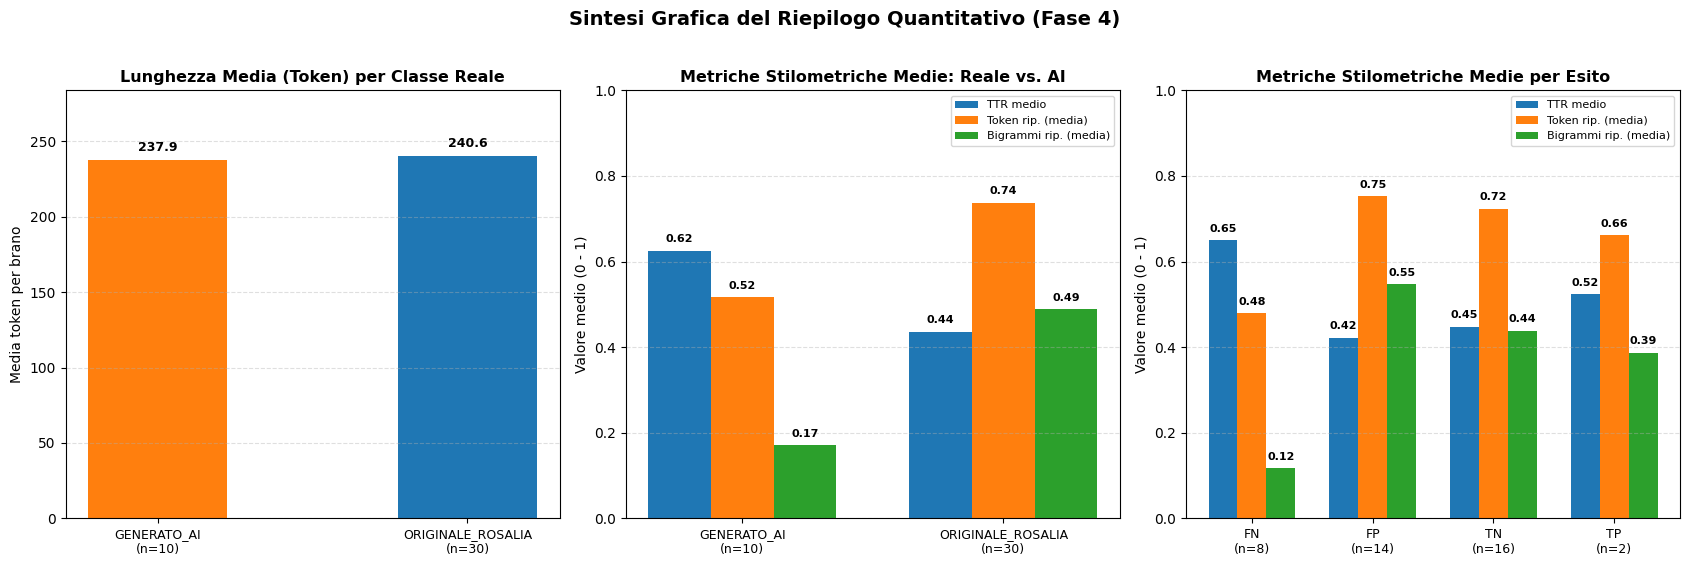

📊 Grafico di sintesi salvato in: /content/drive/MyDrive/Progetto-Rosalia/riepilogo_quantitativo_sintesi_fase4.png


In [ ]:
import json
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

cartella_drive = "/content/drive/MyDrive/Progetto-Rosalia"
percorso_json = os.path.join(
    cartella_drive, "comparazione_quantitativa_fase4.json"
)

with open(percorso_json, "r", encoding="utf-8") as f:
  dati = json.load(f)

df_origine = pd.DataFrame(dati["riepilogo_per_origine"])
df_esito = pd.DataFrame(dati["riepilogo_per_esito"])

ordine_esiti = ["FN", "FP", "TN", "TP"]
df_esito["esito"] = pd.Categorical(
    df_esito["esito"], categories=ordine_esiti, ordered=True
)
df_esito = df_esito.sort_values("esito")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))

# --- Pannello 1: Media Token per Classe Reale ---
x_o = np.arange(len(df_origine))
b_tok = axes[0].bar(
    x_o,
    df_origine["media_token"],
    width=0.45,
    color=["#ff7f0e", "#1f77b4"],
)
axes[0].set_title(
    "Lunghezza Media (Token) per Classe Reale", fontsize=11.5, fontweight="bold"
)
axes[0].set_xticks(x_o)
axes[0].set_xticklabels(
    [
        f"{r['origine_reale']}\n(n={r['n_tracce']})"
        for _, r in df_origine.iterrows()
    ],
    fontsize=9,
)
axes[0].set_ylabel("Media token per brano")
axes[0].set_ylim(0, df_origine["media_token"].max() * 1.18)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

for b in b_tok:
  h = b.get_height()
  axes[0].text(
      b.get_x() + b.get_width() / 2,
      h + 4,
      f"{h:.1f}",
      ha="center",
      va="bottom",
      fontsize=9,
      fontweight="bold",
  )

# --- Pannello 2: Metriche Normalizzate Medie per Classe Reale ---
w2 = 0.24
m_ttr = axes[1].bar(
    x_o - w2,
    df_origine["media_ttr"],
    width=w2,
    label="TTR medio",
    color="#1f77b4",
)
m_tok = axes[1].bar(
    x_o,
    df_origine["media_tok_rip"],
    width=w2,
    label="Token rip. (media)",
    color="#ff7f0e",
)
m_bi = axes[1].bar(
    x_o + w2,
    df_origine["media_bi_rip"],
    width=w2,
    label="Bigrammi rip. (media)",
    color="#2ca02c",
)

axes[1].set_title(
    "Metriche Stilometriche Medie: Reale vs. AI",
    fontsize=11.5,
    fontweight="bold",
)
axes[1].set_xticks(x_o)
axes[1].set_xticklabels(
    [
        f"{r['origine_reale']}\n(n={r['n_tracce']})"
        for _, r in df_origine.iterrows()
    ],
    fontsize=9,
)
axes[1].set_ylabel("Valore medio (0 - 1)")
axes[1].set_ylim(0, 1.0)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
axes[1].legend(loc="upper right", fontsize=8)

for barre in (m_ttr, m_tok, m_bi):
  for b in barre:
    h = b.get_height()
    axes[1].text(
        b.get_x() + b.get_width() / 2,
        h + 0.015,
        f"{h:.2f}",
        ha="center",
        va="bottom",
        fontsize=8,
        fontweight="bold",
    )

# --- Pannello 3: Metriche Normalizzate Medie per Esito del Test ---
x_e = np.arange(len(df_esito))
w3 = 0.24
e_ttr = axes[2].bar(
    x_e - w3,
    df_esito["media_ttr"],
    width=w3,
    label="TTR medio",
    color="#1f77b4",
)
e_tok = axes[2].bar(
    x_e,
    df_esito["media_tok_rip"],
    width=w3,
    label="Token rip. (media)",
    color="#ff7f0e",
)
e_bi = axes[2].bar(
    x_e + w3,
    df_esito["media_bi_rip"],
    width=w3,
    label="Bigrammi rip. (media)",
    color="#2ca02c",
)

axes[2].set_title(
    "Metriche Stilometriche Medie per Esito", fontsize=11.5, fontweight="bold"
)
axes[2].set_xticks(x_e)
axes[2].set_xticklabels(
    [f"{r['esito']}\n(n={r['n_tracce']})" for _, r in df_esito.iterrows()],
    fontsize=9,
)
axes[2].set_ylabel("Valore medio (0 - 1)")
axes[2].set_ylim(0, 1.0)
axes[2].grid(axis="y", linestyle="--", alpha=0.4)
axes[2].legend(loc="upper right", fontsize=8)

for barre in (e_ttr, e_tok, e_bi):
  for b in barre:
    h = b.get_height()
    axes[2].text(
        b.get_x() + b.get_width() / 2,
        h + 0.015,
        f"{h:.2f}",
        ha="center",
        va="bottom",
        fontsize=8,
        fontweight="bold",
    )

plt.suptitle(
    "Sintesi Grafica del Riepilogo Quantitativo (Fase 4)",
    fontsize=14,
    y=1.02,
    fontweight="bold",
)
plt.tight_layout()

percorso_png = os.path.join(
    cartella_drive, "riepilogo_quantitativo_sintesi_fase4.png"
)
fig.savefig(percorso_png, dpi=200, bbox_inches="tight")
plt.show()
print(f"📊 Grafico di sintesi salvato in: {percorso_png}")

In questo blocco carichiamo le metriche quantitative già salvate in comparazione_quantitativa_fase4.json e creiamo due grafici complementari (un grafico a barre raggruppate per esito e uno scatter plot Ripetizione di bigrammi vs. TTR). Vogliamo dimostrare quantitativamente che il giudice LLM tende a classificare come GENERATO_AI (Falsi Positivi) i brani con maggiore ripetitività interna e minore varietà lessicale (molti testi reali di Rosalía), mentre scambia per UMANO (Falsi Negativi) testi AI con bassa ripetizione di bigrammi e TTR più elevato.

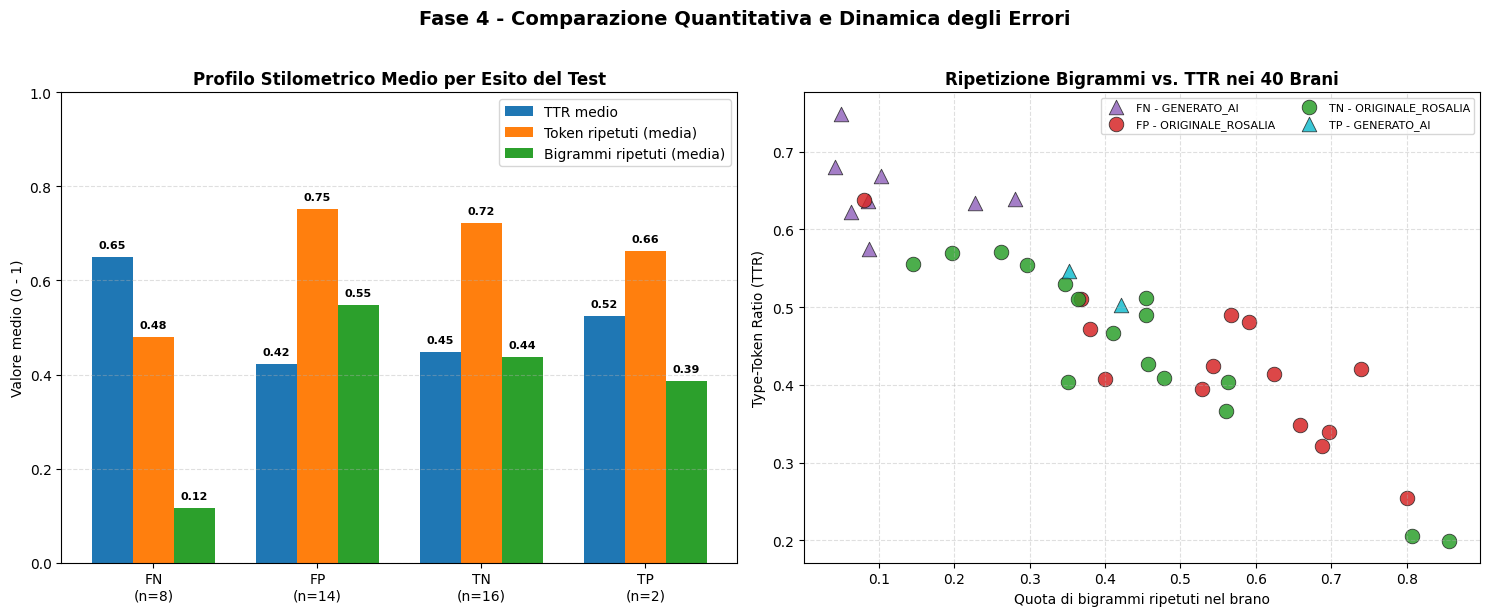

📊 Grafico salvato in: /content/drive/MyDrive/Progetto-Rosalia/comparazione_quantitativa_fase4.png


In [ ]:
import json
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

cartella_drive = "/content/drive/MyDrive/Progetto-Rosalia"
percorso_json = os.path.join(
    cartella_drive, "comparazione_quantitativa_fase4.json"
)

with open(percorso_json, "r", encoding="utf-8") as f:
  dati = json.load(f)

df_esito = pd.DataFrame(dati["riepilogo_per_esito"])
df_dettaglio = pd.DataFrame(dati["dettaglio_metriche"])

# Ordine leggibile degli esiti
ordine_esiti = ["FN", "FP", "TN", "TP"]
df_esito["esito"] = pd.Categorical(
    df_esito["esito"], categories=ordine_esiti, ordered=True
)
df_esito = df_esito.sort_values("esito")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- GRAFICO 1: Barre raggruppate per esito ---
x = np.arange(len(df_esito))
larghezza = 0.25

b1 = axes[0].bar(
    x - larghezza,
    df_esito["media_ttr"],
    width=larghezza,
    label="TTR medio",
    color="#1f77b4",
)
b2 = axes[0].bar(
    x,
    df_esito["media_tok_rip"],
    width=larghezza,
    label="Token ripetuti (media)",
    color="#ff7f0e",
)
b3 = axes[0].bar(
    x + larghezza,
    df_esito["media_bi_rip"],
    width=larghezza,
    label="Bigrammi ripetuti (media)",
    color="#2ca02c",
)

axes[0].set_title(
    "Profilo Stilometrico Medio per Esito del Test",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xticks(x)
axes[0].set_xticklabels(
    [
        f"{r['esito']}\n(n={r['n_tracce']})"
        for _, r in df_esito.iterrows()
    ]
)
axes[0].set_ylim(0, 1.0)
axes[0].set_ylabel("Valore medio (0 - 1)")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
axes[0].legend(loc="upper right")

for barre in [b1, b2, b3]:
  for barra in barre:
    h = barra.get_height()
    axes[0].text(
        barra.get_x() + barra.get_width() / 2,
        h + 0.015,
        f"{h:.2f}",
        ha="center",
        va="bottom",
        fontsize=8,
        fontweight="bold",
    )

# --- GRAFICO 2: Scatter plot Bigrammi ripetuti vs TTR ---
palette_esito = {
    "TN": "#2ca02c",
    "TP": "#17becf",
    "FP": "#d62728",
    "FN": "#9467bd",
}
marker_origine = {"ORIGINALE_ROSALIA": "o", "GENERATO_AI": "^"}

for esito in ordine_esiti:
  sub_esito = df_dettaglio[df_dettaglio["esito"] == esito]
  for origine, marker in marker_origine.items():
    sub = sub_esito[sub_esito["origine_reale"] == origine]
    if len(sub) > 0:
      axes[1].scatter(
          sub["rapporto_bigrammi_ripetuti"],
          sub["ttr"],
          c=palette_esito[esito],
          marker=marker,
          s=110,
          alpha=0.85,
          edgecolors="#222222",
          linewidths=0.6,
          label=f"{esito} - {origine}",
      )

axes[1].set_title(
    "Ripetizione Bigrammi vs. TTR nei 40 Brani", fontsize=12, fontweight="bold"
)
axes[1].set_xlabel("Quota di bigrammi ripetuti nel brano")
axes[1].set_ylabel("Type-Token Ratio (TTR)")
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend(loc="best", fontsize=8, ncol=2)

plt.suptitle(
    "Fase 4 - Comparazione Quantitativa e Dinamica degli Errori",
    fontsize=14,
    y=1.02,
    fontweight="bold",
)
plt.tight_layout()

percorso_png = os.path.join(cartella_drive, "comparazione_quantitativa_fase4.png")
fig.savefig(percorso_png, dpi=200, bbox_inches="tight")
plt.show()
print(f"📊 Grafico salvato in: {percorso_png}")

non è solo una "sovrapposizione generica" tra testi reali e sintetici, ma un meccanismo di errore preciso, in cui il giudice penalizza la ripetizione interna (tipica di strofe, ritornelli o iterazioni musicali) come sintomo di AI e associa invece un TTR più alto e meno ripetizioni a una presunta autenticità umana.

In questo blocco carichiamo comparazione_quantitativa_fase4.json e creiamo un boxplot con i singoli punti sovrapposti (strip plot) per confrontare direttamente ORIGINALE_ROSALIA (30 brani) e GENERATO_AI (10 brani) su due variabili chiave: quota di bigrammi ripetuti e Type-Token Ratio (TTR). Vogliamo dimostrare che le medie viste finora non sono frutto di un singolo brano estremo (outlier), ma riflettono una tendenza distributiva: i testi reali di Rosalía si collocano mediamente più in alto nella ripetizione di bigrammi e più in basso nel TTR rispetto ai testi generati dall'AI, creando una sovrapposizione che confonde il giudice LLM.

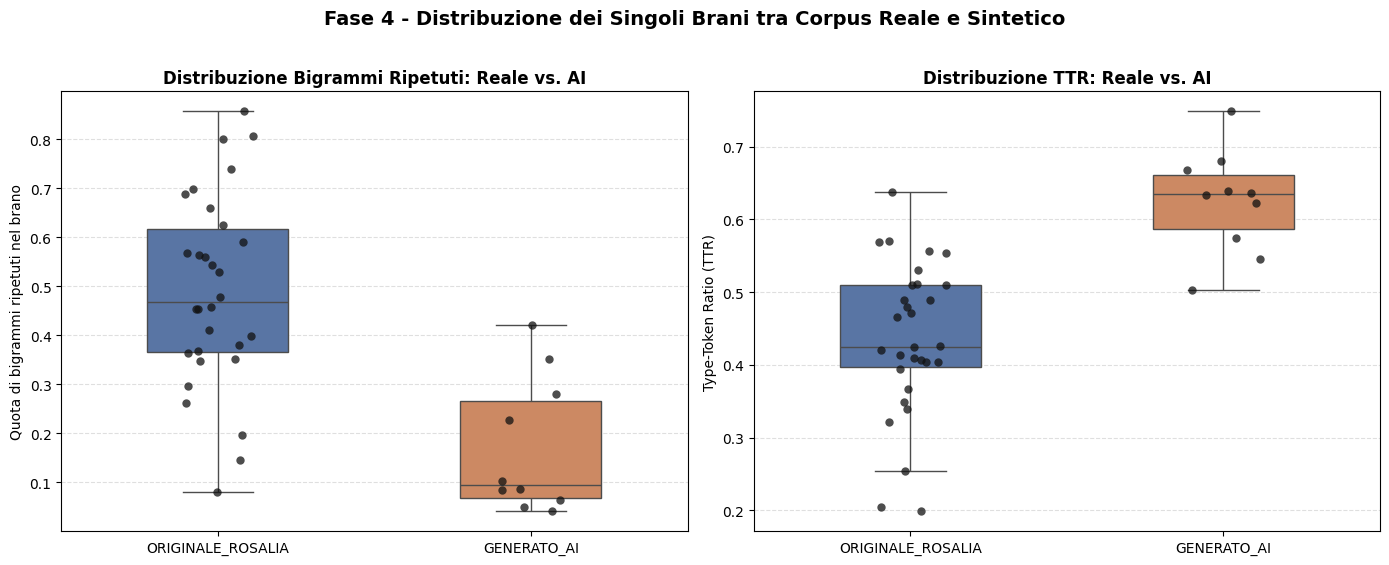

📊 Grafico salvato in: /content/drive/MyDrive/Progetto-Rosalia/boxplot_reale_vs_ai_fase4.png


In [ ]:
import json
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

cartella_drive = "/content/drive/MyDrive/Progetto-Rosalia"
percorso_json = os.path.join(
    cartella_drive, "comparazione_quantitativa_fase4.json"
)

with open(percorso_json, "r", encoding="utf-8") as f:
  dati = json.load(f)

df_dettaglio = pd.DataFrame(dati["dettaglio_metriche"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Pannello 1: Distribuzione Bigrammi ripetuti ---
sns.boxplot(
    data=df_dettaglio,
    x="origine_reale",
    y="rapporto_bigrammi_ripetuti",
    hue="origine_reale",
    palette={
        "ORIGINALE_ROSALIA": "#4c72b0",
        "GENERATO_AI": "#dd8452",
    },
    legend=False,
    width=0.45,
    fliersize=0,
    ax=axes[0],
)
sns.stripplot(
    data=df_dettaglio,
    x="origine_reale",
    y="rapporto_bigrammi_ripetuti",
    color="#111111",
    alpha=0.75,
    size=6,
    jitter=0.12,
    ax=axes[0],
)
axes[0].set_title(
    "Distribuzione Bigrammi Ripetuti: Reale vs. AI",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("")
axes[0].set_ylabel("Quota di bigrammi ripetuti nel brano")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

# --- Pannello 2: Distribuzione TTR ---
sns.boxplot(
    data=df_dettaglio,
    x="origine_reale",
    y="ttr",
    hue="origine_reale",
    palette={
        "ORIGINALE_ROSALIA": "#4c72b0",
        "GENERATO_AI": "#dd8452",
    },
    legend=False,
    width=0.45,
    fliersize=0,
    ax=axes[1],
)
sns.stripplot(
    data=df_dettaglio,
    x="origine_reale",
    y="ttr",
    color="#111111",
    alpha=0.75,
    size=6,
    jitter=0.12,
    ax=axes[1],
)
axes[1].set_title(
    "Distribuzione TTR: Reale vs. AI", fontsize=12, fontweight="bold"
)
axes[1].set_xlabel("")
axes[1].set_ylabel("Type-Token Ratio (TTR)")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.suptitle(
    "Fase 4 - Distribuzione dei Singoli Brani tra Corpus Reale e Sintetico",
    fontsize=14,
    y=1.02,
    fontweight="bold",
)
plt.tight_layout()

percorso_png = os.path.join(cartella_drive, "boxplot_reale_vs_ai_fase4.png")
fig.savefig(percorso_png, dpi=200, bbox_inches="tight")
plt.show()
print(f"📊 Grafico salvato in: {percorso_png}")

Pannello di sinistra: La scatola e la mediana di ORIGINALE_ROSALIA si collocano chiaramente più in alto (intorno a ~0,48–0,50) rispetto a quelle di GENERATO_AI (più in basso, intorno a ~0,15–0,20).I puntini mostrano però che non c'è una separazione netta: alcuni brani di Rosalía hanno meno ripetizioni di bigrammi e scendono nella fascia bassa, mentre un paio di brani generati dall'AI salgono verso valori più alti.Cosa ti dice: conferma che la ripetizione interna è in media più marcata nei testi originali di Rosalía che in quelli generati dall'AI, ma con una certa sovrapposizione tra i due insiemi.2.
Pannello di destra: GENERATO_AI ha una mediana più alta (intorno a ~0,62–0,65), mentre ORIGINALE_ROSALIA ha valori mediamente più bassi (intorno a ~0,43).Anche qui i singoli punti mostrano sovrapposizione: alcuni brani di Rosalía raggiungono TTR più alti (intorno a 0,60–0,70), mentre alcuni testi AI restano più in basso.Cosa ti dice: i testi sintetici tendono in media ad avere una maggiore varietà lessicale relativa (TTR più alto) rispetto alle canzoni reali di Rosalía, che invece ripetono più spesso parole o sequenze.

In questo blocco applichiamo un modello di Topic Modeling (NMF) ai 40 testi normalizzati di dataset_misto_anonimo.json per estrarre 5 macro-temi principali e calcolare il peso medio di ciascun tema nei due gruppi (ORIGINALE_ROSALIA vs GENERATO_AI, oppure anche divisi per esito TN, FP, FN, TP). Vogliamo dimostrare fino a che punto i brani generati dall'AI ricalcano gli stessi nuclei tematici del corpus reale di Rosalía (sovrapposizione semantica) e se alcuni temi specifici sono stati sovra-rappresentati o sotto-rappresentati dal modello generativo.

=== PAROLE CHIAVE EMERSE PER CIASCUN TEMA ===
Tema 1: tú, mundo, quiero, nunca, siempre
Tema 2: lux, és, veni, llum, carne
Tema 3: motomami, alfa, zorra, expensiva, okay
Tema 4: ta, ra, ángeles, aunque, vez
Tema 5: pistón, tacón, too, freno, moto


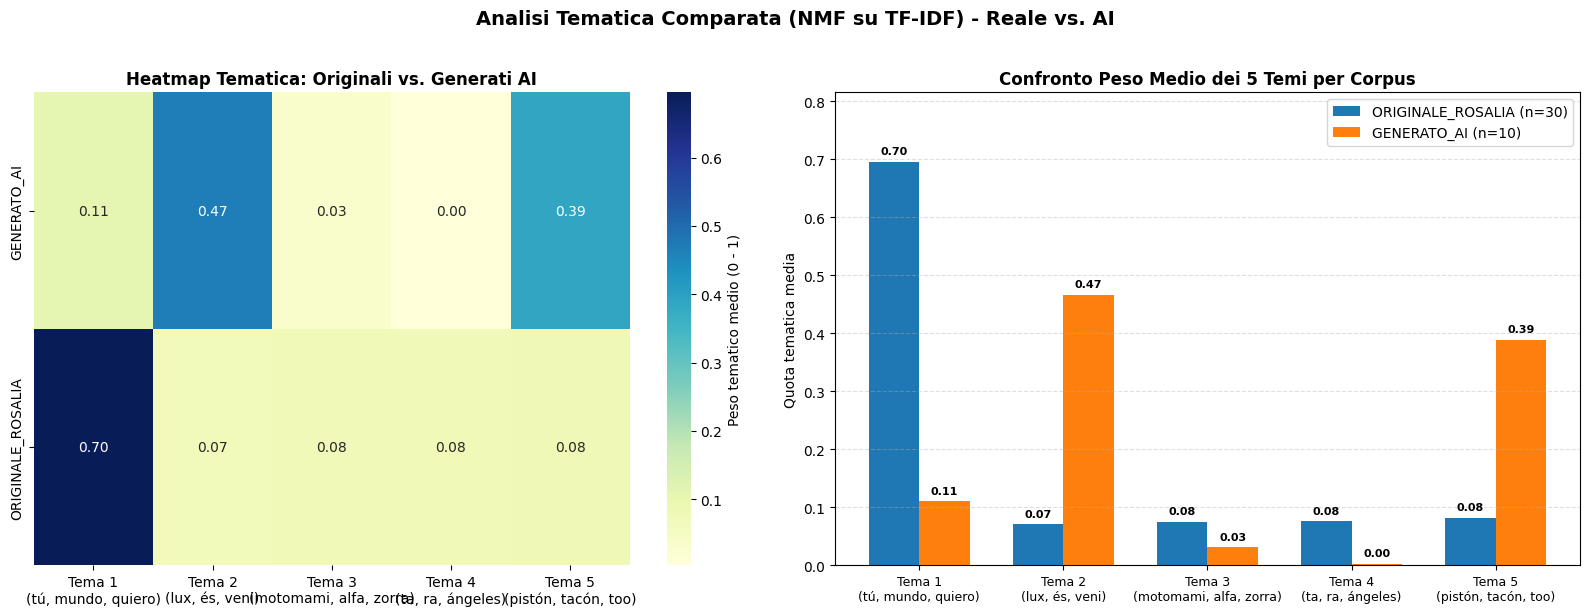


📊 Grafico tematico salvato in: /content/drive/MyDrive/Progetto-Rosalia/comparazione_tematica_nmf_fase4.png


In [ ]:
import json
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

cartella_drive = "/content/drive/MyDrive/Progetto-Rosalia"
percorso_dataset = os.path.join(cartella_drive, "dataset_misto_anonimo.json")
percorso_chiave = os.path.join(cartella_drive, "chiave_verita_riservata.json")

with open(percorso_dataset, "r", encoding="utf-8") as f:
  dataset_raw = json.load(f)
with open(percorso_chiave, "r", encoding="utf-8") as f:
  chiave_raw = json.load(f)


def estrai_testo(record):
  for chiave in [
      "testo_normalizzato",
      "testo",
      "lyrics",
      "contenuto",
      "brano",
  ]:
    if chiave in record and isinstance(record[chiave], str):
      return record[chiave]
  valori_str = [v for v in record.values() if isinstance(v, str)]
  return max(valori_str, key=len) if valori_str else ""


if isinstance(dataset_raw, dict):
  lista_dataset = [
      {"codice_traccia": k, **(v if isinstance(v, dict) else {"testo": v})}
      for k, v in dataset_raw.items()
  ]
else:
  lista_dataset = dataset_raw

diz_testi = {
    item.get("codice_traccia", item.get("codice", f"Traccia_{i+1:02d}")): (
        estrai_testo(item)
    )
    for i, item in enumerate(lista_dataset)
}
diz_verita = {item["codice_traccia"]: item for item in chiave_raw}

codici = list(diz_verita.keys())
testi = [diz_testi.get(c, "") for c in codici]
origini = [diz_verita[c]["origine_reale"] for c in codici]

# Stopwords multilingue essenziali (spagnolo + inglese + italiano) per far emergere parole piene
stopwords_multi = [
    # Spagnolo
    "de",
    "la",
    "que",
    "el",
    "en",
    "y",
    "a",
    "los",
    "del",
    "se",
    "las",
    "por",
    "un",
    "para",
    "con",
    "no",
    "una",
    "su",
    "al",
    "lo",
    "como",
    "más",
    "mas",
    "pero",
    "sus",
    "le",
    "ya",
    "o",
    "este",
    "sí",
    "si",
    "porque",
    "esta",
    "entre",
    "cuando",
    "muy",
    "sin",
    "sobre",
    "también",
    "me",
    "hasta",
    "hay",
    "donde",
    "quien",
    "desde",
    "todo",
    "nos",
    "durante",
    "todos",
    "uno",
    "les",
    "ni",
    "contra",
    "otros",
    "ese",
    "eso",
    "ante",
    "ellos",
    "e",
    "esto",
    "mí",
    "mi",
    "antes",
    "algunos",
    "qué",
    "unos",
    "yo",
    "otro",
    "otras",
    "otra",
    "él",
    "tanto",
    "esa",
    "estos",
    "mucho",
    "quienes",
    "nada",
    "muchos",
    "cual",
    "poco",
    "ella",
    "estar",
    "estas",
    "algunas",
    "algo",
    "nosotros",
    "te",
    "tu",
    "tus",
    "ti",
    "es",
    "son",
    "soy",
    "era",
    "fue",
    "va",
    "voy",
    "vas",
    "van",
    "pa",
    "na",
    "ay",
    "oh",
    "eh",
    "uh",
    # Inglese
    "the",
    "and",
    "to",
    "of",
    "in",
    "i",
    "you",
    "it",
    "for",
    "on",
    "with",
    "my",
    "me",
    "is",
    "that",
    "be",
    "at",
    "so",
    "we",
    "im",
    "ll",
    "re",
    "ve",
    "dont",
    "your",
    "all",
    "like",
    "up",
    "out",
    "just",
    "no",
    "not",
    "are",
    "was",
    "this",
    "but",
    "what",
    "when",
    "get",
    "got",
    "go",
    "know",
    "one",
    "now",
    # Italiano
    "il",
    "lo",
    "la",
    "i",
    "gli",
    "le",
    "di",
    "da",
    "in",
    "con",
    "su",
    "per",
    "tra",
    "fra",
    "che",
    "non",
    "un",
    "una",
    "uno",
    "mi",
    "ti",
    "ci",
    "vi",
    "se",
    "ma",
    "più",
    "piu",
    "come",
    "anche",
    "io",
    "tu",
    "lui",
    "lei",
    "noi",
    "voi",
    "loro",
    "sono",
    "sei",
    "era",
    "ho",
    "hai",
    "ha",
    "nel",
    "nella",
    "del",
    "della",
    "dei",
    "delle",
]

# Vettorizzazione TF-IDF sulle parole piene
vectorizer = TfidfVectorizer(
    stop_words=stopwords_multi, min_df=2, max_features=1000
)
X_tfidf = vectorizer.fit_transform(testi)
feature_names = np.array(vectorizer.get_feature_names_out())

# Estrazione di 5 temi con NMF
n_temi = 5
nmf = NMF(n_components=n_temi, random_state=42, init="nndsvda", max_iter=500)
W = nmf.fit_transform(X_tfidf)  # Peso di ogni tema in ciascuna canzone (40 x 5)
H = nmf.components_  # Peso di ogni parola in ciascun tema (5 x n_parole)

# Normalizza i pesi per riga in modo che ogni canzone sommi a 1 (distribuzione tematica %)
W_norm = W / (W.sum(axis=1, keepdims=True) + 1e-12)

# Crea etichette leggibili per i 5 temi mostrando le top 4 parole chiave
etichette_temi = []
print("=== PAROLE CHIAVE EMERSE PER CIASCUN TEMA ===")
for idx_tema, comp in enumerate(H):
  top_idx = comp.argsort()[-5:][::-1]
  parole_top = feature_names[top_idx]
  etichetta = f"Tema {idx_tema+1}\n({', '.join(parole_top[:3])})"
  etichette_temi.append(etichetta)
  print(f"Tema {idx_tema+1}: {', '.join(parole_top)}")

# Costruzione DataFrame
df_temi = pd.DataFrame(W_norm, columns=etichette_temi)
df_temi["origine_reale"] = origini
df_temi["codice_traccia"] = codici

# Media per gruppo (ORIGINALE_ROSALIA vs GENERATO_AI)
media_temi = df_temi.groupby("origine_reale")[etichette_temi].mean()

# Grafico a due pannelli: Heatmap + Barre raggruppate
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Pannello 1: Heatmap comparativa
sns.heatmap(
    media_temi,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    cbar_kws={"label": "Peso tematico medio (0 - 1)"},
    ax=axes[0],
)
axes[0].set_title(
    "Heatmap Tematica: Originali vs. Generati AI",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_ylabel("")
axes[0].tick_params(axis="x", rotation=0)

# Pannello 2: Barre raggruppate per tema
x = np.arange(n_temi)
w = 0.35
val_rosalia = media_temi.loc["ORIGINALE_ROSALIA"].values
val_ai = media_temi.loc["GENERATO_AI"].values

b1 = axes[1].bar(
    x - w / 2,
    val_rosalia,
    width=w,
    label="ORIGINALE_ROSALIA (n=30)",
    color="#1f77b4",
)
b2 = axes[1].bar(
    x + w / 2, val_ai, width=w, label="GENERATO_AI (n=10)", color="#ff7f0e"
)

axes[1].set_title(
    "Confronto Peso Medio dei 5 Temi per Corpus", fontsize=12, fontweight="bold"
)
axes[1].set_xticks(x)
axes[1].set_xticklabels(etichette_temi, fontsize=9)
axes[1].set_ylabel("Quota tematica media")
axes[1].set_ylim(0, max(val_rosalia.max(), val_ai.max()) + 0.12)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
axes[1].legend(loc="upper right")

for barre in [b1, b2]:
  for barra in barre:
    h = barra.get_height()
    axes[1].text(
        barra.get_x() + barra.get_width() / 2,
        h + 0.01,
        f"{h:.2f}",
        ha="center",
        va="bottom",
        fontsize=8,
        fontweight="bold",
    )

plt.suptitle(
    "Analisi Tematica Comparata (NMF su TF-IDF) - Reale vs. AI",
    fontsize=14,
    y=1.02,
    fontweight="bold",
)
plt.tight_layout()

percorso_png = os.path.join(
    cartella_drive, "comparazione_tematica_nmf_fase4.png"
)
fig.savefig(percorso_png, dpi=200, bbox_inches="tight")
plt.show()
print(f"\n📊 Grafico tematico salvato in: {percorso_png}")

In questo blocco ampliamo la lista di stopwords multilingue (includendo pronomi, avverbi, congiunzioni, interiezioni/onomatopee frequenti e varianti normalizzate) e rieseguiamo l'NMF su TF-IDF per estrarre 5 temi più puliti e semanticamente leggibili. Vogliamo dimostrare che, anche eliminando queste parole di servizio/interiezioni, emergono nuclei tematici ben riconoscibili (come l'immaginario MOTOMAMI / motori / velocità, la dimensione intima/emotiva o l'immaginario più lirico/oscuro) e possiamo vedere con maggiore precisione dove i brani generati dall'AI si allineano o si discostano da quelli di Rosalía.

=== PAROLE CHIAVE PULITE PER CIASCUN TEMA ===
Tema 1: sera, nunca, quiero, eres, siempre, tan
Tema 2: motomami, alfa, zorra, expensiva, okay, momento
Tema 3: lux, veni, llum, luz, carne, cor
Tema 4: piston, tacon, freno, rompo, perdon, chica
Tema 5: mundo, espero, through, quisiera, amor, corazon


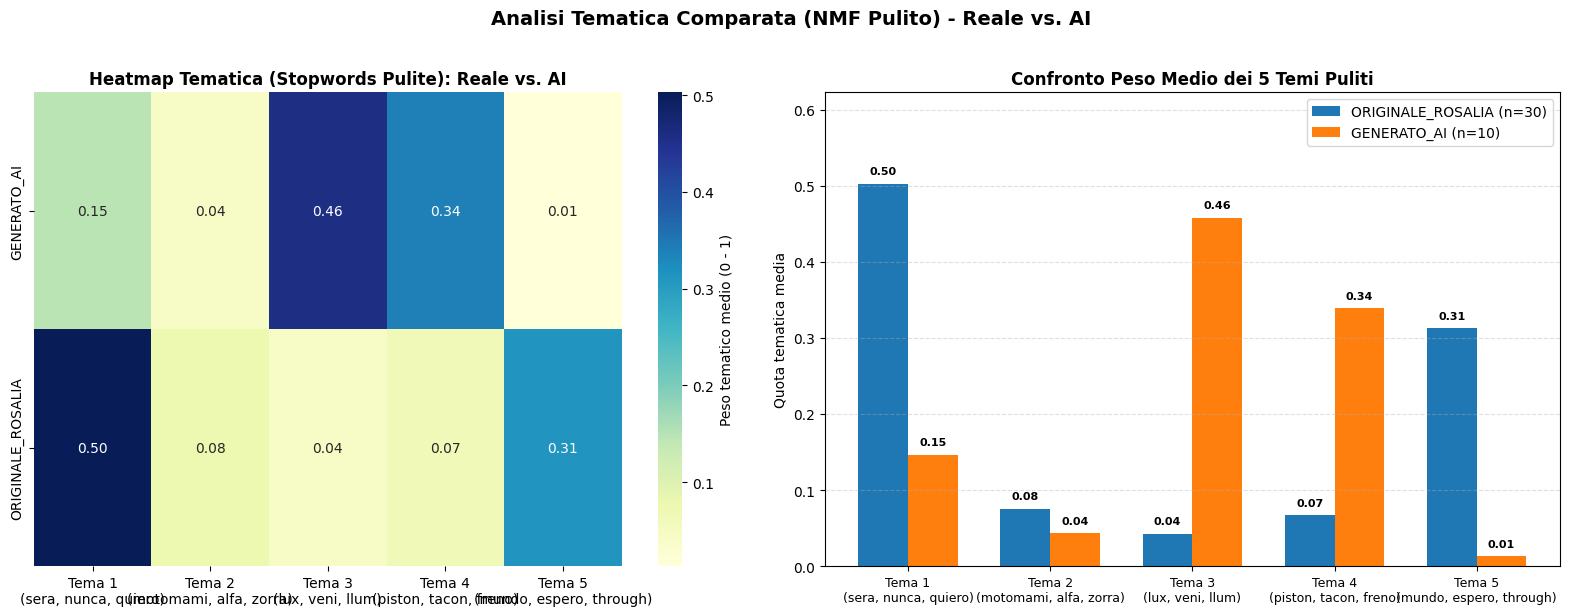


📊 Grafico tematico pulito salvato in: /content/drive/MyDrive/Progetto-Rosalia/comparazione_tematica_nmf_pulito_fase4.png


In [ ]:
import json
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

cartella_drive = "/content/drive/MyDrive/Progetto-Rosalia"
percorso_dataset = os.path.join(cartella_drive, "dataset_misto_anonimo.json")
percorso_chiave = os.path.join(cartella_drive, "chiave_verita_riservata.json")

with open(percorso_dataset, "r", encoding="utf-8") as f:
  dataset_raw = json.load(f)
with open(percorso_chiave, "r", encoding="utf-8") as f:
  chiave_raw = json.load(f)


def estrai_testo(record):
  for chiave in [
      "testo_normalizzato",
      "testo",
      "lyrics",
      "contenuto",
      "brano",
  ]:
    if chiave in record and isinstance(record[chiave], str):
      return record[chiave]
  valori_str = [v for v in record.values() if isinstance(v, str)]
  return max(valori_str, key=len) if valori_str else ""


if isinstance(dataset_raw, dict):
  lista_dataset = [
      {"codice_traccia": k, **(v if isinstance(v, dict) else {"testo": v})}
      for k, v in dataset_raw.items()
  ]
else:
  lista_dataset = dataset_raw

diz_testi = {
    item.get("codice_traccia", item.get("codice", f"Traccia_{i+1:02d}")): (
        estrai_testo(item)
    )
    for i, item in enumerate(lista_dataset)
}
diz_verita = {item["codice_traccia"]: item for item in chiave_raw}

codici = list(diz_verita.keys())
testi = [diz_testi.get(c, "") for c in codici]
origini = [diz_verita[c]["origine_reale"] for c in codici]

# Stopwords estese (spagnolo, catalano/occitano leggero, inglese, italiano + interiezioni/particelle)
stopwords_estese = [
    # Spagnolo
    "de",
    "la",
    "que",
    "el",
    "en",
    "y",
    "a",
    "los",
    "del",
    "se",
    "las",
    "por",
    "un",
    "para",
    "con",
    "no",
    "una",
    "su",
    "al",
    "lo",
    "como",
    "más",
    "mas",
    "pero",
    "sus",
    "le",
    "ya",
    "o",
    "este",
    "sí",
    "si",
    "porque",
    "esta",
    "entre",
    "cuando",
    "muy",
    "sin",
    "sobre",
    "también",
    "tambien",
    "me",
    "hasta",
    "hay",
    "donde",
    "dónde",
    "quien",
    "quién",
    "desde",
    "todo",
    "toda",
    "todos",
    "todas",
    "nos",
    "durante",
    "uno",
    "les",
    "ni",
    "contra",
    "otros",
    "ese",
    "eso",
    "ante",
    "ellos",
    "ellas",
    "e",
    "esto",
    "mí",
    "mi",
    "antes",
    "algunos",
    "qué",
    "que",
    "unos",
    "yo",
    "otro",
    "otras",
    "otra",
    "él",
    "tanto",
    "esa",
    "estos",
    "mucho",
    "mucha",
    "quienes",
    "nada",
    "muchos",
    "cual",
    "cuál",
    "poco",
    "ella",
    "estar",
    "estas",
    "algunas",
    "algo",
    "nosotros",
    "te",
    "tu",
    "tú",
    "tus",
    "ti",
    "es",
    "és",
    "son",
    "soy",
    "era",
    "fue",
    "va",
    "voy",
    "vas",
    "van",
    "pa",
    "na",
    "ay",
    "oh",
    "eh",
    "uh",
    "ah",
    "uy",
    "aunque",
    "vez",
    "veces",
    "ser",
    "tener",
    "hacer",
    "haber",
    "tiene",
    "tengo",
    "tenía",
    "tenia",
    "era",
    "eran",
    "sea",
    "sean",
    "estoy",
    "está",
    "esta",
    "están",
    "estan",
    "me",
    "te",
    "se",
    "nos",
    "os",
    # Inglese
    "the",
    "and",
    "to",
    "of",
    "in",
    "i",
    "you",
    "it",
    "for",
    "on",
    "with",
    "my",
    "me",
    "is",
    "that",
    "be",
    "at",
    "so",
    "we",
    "im",
    "ll",
    "re",
    "ve",
    "dont",
    "your",
    "all",
    "like",
    "up",
    "out",
    "just",
    "no",
    "not",
    "are",
    "was",
    "this",
    "but",
    "what",
    "when",
    "get",
    "got",
    "go",
    "know",
    "one",
    "now",
    "too",
    "can",
    "do",
    "don",
    "have",
    "has",
    "had",
    "he",
    "she",
    "they",
    "them",
    "their",
    "there",
    "here",
    "from",
    "or",
    "an",
    "as",
    "if",
    "out",
    "off",
    # Italiano
    "il",
    "lo",
    "la",
    "i",
    "gli",
    "le",
    "di",
    "da",
    "in",
    "con",
    "su",
    "per",
    "tra",
    "fra",
    "che",
    "non",
    "un",
    "una",
    "uno",
    "mi",
    "ti",
    "ci",
    "vi",
    "se",
    "ma",
    "più",
    "piu",
    "come",
    "anche",
    "io",
    "tu",
    "lui",
    "lei",
    "noi",
    "voi",
    "loro",
    "sono",
    "sei",
    "era",
    "ho",
    "hai",
    "ha",
    "nel",
    "nella",
    "del",
    "della",
    "dei",
    "delle",
    "pure",
    "solo",
    "già",
    "gia",
    "ancora",
    # Sillabe / interiezioni ritmiche frequenti nei testi musicali
    "ta",
    "ra",
    "pa",
    "la",
    "na",
    "da",
    "ba",
    "ya",
    "uoh",
    "ooh",
    "yeah",
    "ey",
    "hey",
]

# Normalizza eventuali accenti per far combaciare meglio parole e stopwords
import unicodedata


def rimuovi_accenti(s):
  return "".join(
      c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn"
  )


testi_puliti = [rimuovi_accenti(t.lower()) for t in testi]
stopwords_pulite = list(
    {rimuovi_accenti(w.lower()) for w in stopwords_estese}
)

vectorizer = TfidfVectorizer(
    stop_words=stopwords_pulite,
    min_df=2,
    max_features=1000,
    token_pattern=r"(?u)\b[a-z]{2,}\b",  # esclude parole di 1 lettera o numeri
)
X_tfidf = vectorizer.fit_transform(testi_puliti)
feature_names = np.array(vectorizer.get_feature_names_out())

n_temi = 5
nmf = NMF(n_components=n_temi, random_state=42, init="nndsvda", max_iter=600)
W = nmf.fit_transform(X_tfidf)
H = nmf.components_

W_norm = W / (W.sum(axis=1, keepdims=True) + 1e-12)

etichette_temi = []
print("=== PAROLE CHIAVE PULITE PER CIASCUN TEMA ===")
for idx_tema, comp in enumerate(H):
  top_idx = comp.argsort()[-6:][::-1]
  parole_top = feature_names[top_idx]
  etichetta = f"Tema {idx_tema+1}\n({', '.join(parole_top[:3])})"
  etichette_temi.append(etichetta)
  print(f"Tema {idx_tema+1}: {', '.join(parole_top)}")

df_temi = pd.DataFrame(W_norm, columns=etichette_temi)
df_temi["origine_reale"] = origini
df_temi["codice_traccia"] = codici

media_temi = df_temi.groupby("origine_reale")[etichette_temi].mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    media_temi,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    cbar_kws={"label": "Peso tematico medio (0 - 1)"},
    ax=axes[0],
)
axes[0].set_title(
    "Heatmap Tematica (Stopwords Pulite): Reale vs. AI",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_ylabel("")
axes[0].tick_params(axis="x", rotation=0)

x = np.arange(n_temi)
w = 0.35
val_rosalia = media_temi.loc["ORIGINALE_ROSALIA"].values
val_ai = media_temi.loc["GENERATO_AI"].values

b1 = axes[1].bar(
    x - w / 2,
    val_rosalia,
    width=w,
    label="ORIGINALE_ROSALIA (n=30)",
    color="#1f77b4",
)
b2 = axes[1].bar(
    x + w / 2, val_ai, width=w, label="GENERATO_AI (n=10)", color="#ff7f0e"
)

axes[1].set_title(
    "Confronto Peso Medio dei 5 Temi Puliti", fontsize=12, fontweight="bold"
)
axes[1].set_xticks(x)
axes[1].set_xticklabels(etichette_temi, fontsize=9)
axes[1].set_ylabel("Quota tematica media")
axes[1].set_ylim(0, max(val_rosalia.max(), val_ai.max()) + 0.12)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
axes[1].legend(loc="upper right")

for barre in [b1, b2]:
  for barra in barre:
    h = barra.get_height()
    axes[1].text(
        barra.get_x() + barra.get_width() / 2,
        h + 0.01,
        f"{h:.2f}",
        ha="center",
        va="bottom",
        fontsize=8,
        fontweight="bold",
    )

plt.suptitle(
    "Analisi Tematica Comparata (NMF Pulito) - Reale vs. AI",
    fontsize=14,
    y=1.02,
    fontweight="bold",
)
plt.tight_layout()

percorso_png = os.path.join(
    cartella_drive, "comparazione_tematica_nmf_pulito_fase4.png"
)
fig.savefig(percorso_png, dpi=200, bbox_inches="tight")
plt.show()
print(f"\n📊 Grafico tematico pulito salvato in: {percorso_png}")

In questo blocco separiamo l'analisi tematica (NMF su TF-IDF con stopwords ripulite) in due grafici distinti: il primo dedicato ai 30 brani originali di Rosalía (ORIGINALE_ROSALIA) e il secondo ai 10 brani generati dall'AI (GENERATO_AI). Vogliamo dimostrare come si distribuiscono i pesi medi dei temi all'interno di ciascun corpus preso singolarmente, così da leggere con chiarezza qual è il "baricentro tematico" dei testi reali rispetto a quello dei testi sintetici, senza schiacciare tutto in un confronto a coppie.

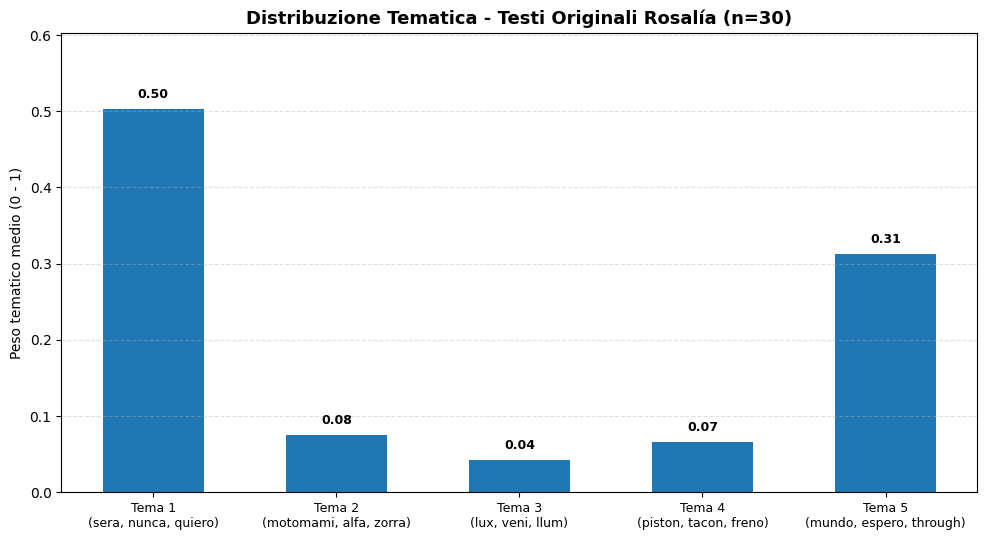

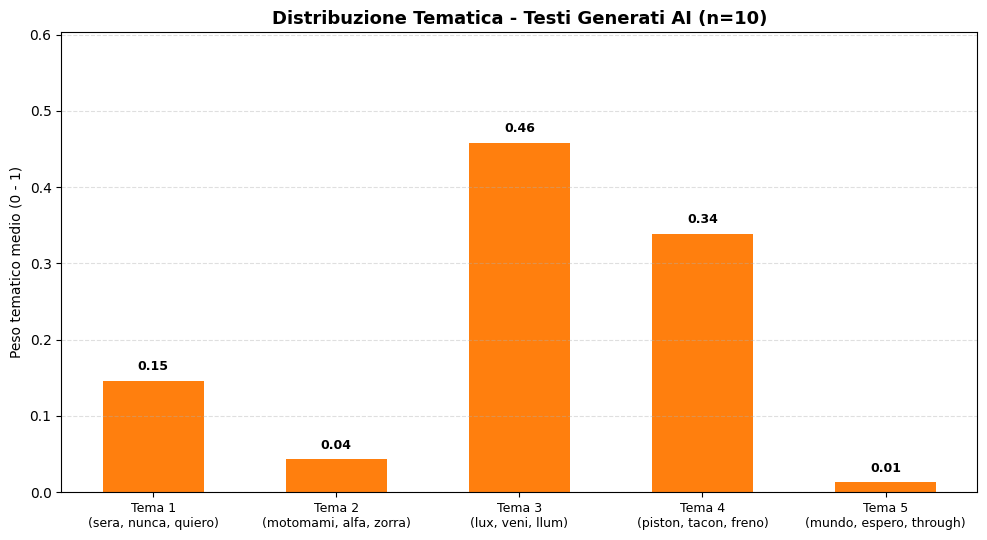

✅ Salvati:
- /content/drive/MyDrive/Progetto-Rosalia/tematiche_originali_rosalia_fase4.png
- /content/drive/MyDrive/Progetto-Rosalia/tematiche_generati_ai_fase4.png


In [ ]:
import json
import os
import unicodedata
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

cartella_drive = "/content/drive/MyDrive/Progetto-Rosalia"
percorso_dataset = os.path.join(cartella_drive, "dataset_misto_anonimo.json")
percorso_chiave = os.path.join(cartella_drive, "chiave_verita_riservata.json")

with open(percorso_dataset, "r", encoding="utf-8") as f:
  dataset_raw = json.load(f)
with open(percorso_chiave, "r", encoding="utf-8") as f:
  chiave_raw = json.load(f)


def estrai_testo(record):
  for chiave in [
      "testo_normalizzato",
      "testo",
      "lyrics",
      "contenuto",
      "brano",
  ]:
    if chiave in record and isinstance(record[chiave], str):
      return record[chiave]
  valori_str = [v for v in record.values() if isinstance(v, str)]
  return max(valori_str, key=len) if valori_str else ""


if isinstance(dataset_raw, dict):
  lista_dataset = [
      {"codice_traccia": k, **(v if isinstance(v, dict) else {"testo": v})}
      for k, v in dataset_raw.items()
  ]
else:
  lista_dataset = dataset_raw

diz_testi = {
    item.get("codice_traccia", item.get("codice", f"Traccia_{i+1:02d}")): (
        estrai_testo(item)
    )
    for i, item in enumerate(lista_dataset)
}
diz_verita = {item["codice_traccia"]: item for item in chiave_raw}

codici = list(diz_verita.keys())
testi = [diz_testi.get(c, "") for c in codici]
origini = [diz_verita[c]["origine_reale"] for c in codici]

stopwords_estese = [
    # Spagnolo
    "de",
    "la",
    "que",
    "el",
    "en",
    "y",
    "a",
    "los",
    "del",
    "se",
    "las",
    "por",
    "un",
    "para",
    "con",
    "no",
    "una",
    "su",
    "al",
    "lo",
    "como",
    "más",
    "mas",
    "pero",
    "sus",
    "le",
    "ya",
    "o",
    "este",
    "sí",
    "si",
    "porque",
    "esta",
    "entre",
    "cuando",
    "muy",
    "sin",
    "sobre",
    "también",
    "tambien",
    "me",
    "hasta",
    "hay",
    "donde",
    "dónde",
    "quien",
    "quién",
    "desde",
    "todo",
    "toda",
    "todos",
    "todas",
    "nos",
    "durante",
    "uno",
    "les",
    "ni",
    "contra",
    "otros",
    "ese",
    "eso",
    "ante",
    "ellos",
    "ellas",
    "e",
    "esto",
    "mí",
    "mi",
    "antes",
    "algunos",
    "qué",
    "unos",
    "yo",
    "otro",
    "otras",
    "otra",
    "él",
    "tanto",
    "esa",
    "estos",
    "mucho",
    "mucha",
    "quienes",
    "nada",
    "muchos",
    "cual",
    "cuál",
    "poco",
    "ella",
    "estar",
    "estas",
    "algunas",
    "algo",
    "nosotros",
    "te",
    "tu",
    "tú",
    "tus",
    "ti",
    "es",
    "és",
    "son",
    "soy",
    "era",
    "fue",
    "va",
    "voy",
    "vas",
    "van",
    "pa",
    "na",
    "ay",
    "oh",
    "eh",
    "uh",
    "ah",
    "uy",
    "aunque",
    "vez",
    "veces",
    "ser",
    "tener",
    "hacer",
    "haber",
    "tiene",
    "tengo",
    "tenía",
    "tenia",
    "eran",
    "sea",
    "sean",
    "estoy",
    "está",
    "están",
    "estan",
    "os",
    # Inglese
    "the",
    "and",
    "to",
    "of",
    "in",
    "i",
    "you",
    "it",
    "for",
    "on",
    "with",
    "my",
    "is",
    "that",
    "be",
    "at",
    "so",
    "we",
    "im",
    "ll",
    "re",
    "ve",
    "dont",
    "your",
    "all",
    "like",
    "up",
    "out",
    "just",
    "not",
    "are",
    "was",
    "this",
    "but",
    "what",
    "when",
    "get",
    "got",
    "go",
    "know",
    "one",
    "now",
    "too",
    "can",
    "do",
    "don",
    "have",
    "has",
    "had",
    "he",
    "she",
    "they",
    "them",
    "their",
    "there",
    "here",
    "from",
    "or",
    "an",
    "as",
    "if",
    "off",
    # Italiano
    "il",
    "lo",
    "gli",
    "di",
    "da",
    "per",
    "tra",
    "fra",
    "che",
    "non",
    "ci",
    "vi",
    "ma",
    "più",
    "piu",
    "anche",
    "io",
    "lui",
    "lei",
    "noi",
    "voi",
    "loro",
    "sono",
    "sei",
    "ho",
    "hai",
    "ha",
    "nel",
    "nella",
    "della",
    "dei",
    "delle",
    "pure",
    "solo",
    "già",
    "gia",
    "ancora",
    # Sillabe / interiezioni ritmiche
    "ta",
    "ra",
    "ba",
    "uoh",
    "ooh",
    "yeah",
    "ey",
    "hey",
]


def rimuovi_accenti(s):
  return "".join(
      c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn"
  )


testi_puliti = [rimuovi_accenti(t.lower()) for t in testi]
stopwords_pulite = list(
    {rimuovi_accenti(w.lower()) for w in stopwords_estese}
)

vectorizer = TfidfVectorizer(
    stop_words=stopwords_pulite,
    min_df=2,
    max_features=1000,
    token_pattern=r"(?u)\b[a-z]{2,}\b",
)
X_tfidf = vectorizer.fit_transform(testi_puliti)
feature_names = np.array(vectorizer.get_feature_names_out())

n_temi = 5
nmf = NMF(n_components=n_temi, random_state=42, init="nndsvda", max_iter=600)
W = nmf.fit_transform(X_tfidf)
H = nmf.components_
W_norm = W / (W.sum(axis=1, keepdims=True) + 1e-12)

etichette_temi = []
for idx_tema, comp in enumerate(H):
  top_idx = comp.argsort()[-5:][::-1]
  parole_top = feature_names[top_idx]
  etichette_temi.append(f"Tema {idx_tema+1}\n({', '.join(parole_top[:3])})")

df_temi = pd.DataFrame(W_norm, columns=etichette_temi)
df_temi["origine_reale"] = origini

val_rosalia = (
    df_temi[df_temi["origine_reale"] == "ORIGINALE_ROSALIA"][etichette_temi]
    .mean()
    .values
)
val_ai = (
    df_temi[df_temi["origine_reale"] == "GENERATO_AI"][etichette_temi]
    .mean()
    .values
)
tetto_y = max(val_rosalia.max(), val_ai.max()) + 0.10

# --- GRAFICO 1: SOLO TESTI ORIGINALI (ROSALÍA) ---
fig1, ax1 = plt.subplots(figsize=(10, 5.5))
barre1 = ax1.bar(etichette_temi, val_rosalia, width=0.55, color="#1f77b4")
ax1.set_title(
    "Distribuzione Tematica - Testi Originali Rosalía (n=30)",
    fontsize=13,
    fontweight="bold",
)
ax1.set_ylabel("Peso tematico medio (0 - 1)")
ax1.set_ylim(0, tetto_y)
ax1.grid(axis="y", linestyle="--", alpha=0.4)
ax1.tick_params(axis="x", labelsize=9)

for b in barre1:
  h = b.get_height()
  ax1.text(
      b.get_x() + b.get_width() / 2,
      h + 0.01,
      f"{h:.2f}",
      ha="center",
      va="bottom",
      fontsize=9,
      fontweight="bold",
  )

plt.tight_layout()
percorso_png1 = os.path.join(
    cartella_drive, "tematiche_originali_rosalia_fase4.png"
)
fig1.savefig(percorso_png1, dpi=200, bbox_inches="tight")
plt.show()

# --- GRAFICO 2: SOLO TESTI GENERATI DALL'AI ---
fig2, ax2 = plt.subplots(figsize=(10, 5.5))
barre2 = ax2.bar(etichette_temi, val_ai, width=0.55, color="#ff7f0e")
ax2.set_title(
    "Distribuzione Tematica - Testi Generati AI (n=10)",
    fontsize=13,
    fontweight="bold",
)
ax2.set_ylabel("Peso tematico medio (0 - 1)")
ax2.set_ylim(0, tetto_y)
ax2.grid(axis="y", linestyle="--", alpha=0.4)
ax2.tick_params(axis="x", labelsize=9)

for b in barre2:
  h = b.get_height()
  ax2.text(
      b.get_x() + b.get_width() / 2,
      h + 0.01,
      f"{h:.2f}",
      ha="center",
      va="bottom",
      fontsize=9,
      fontweight="bold",
  )

plt.tight_layout()
percorso_png2 = os.path.join(
    cartella_drive, "tematiche_generati_ai_fase4.png"
)
fig2.savefig(percorso_png2, dpi=200, bbox_inches="tight")
plt.show()

print(f"✅ Salvati:\n- {percorso_png1}\n- {percorso_png2}")

In questo blocco confrontiamo ciascuno dei brani generati dall'AI (GENERATO_AI) con i 30 brani originali (ORIGINALE_ROSALIA) usando:

Similarità del coseno su TF-IDF (con stopwords ripulite) per trovare, per ogni traccia AI, i brani originali più vicini e le parole condivise più rilevanti.

Confronto delle metriche stilometriche (ttr, rapporto_token_ripetuti, rapporto_bigrammi_ripetuti) tra ogni brano AI e la media dei brani originali.

Vogliamo dimostrare quali brani reali hanno agito da "magneti" lessicali o stilistici per la generazione e se l'LLM ha ripreso soprattutto vocaboli iconici/tematici oppure la struttura ripetitiva dei testi originali.

In [ ]:
import json
import os
import unicodedata
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

cartella_drive = "/content/drive/MyDrive/Progetto-Rosalia"
percorso_dataset = os.path.join(cartella_drive, "dataset_misto_anonimo.json")
percorso_chiave = os.path.join(cartella_drive, "chiave_verita_riservata.json")
percorso_out = os.path.join(cartella_drive, "riferimenti_ai_corpus_fase4.json")

with open(percorso_dataset, "r", encoding="utf-8") as f:
  dataset_raw = json.load(f)
with open(percorso_chiave, "r", encoding="utf-8") as f:
  chiave_raw = json.load(f)


def estrai_testo(record):
  for chiave in [
      "testo_normalizzato",
      "testo",
      "lyrics",
      "contenuto",
      "brano",
  ]:
    if chiave in record and isinstance(record[chiave], str):
      return record[chiave]
  valori_str = [v for v in record.values() if isinstance(v, str)]
  return max(valori_str, key=len) if valori_str else ""


def rimuovi_accenti(s):
  return "".join(
      c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn"
  )


if isinstance(dataset_raw, dict):
  lista_dataset = [
      {"codice_traccia": k, **(v if isinstance(v, dict) else {"testo": v})}
      for k, v in dataset_raw.items()
  ]
else:
  lista_dataset = dataset_raw

diz_testi = {
    item.get("codice_traccia", item.get("codice", f"Traccia_{i+1:02d}")): (
        estrai_testo(item)
    )
    for i, item in enumerate(lista_dataset)
}
diz_verita = {item["codice_traccia"]: item for item in chiave_raw}

stopwords_base = {
    "de",
    "la",
    "que",
    "el",
    "en",
    "y",
    "a",
    "los",
    "del",
    "se",
    "las",
    "por",
    "un",
    "para",
    "con",
    "no",
    "una",
    "su",
    "al",
    "lo",
    "como",
    "mas",
    "pero",
    "sus",
    "le",
    "ya",
    "o",
    "este",
    "si",
    "porque",
    "esta",
    "entre",
    "cuando",
    "muy",
    "sin",
    "sobre",
    "tambien",
    "me",
    "hasta",
    "hay",
    "donde",
    "quien",
    "desde",
    "todo",
    "nos",
    "uno",
    "les",
    "ni",
    "mi",
    "yo",
    "te",
    "tu",
    "es",
    "son",
    "soy",
    "era",
    "fue",
    "va",
    "voy",
    "pa",
    "na",
    "ay",
    "oh",
    "eh",
    "uh",
    "ah",
    "the",
    "and",
    "to",
    "of",
    "in",
    "i",
    "you",
    "it",
    "for",
    "on",
    "with",
    "my",
    "is",
    "that",
    "be",
    "at",
    "so",
    "we",
    "im",
    "your",
    "all",
    "like",
    "up",
    "out",
    "just",
    "not",
    "are",
    "was",
    "this",
    "but",
    "what",
    "when",
    "get",
    "got",
    "go",
    "know",
    "one",
    "now",
    "too",
    "il",
    "lo",
    "gli",
    "di",
    "da",
    "per",
    "che",
    "non",
    "ci",
    "vi",
    "ma",
    "piu",
    "anche",
    "io",
    "noi",
    "voi",
    "loro",
    "sono",
    "sei",
    "ho",
    "hai",
    "ha",
    "nel",
    "nella",
    "del",
    "della",
}

codici_ros = [
    c
    for c, v in diz_verita.items()
    if v.get("origine_reale") == "ORIGINALE_ROSALIA"
]
codici_ai = [
    c for c, v in diz_verita.items() if v.get("origine_reale") == "GENERATO_AI"
]

testi_ros_puliti = [rimuovi_accenti(diz_testi.get(c, "").lower()) for c in codici_ros]
testi_ai_puliti = [rimuovi_accenti(diz_testi.get(c, "").lower()) for c in codici_ai]

vectorizer = TfidfVectorizer(
    stop_words=list(stopwords_base),
    token_pattern=r"(?u)\b[a-z]{2,}\b",
)
X_ros = vectorizer.fit_transform(testi_ros_puliti)
X_ai = vectorizer.transform(testi_ai_puliti)
vocab = np.array(vectorizer.get_feature_names_out())

matrice_sim = cosine_similarity(X_ai, X_ros)  # shape: (n_ai, n_ros)

risultati = []
print("=== TOP 3 BRANI ORIGINALI PIÙ SIMILI PER CIASCUN BRANO AI ===")
for i_ai, c_ai in enumerate(codici_ai):
  titolo_ai = diz_verita[c_ai].get("titolo_reale", c_ai)
  sim_row = matrice_sim[i_ai]
  top_idx = sim_row.argsort()[::-1][:3]

  set_ai = set(testi_ai_puliti[i_ai].split()) - stopwords_base
  top_matches = []
  print(f"\n• {c_ai} ({titolo_ai}):")

  for rank, idx_ros in enumerate(top_idx, start=1):
    c_ros = codici_ros[idx_ros]
    titolo_ros = diz_verita[c_ros].get("titolo_reale", c_ros)
    score = float(sim_row[idx_ros])
    set_ros = set(testi_ros_puliti[idx_ros].split()) - stopwords_base
    parole_comuni = sorted(set_ai.intersection(set_ros))[:10]

    top_matches.append({
        "rank": rank,
        "codice_originale": c_ros,
        "titolo_originale": titolo_ros,
        "similarita_coseno": round(score, 4),
        "parole_comuni_esempio": parole_comuni,
    })
    print(
        f"   {rank}. {c_ros} ({titolo_ros}) -> sim={score:.3f} | comuni:"
        f" {', '.join(parole_comuni[:6])}"
    )

  risultati.append({
      "codice_ai": c_ai,
      "titolo_ai": titolo_ai,
      "top_3_originali": top_matches,
  })

with open(percorso_out, "w", encoding="utf-8") as f:
  json.dump(risultati, f, ensure_ascii=False, indent=4)

print(f"\n✅ Dettaglio salvato in: {percorso_out}")

=== TOP 3 BRANI ORIGINALI PIÙ SIMILI PER CIASCUN BRANO AI ===

• Traccia_04 (Elegia Introspettiva):
   1. Traccia_39 (Traccia_2) -> sim=0.100 | comuni: amor, aprendi, cristal, eterno, lengua, mio
   2. Traccia_34 (Traccia_7) -> sim=0.092 | comuni: nunca, oro, pena, perla, tan, tiene
   3. Traccia_01 (Traccia_10) -> sim=0.081 | comuni: amor, antes, nunca, sigo, silencio, sombra

• Traccia_07 (Beat Fragmentado):
   1. Traccia_18 (Traccia_27) -> sim=0.197 | comuni: cute, quiero
   2. Traccia_13 (Traccia_24) -> sim=0.120 | comuni: motomami, pesa, quiero
   3. Traccia_33 (Traccia_6) -> sim=0.068 | comuni: love, solo

• Traccia_10 (Flamenco-Urbano Minimal):
   1. Traccia_13 (Traccia_24) -> sim=0.148 | comuni: motomami
   2. Traccia_14 (Traccia_19) -> sim=0.117 | comuni: cantaora, dios, dos, fuego, igual, siete
   3. Traccia_39 (Traccia_2) -> sim=0.112 | comuni: mal, mio, perdon, pureza, tiene

• Traccia_16 (Outro Spoken Word):
   1. Traccia_20 (Traccia_23) -> sim=0.110 | comuni: amor, antes,

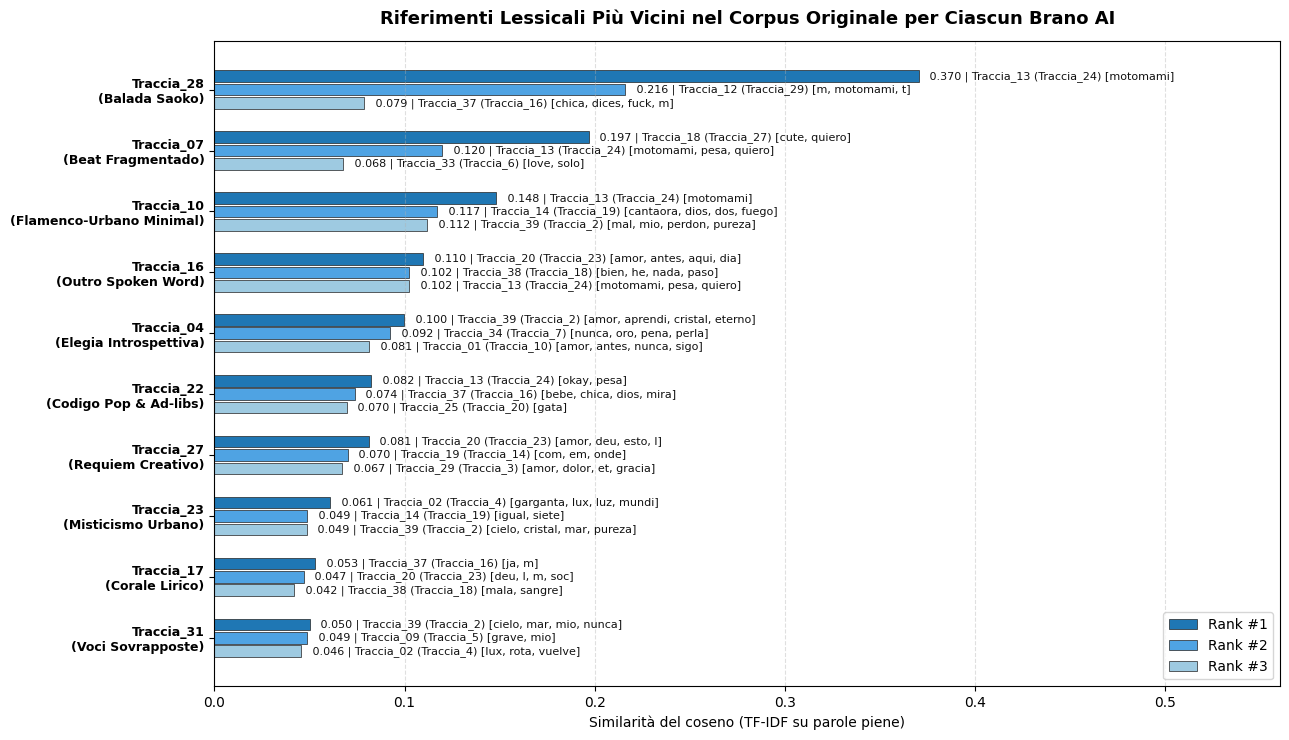

📊 Grafico salvato in: /content/drive/MyDrive/Progetto-Rosalia/top3_riferimenti_ai_fase4.png


In [ ]:
import json
import os
import matplotlib.pyplot as plt
import pandas as pd

cartella_drive = "/content/drive/MyDrive/Progetto-Rosalia"
percorso_json = os.path.join(cartella_drive, "riferimenti_ai_corpus_fase4.json")

with open(percorso_json, "r", encoding="utf-8") as f:
  dati = json.load(f)

righe = []
for item in dati:
  cod_ai = item["codice_ai"]
  tit_ai = item.get("titolo_ai", cod_ai)
  etichetta_ai = f"{cod_ai}\n({tit_ai})"
  for m in item.get("top_3_originali", []):
    parole_str = ", ".join(m.get("parole_comuni_esempio", [])[:4])
    righe.append({
        "etichetta_ai": etichetta_ai,
        "codice_ai": cod_ai,
        "rank": m["rank"],
        "originale": f"{m['codice_originale']} ({m['titolo_originale']})",
        "sim": m["similarita_coseno"],
        "parole": parole_str,
    })

df_match = pd.DataFrame(righe)

# Ordina i brani AI per similarità massima decrescente così il grafico è più leggibile
ordine_ai = (
    df_match.groupby("etichetta_ai", sort=False)["sim"]
    .max()
    .sort_values(ascending=True)
    .index.tolist()
)

fig, ax = plt.subplots(figsize=(13, 7.5))

colori_rank = {1: "#1f77b4", 2: "#4fa3e3", 3: "#9ecae1"}
offset_rank = {1: 0.22, 2: 0.0, 3: -0.22}

y_base = {cod: idx for idx, cod in enumerate(ordine_ai)}

for rank in [1, 2, 3]:
  sub = df_match[df_match["rank"] == rank]
  ys = [y_base[et] + offset_rank[rank] for et in sub["etichetta_ai"]]
  xs = sub["sim"].values
  ax.barh(
      ys,
      xs,
      height=0.19,
      color=colori_rank[rank],
      edgecolor="#222222",
      linewidth=0.5,
      label=f"Rank #{rank}",
  )

  for y_pos, x_val, (_, r) in zip(ys, xs, sub.iterrows()):
    nota = f" {x_val:.3f} | {r['originale']}"
    if r["parole"]:
      nota += f" [{r['parole']}]"
    ax.text(
        x_val + 0.004,
        y_pos,
        nota,
        va="center",
        ha="left",
        fontsize=8,
        color="#111111",
    )

ax.set_yticks(range(len(ordine_ai)))
ax.set_yticklabels(ordine_ai, fontsize=9, fontweight="bold")
ax.set_xlabel("Similarità del coseno (TF-IDF su parole piene)")
ax.set_title(
    "Riferimenti Lessicali Più Vicini nel Corpus Originale per Ciascun Brano AI",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
ax.set_xlim(0, df_match["sim"].max() + 0.19)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.legend(loc="lower right")

plt.tight_layout()
percorso_png = os.path.join(cartella_drive, "top3_riferimenti_ai_fase4.png")
fig.savefig(percorso_png, dpi=200, bbox_inches="tight")
plt.show()
print(f"📊 Grafico salvato in: {percorso_png}")

In questo blocco analizziamo dataset_misto_anonimo.json e chiave_verita_riservata.json per stimare la composizione linguistica di ciascuno dei 40 brani (usando langdetect se installato, oppure un classificatore basato su stopwords/lessico multilingue come fallback automatico così funziona senza bloccarsi). Vogliamo dimostrare quante e quali lingue emergono nel corpus di Rosalía rispetto ai brani generati dall'AI, e verificare se i testi sintetici tendono a essere più "monolingui" o semplificati sul piano linguistico rispetto all'ibridazione multilingue dei brani originali

=== LINGUE RILEVATE IN ORIGINALE_ROSALIA (8) ===
ca, de, en, es, fr, it, la, pt

=== LINGUE RILEVATE IN GENERATO_AI (7) ===
ca, en, es, fr, it, la, pt

=== MEDIA LINGUE PER BRANO E FREQUENZA PER GRUPPO ===
                   count      mean  median  max
origine_reale                                  
GENERATO_AI           10  5.000000     5.0    7
ORIGINALE_ROSALIA     30  4.433333     5.0    7


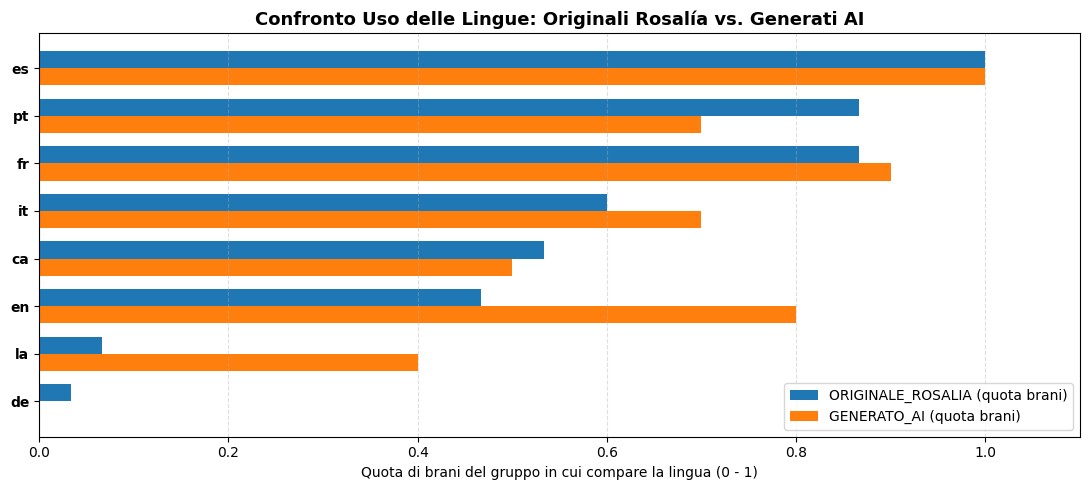


📊 Grafico salvato in: /content/drive/MyDrive/Progetto-Rosalia/confronto_lingue_fase4.png


In [ ]:
import json
import os
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

cartella_drive = "/content/drive/MyDrive/Progetto-Rosalia"
percorso_dataset = os.path.join(cartella_drive, "dataset_misto_anonimo.json")
percorso_chiave = os.path.join(cartella_drive, "chiave_verita_riservata.json")

with open(percorso_dataset, "r", encoding="utf-8") as f:
  dataset_raw = json.load(f)
with open(percorso_chiave, "r", encoding="utf-8") as f:
  chiave_raw = json.load(f)


def estrai_testo(record):
  for chiave in [
      "testo_normalizzato",
      "testo",
      "lyrics",
      "contenuto",
      "brano",
  ]:
    if chiave in record and isinstance(record[chiave], str):
      return record[chiave]
  valori_str = [v for v in record.values() if isinstance(v, str)]
  return max(valori_str, key=len) if valori_str else ""


if isinstance(dataset_raw, dict):
  lista_dataset = [
      {"codice_traccia": k, **(v if isinstance(v, dict) else {"testo": v})}
      for k, v in dataset_raw.items()
  ]
else:
  lista_dataset = dataset_raw

diz_testi = {
    item.get("codice_traccia", item.get("codice", f"Traccia_{i+1:02d}")): (
        estrai_testo(item)
    )
    for i, item in enumerate(lista_dataset)
}
diz_verita = {item["codice_traccia"]: item for item in chiave_raw}

# Prova a usare langdetect se disponibile; altrimenti usa un dizionario euristico di marcatori linguistici
try:
  from langdetect import DetectorFactory, detect_langs

  DetectorFactory.seed = 42
  usa_langdetect = True
except ImportError:
  usa_langdetect = False

marcatori_lingua = {
    "es": {
        "el",
        "la",
        "los",
        "las",
        "un",
        "una",
        "que",
        "por",
        "para",
        "con",
        "sin",
        "pero",
        "como",
        "cuando",
        "donde",
        "yo",
        "tu",
        "tú",
        "mi",
        "me",
        "te",
        "se",
        "nos",
        "soy",
        "eres",
        "es",
        "somos",
        "estoy",
        "está",
        "hay",
        "nada",
        "todo",
        "siempre",
        "nunca",
        "quiero",
        "amor",
        "alma",
        "sangre",
        "corazón",
    },
    "ca": {
        "els",
        "les",
        "dels",
        "del",
        "una",
        "perquè",
        "amb",
        "sense",
        "però",
        "quan",
        "on",
        "jo",
        "tu",
        "em",
        "et",
        "ens",
        "sóc",
        "soc",
        "és",
        "som",
        "estic",
        "està",
        "res",
        "tot",
        "sempre",
        "mai",
        "vull",
        "llum",
        "cor",
        "nit",
        "foc",
        "avui",
    },
    "en": {
        "the",
        "and",
        "to",
        "of",
        "in",
        "is",
        "it",
        "you",
        "my",
        "me",
        "for",
        "on",
        "with",
        "that",
        "this",
        "but",
        "not",
        "are",
        "was",
        "we",
        "your",
        "all",
        "like",
        "just",
        "know",
        "love",
        "heart",
        "time",
        "one",
        "now",
        "can",
        "don",
        "im",
    },
    "it": {
        "il",
        "lo",
        "gli",
        "di",
        "da",
        "nel",
        "nella",
        "che",
        "non",
        "per",
        "con",
        "ma",
        "come",
        "quando",
        "dove",
        "io",
        "noi",
        "voi",
        "loro",
        "sono",
        "sei",
        "siamo",
        "ho",
        "hai",
        "ha",
        "niente",
        "tutto",
        "sempre",
        "mai",
        "voglio",
        "amore",
        "cuore",
        "notte",
        "più",
        "piu",
        "anche",
    },
    "pt": {
        "o",
        "os",
        "as",
        "um",
        "uma",
        "que",
        "por",
        "para",
        "com",
        "sem",
        "mas",
        "como",
        "quando",
        "onde",
        "eu",
        "nós",
        "meu",
        "minha",
        "sou",
        "está",
        "não",
        "tudo",
        "sempre",
        "nunca",
        "quero",
        "amor",
        "coração",
        "saudade",
    },
    "fr": {
        "le",
        "les",
        "des",
        "du",
        "un",
        "une",
        "que",
        "pour",
        "avec",
        "sans",
        "mais",
        "comme",
        "quand",
        "où",
        "je",
        "tu",
        "nous",
        "vous",
        "mon",
        "ma",
        "suis",
        "est",
        "pas",
        "tout",
        "toujours",
        "jamais",
        "veux",
        "amour",
        "coeur",
        "cœur",
        "nuit",
    },
    "la": {
        "et",
        "in",
        "ad",
        "cum",
        "non",
        "lux",
        "rex",
        "deus",
        "cor",
        "anima",
        "mors",
        "vita",
        "sanctus",
        "maria",
        "ave",
        "gloria",
        "pax",
        "terra",
        "caelum",
        "veni",
    },
    "de": {
        "der",
        "die",
        "das",
        "und",
        "zu",
        "mit",
        "nicht",
        "ich",
        "du",
        "ist",
        "ein",
        "eine",
        "für",
        "auf",
        "herz",
        "liebe",
        "nacht",
        "licht",
        "welt",
        "schmerz",
    },
}


def rileva_lingue_testo(testo):
  if not testo or not testo.strip():
    return []
  lingue_trovate = set()

  # Righe/segmenti del testo
  righe = [r.strip() for r in re.split(r"[\n\r.!?]+", testo) if len(r.strip()) > 3]
  if usa_langdetect and righe:
    for r in righe:
      try:
        for lp in detect_langs(r):
          if lp.prob >= 0.35:
            lingue_trovate.add(lp.lang)
      except Exception:
        pass

  # Controllo aggiuntivo per parola/marcatore (molto utile per code-switching, latino, catalano, ecc.)
  parole = set(re.findall(r"\b[a-zàèéìíòóùúüñç]+\b", testo.lower()))
  for lang, set_marc in marcatori_lingua.items():
    if len(parole.intersection(set_marc)) >= 2:
      lingue_trovate.add(lang)

  return sorted(lingue_trovate)


righe_df = []
for cod, rec in diz_verita.items():
  orig = rec.get("origine_reale", "N/D")
  testo = diz_testi.get(cod, "")
  lingue = rileva_lingue_testo(testo)
  righe_df.append({
      "codice_traccia": cod,
      "origine_reale": orig,
      "lingue": lingue,
      "n_lingue": len(lingue),
      "lingue_str": ", ".join(lingue) if lingue else "nessuna/incerta",
  })

df_lingue = pd.DataFrame(righe_df)

# Elenco complessivo delle lingue rilevate nel corpus di Rosalía
lingue_rosalia = sorted({
    lg
    for sub in df_lingue[df_lingue["origine_reale"] == "ORIGINALE_ROSALIA"]["lingue"]
    for lg in sub
})
lingue_ai = sorted({
    lg
    for sub in df_lingue[df_lingue["origine_reale"] == "GENERATO_AI"]["lingue"]
    for lg in sub
})

print(f"=== LINGUE RILEVATE IN ORIGINALE_ROSALIA ({len(lingue_rosalia)}) ===")
print(", ".join(lingue_rosalia) if lingue_rosalia else "Nessuna")

print(f"\n=== LINGUE RILEVATE IN GENERATO_AI ({len(lingue_ai)}) ===")
print(", ".join(lingue_ai) if lingue_ai else "Nessuna")

print("\n=== MEDIA LINGUE PER BRANO E FREQUENZA PER GRUPPO ===")
print(df_lingue.groupby("origine_reale")["n_lingue"].agg(["count", "mean", "median", "max"]))

# Conteggio brani per lingua in ciascun gruppo
tutte_lingue = sorted(set(lingue_rosalia).union(set(lingue_ai)))
freq_data = []
for lg in tutte_lingue:
  n_ros = sum(lg in lst for lst in df_lingue[df_lingue["origine_reale"] == "ORIGINALE_ROSALIA"]["lingue"])
  n_ai = sum(lg in lst for lst in df_lingue[df_lingue["origine_reale"] == "GENERATO_AI"]["lingue"])
  freq_data.append({
      "lingua": lg,
      "quota_rosalia": n_ros / max(1, (df_lingue["origine_reale"] == "ORIGINALE_ROSALIA").sum()),
      "quota_ai": n_ai / max(1, (df_lingue["origine_reale"] == "GENERATO_AI").sum()),
  })

df_freq = pd.DataFrame(freq_data).sort_values("quota_rosalia", ascending=True)

if len(df_freq) > 0:
  fig, ax = plt.subplots(figsize=(11, max(5, 0.45 * len(df_freq))))
  y = np.arange(len(df_freq))
  h = 0.36
  ax.barh(y + h / 2, df_freq["quota_rosalia"], height=h, label="ORIGINALE_ROSALIA (quota brani)", color="#1f77b4")
  ax.barh(y - h / 2, df_freq["quota_ai"], height=h, label="GENERATO_AI (quota brani)", color="#ff7f0e")
  ax.set_yticks(y)
  ax.set_yticklabels(df_freq["lingua"], fontsize=10, fontweight="bold")
  ax.set_xlabel("Quota di brani del gruppo in cui compare la lingua (0 - 1)")
  ax.set_title("Confronto Uso delle Lingue: Originali Rosalía vs. Generati AI", fontsize=13, fontweight="bold")
  ax.set_xlim(0, 1.1)
  ax.grid(axis="x", linestyle="--", alpha=0.4)
  ax.legend(loc="lower right")
  plt.tight_layout()

  percorso_png = os.path.join(cartella_drive, "confronto_lingue_fase4.png")
  fig.savefig(percorso_png, dpi=200, bbox_inches="tight")
  plt.show()
  print(f"\n📊 Grafico salvato in: {percorso_png}")

Spagnolo (es): è presente quasi nella totalità dei brani in entrambi i gruppi (barra vicina a 1.0).

Inglese (en) e latino (la): compaiono in una quota maggiore di brani GENERATO_AI (rispettivamente intorno a 0.8 e 0.4) rispetto a ORIGINALE_ROSALIA (sotto 0.5 per en e molto bassa per la).

Tedesco (de): compare solo in una piccola quota dei brani originali di Rosalía e non nei testi AI.

Portoghese (pt), francese (fr), italiano (it) e catalano (ca): mostrano presenze rilevanti in entrambi i gruppi, con lievi differenze di quota tra blu e arancione.

In [ ]:
import base64
import json
import os
from google.colab import drive
import pandas as pd

# 1. Monta Google Drive e imposta i percorsi
drive.mount("/content/drive", force_remount=False)
cartella_drive = "/content/drive/MyDrive/Progetto-Rosalia"

percorso_excel_commenti = os.path.join(
    cartella_drive, "commenti_critici_report.xlsx"
)
percorso_report_json = os.path.join(
    cartella_drive, "report_valutazione_finale.json"
)
percorso_comp_json = os.path.join(
    cartella_drive, "comparazione_quantitativa_fase4.json"
)
percorso_rif_json = os.path.join(
    cartella_drive, "riferimenti_ai_corpus_fase4.json"
)
percorso_cs_json = os.path.join(
    cartella_drive, "analisi_code_switching_tutti_brani.json"
)
percorso_imm_json = os.path.join(
    cartella_drive, "analisi_qualitativa_gemini.json"
)

percorso_html_out = os.path.join(
    cartella_drive, "report_finale_progetto_rosalia.html"
)


def carica_json_sicuro(percorso, default=None):
  if default is None:
    default = {}
  if os.path.exists(percorso):
    with open(percorso, "r", encoding="utf-8") as f:
      return json.load(f)
  return default


# 2. Caricamento commenti critici da Excel
def carica_commenti_excel(percorso_xlsx):
  commenti = {}
  if not os.path.exists(percorso_xlsx):
    # Crea un file Excel modello per facilitare l'inserimento manuale
    df_template = pd.DataFrame([
        {
            "sezione": "numerici",
            "id_dato": "blind_test_metriche",
            "titolo_dato": "Metriche Blind Test (n=40)",
            "commento_critico": (
                "Inserisci qui il commento critico sulle metriche del blind"
                " test."
            ),
        },
        {
            "sezione": "numerici",
            "id_dato": "metriche_per_origine",
            "titolo_dato": "Confronto Stilometrico Reale vs AI",
            "commento_critico": (
                "Inserisci qui il commento critico su TTR, token ripetuti e"
                " bigrammi ripetuti."
            ),
        },
        {
            "sezione": "qualitativi",
            "id_dato": "errori_fp_fn",
            "titolo_dato": "Analisi Errori Falsi Positivi e Falsi Negativi",
            "commento_critico": (
                "Inserisci qui il commento critico sul repetition bias nei FP"
                " e FN."
            ),
        },
        {
            "sezione": "qualitativi",
            "id_dato": "riferimenti_lessicali",
            "titolo_dato": "Top-3 Riferimenti Lessicali AI vs Originali",
            "commento_critico": (
                "Inserisci qui il commento critico sui ganci lessicali e sulla"
                " similarità del coseno."
            ),
        },
        {
            "sezione": "qualitativi",
            "id_dato": "code_switching_e_immagini",
            "titolo_dato": "Code-switching e Tenuta delle Immagini",
            "commento_critico": (
                "Inserisci qui il commento critico su code-switching e"
                " sviluppo delle immagini."
            ),
        },
        {
            "sezione": "analisi_confronto",
            "id_dato": "confronto_esiti_e_distribuzioni",
            "titolo_dato": "Confronto per Esito e Distribuzioni",
            "commento_critico": (
                "Inserisci qui il commento critico sul confronto per"
                " TN/TP/FP/FN e distribuzioni."
            ),
        },
        {
            "sezione": "analisi_confronto",
            "id_dato": "black_box_e_limiti",
            "titolo_dato": "Opacità della Black Box e Limiti Metodologici",
            "commento_critico": (
                "Inserisci qui il commento critico su black box, campione ridotto"
                " e limiti."
            ),
        },
    ])
    df_template.to_excel(percorso_xlsx, index=False)
    print(f"ℹ️ File Excel non trovato: creato modello in {percorso_xlsx}")

  xls = pd.ExcelFile(percorso_xlsx)
  for foglio in xls.sheet_names:
    df = pd.read_excel(percorso_xlsx, sheet_name=foglio)
    df.columns = [str(c).strip().lower() for c in df.columns]
    col_chiave = next(
        (
            c
            for c in [
                "id_dato",
                "chiave",
                "dato",
                "id",
                "metrica",
                "codice",
                "titolo_dato",
            ]
            if c in df.columns
        ),
        None,
    )
    col_comm = next(
        (
            c
            for c in [
                "commento_critico",
                "commento",
                "critica",
                "nota",
                "analisi_critica",
                "testo",
            ]
            if c in df.columns
        ),
        None,
    )
    if col_chiave and col_comm:
      for _, row in df.iterrows():
        chiave = str(row[col_chiave]).strip()
        comm = str(row[col_comm]).strip() if pd.notna(row[col_comm]) else ""
        if chiave and chiave.lower() != "nan" and comm and comm.lower() != "nan":
          commenti[chiave] = comm
  return commenti


commenti_xl = carica_commenti_excel(percorso_excel_commenti)


def blocco_commento_critico(chiave, titolo_fallback="Commento critico"):
  testo_comm = commenti_xl.get(chiave, "")
  if not testo_comm:
    testo_comm = (
        f"<em>[Nessun commento critico trovato in Excel per la chiave"
        f" '<code>{chiave}</code>'. Aggiungi una riga con id_dato = '{chiave}'"
        " nel file Excel per popolare questo riquadro.]</em>"
    )
  return (
      '<div class="commento-critico">'
      f'<div class="commento-label">Commento critico — {titolo_fallback}</div>'
      f'<div class="commento-testo">{testo_comm}</div>'
      "</div>"
  )


# 3. Helper per incorporare immagini PNG come base64 (così l'HTML è autonomo)
def img_html(nome_file, didascalia):
  percorso_img = os.path.join(cartella_drive, nome_file)
  if not os.path.exists(percorso_img):
    return (
        f'<div class="missing-img">Grafico non trovato su Drive:'
        f" <code>{nome_file}</code></div>"
    )
  with open(percorso_img, "rb") as f:
    b64 = base64.b64encode(f.read()).decode("utf-8")
  return (
      '<figure class="figura-box">'
      f'<img src="data:image/png;base64,{b64}" alt="{didascalia}">'
      f"<figcaption>{didascalia}</figcaption>"
      "</figure>"
  )


# 4. Caricamento dati JSON
report_val = carica_json_sicuro(percorso_report_json, {})
comp_quant = carica_json_sicuro(percorso_comp_json, {})
rif_ai = carica_json_sicuro(percorso_rif_json, {})
cs_dati = carica_json_sicuro(percorso_cs_json, {})
imm_dati = carica_json_sicuro(percorso_imm_json, {})

metriche_bt = report_val.get("metriche", {})
dettaglio_bt = report_val.get("dettaglio", [])
riep_origine = comp_quant.get("riepilogo_per_origine", [])
riep_esito = comp_quant.get("riepilogo_per_esito", [])

# --- TABELLE SEZIONE 1: DATI NUMERICI ---
tn = metriche_bt.get("veri_negativi", 16)
tp = metriche_bt.get("veri_positivi", 2)
fp = metriche_bt.get("falsi_positivi", 14)
fn = metriche_bt.get("falsi_negativi", 8)
tot = metriche_bt.get("totale_tracce", tn + tp + fp + fn)
acc = metriche_bt.get(
    "accuratezza_percentuale", ((tp + tn) / tot * 100) if tot else 0.0
)
prec = (tp / (tp + fp)) if (tp + fp) > 0 else 0.0
rec = (tp / (tp + fn)) if (tp + fn) > 0 else 0.0

html_tab_bt = f"""
<table>
  <thead>
    <tr>
      <th>Totale Tracce</th>
      <th>Accuracy</th>
      <th>Precision (AI)</th>
      <th>Recall (AI)</th>
      <th>Veri Negativi (TN)</th>
      <th>Veri Positivi (TP)</th>
      <th>Falsi Positivi (FP)</th>
      <th>Falsi Negativi (FN)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>{tot}</td>
      <td>{acc:.2f}%</td>
      <td>{prec:.4f}</td>
      <td>{rec:.4f}</td>
      <td>{tn}</td>
      <td>{tp}</td>
      <td>{fp}</td>
      <td>{fn}</td>
    </tr>
  </tbody>
</table>
"""

righe_orig_html = ""
for r in riep_origine:
  righe_orig_html += (
      "<tr>"
      f"<td>{r.get('origine_reale', '')}</td>"
      f"<td>{r.get('n_tracce', '')}</td>"
      f"<td>{r.get('media_token', '')}</td>"
      f"<td>{r.get('mediana_token', '')}</td>"
      f"<td>{r.get('media_ttr', '')}</td>"
      f"<td>{r.get('media_tok_rip', '')}</td>"
      f"<td>{r.get('media_bi_rip', '')}</td>"
      "</tr>"
  )

html_tab_origine = f"""
<table>
  <thead>
    <tr>
      <th>Classe Reale</th>
      <th>N. Tracce</th>
      <th>Media Token</th>
      <th>Mediana Token</th>
      <th>TTR Medio</th>
      <th>Token Ripetuti (Media)</th>
      <th>Bigrammi Ripetuti (Media)</th>
    </tr>
  </thead>
  <tbody>
    {righe_orig_html if righe_orig_html else '<tr><td colspan="7">Dati non disponibili in comparazione_quantitativa_fase4.json</td></tr>'}
  </tbody>
</table>
"""

# --- TABELLE SEZIONE 2: DATI QUALITATIVI ---
fp_items = [
    x
    for x in dettaglio_bt
    if x.get("origine_reale") == "ORIGINALE_ROSALIA"
    and x.get("giudizio_groq") == "GENERATO_AI"
]
fn_items = [
    x
    for x in dettaglio_bt
    if x.get("origine_reale") == "GENERATO_AI"
    and x.get("giudizio_groq") == "UMANO"
]

righe_errori_html = ""
for x in fp_items:
  righe_errori_html += (
      "<tr>"
      "<td>FP (Reale -> AI)</td>"
      f"<td>{x.get('codice_traccia', '')} ({x.get('titolo_reale', 'N/D')})</td>"
      f"<td>{x.get('motivazione', '')}</td>"
      "</tr>"
  )
for x in fn_items:
  righe_errori_html += (
      "<tr>"
      "<td>FN (AI -> Umano)</td>"
      f"<td>{x.get('codice_traccia', '')} ({x.get('titolo_reale', 'N/D')})</td>"
      f"<td>{x.get('motivazione', '')}</td>"
      "</tr>"
  )

html_tab_errori = f"""
<table>
  <thead>
    <tr>
      <th>Tipo Errore</th>
      <th>Traccia</th>
      <th>Motivazione del Giudice</th>
    </tr>
  </thead>
  <tbody>
    {righe_errori_html if righe_errori_html else '<tr><td colspan="3">Dettaglio errori non disponibile</td></tr>'}
  </tbody>
</table>
"""

lista_rif = (
    rif_ai.get("confronto_per_brano_ai", [])
    if isinstance(rif_ai, dict)
    else (rif_ai if isinstance(rif_ai, list) else [])
)
righe_rif_html = ""
for item in lista_rif:
  top1 = (
      item.get("top_3_originali", [{}])[0]
      if item.get("top_3_originali")
      else {}
  )
  parole = ", ".join(
      top1.get("parole_comuni", top1.get("parole_comuni_esempio", []))[:5]
  )
  righe_rif_html += (
      "<tr>"
      f"<td>{item.get('codice_ai', '')} ({item.get('titolo_ai', '')})</td>"
      f"<td>{top1.get('codice_originale', '')} ({top1.get('titolo_originale', '')})</td>"
      f"<td>{top1.get('similarita_coseno', '')}</td>"
      f"<td>{parole}</td>"
      "</tr>"
  )

html_tab_rif = f"""
<table>
  <thead>
    <tr>
      <th>Brano AI</th>
      <th>Originale Più Simile (#1)</th>
      <th>Similarità Coseno</th>
      <th>Termini Condivisi</th>
    </tr>
  </thead>
  <tbody>
    {righe_rif_html if righe_rif_html else '<tr><td colspan="4">Dati riferimenti lessicali non disponibili</td></tr>'}
  </tbody>
</table>
"""

brani_cs = cs_dati.get("brani", []) if isinstance(cs_dati, dict) else []
brani_imm = imm_dati.get("brani", []) if isinstance(imm_dati, dict) else []
diz_imm_by_cod = {b.get("codice_traccia"): b for b in brani_imm}

righe_qual_cs_imm = ""
for b in brani_cs:
  cod = b.get("codice_traccia", "")
  im = diz_imm_by_cod.get(cod, {})
  righe_qual_cs_imm += (
      "<tr>"
      f"<td>{cod}</td>"
      f"<td>{b.get('origine_reale', '')}</td>"
      f"<td>{b.get('funzione_code_switching', 'N/D')}</td>"
      f"<td>{im.get('categoria', 'N/D')}</td>"
      f"<td>{b.get('motivazione', '')}</td>"
      "</tr>"
  )

html_tab_cs_imm = f"""
<table>
  <thead>
    <tr>
      <th>Traccia</th>
      <th>Origine Reale</th>
      <th>Funzione Code-Switching</th>
      <th>Tenuta Immagini</th>
      <th>Sintesi Motivazione</th>
    </tr>
  </thead>
  <tbody>
    {righe_qual_cs_imm if righe_qual_cs_imm else '<tr><td colspan="5">Analisi code-switching / immagini non ancora caricata</td></tr>'}
  </tbody>
</table>
"""

# --- TABELLE SEZIONE 3: ANALISI E CONFRONTO ---
righe_esito_html = ""
for r in riep_esito:
  righe_esito_html += (
      "<tr>"
      f"<td>{r.get('esito', '')}</td>"
      f"<td>{r.get('n_tracce', '')}</td>"
      f"<td>{r.get('media_token', '')}</td>"
      f"<td>{r.get('media_ttr', '')}</td>"
      f"<td>{r.get('media_tok_rip', '')}</td>"
      f"<td>{r.get('media_bi_rip', '')}</td>"
      "</tr>"
  )

html_tab_esito = f"""
<table>
  <thead>
    <tr>
      <th>Esito</th>
      <th>N. Tracce</th>
      <th>Media Token</th>
      <th>TTR Medio</th>
      <th>Token Ripetuti (Media)</th>
      <th>Bigrammi Ripetuti (Media)</th>
    </tr>
  </thead>
  <tbody>
    {righe_esito_html if righe_esito_html else '<tr><td colspan="6">Dati per esito non disponibili</td></tr>'}
  </tbody>
</table>
"""

# 5. Assemblaggio HTML finale (Ordine: 1. Dati Numerici -> 2. Dati Qualitativi -> 3. Analisi e Confronto)
html_doc = f"""<!DOCTYPE html>
<html lang="it">
<head>
  <meta charset="UTF-8">
  <title>Report Finale — Confronto Corpus Rosalía vs. AI</title>
  <style>
    body {{
      font-family: "Segoe UI", Arial, sans-serif;
      line-height: 1.55;
      color: #1f2937;
      max-width: 1120px;
      margin: 32px auto;
      padding: 0 20px;
      background-color: #f9fafb;
    }}
    h1 {{
      font-size: 26px;
      color: #111827;
      border-bottom: 3px solid #1f77b4;
      padding-bottom: 10px;
      margin-bottom: 24px;
    }}
    h2.macro-sezione {{
      font-size: 21px;
      color: #0f3d6e;
      margin-top: 42px;
      padding: 10px 14px;
      background-color: #e6f0fa;
      border-left: 5px solid #1f77b4;
      border-radius: 4px;
    }}
    h3 {{
      font-size: 16px;
      color: #1f2937;
      margin-top: 24px;
      margin-bottom: 10px;
    }}
    table {{
      width: 100%;
      border-collapse: collapse;
      margin: 14px 0 18px 0;
      background: #ffffff;
      box-shadow: 0 1px 3px rgba(0,0,0,0.06);
      font-size: 13.5px;
    }}
    th, td {{
      border: 1px solid #d1d5db;
      padding: 8px 10px;
      text-align: left;
      vertical-align: top;
    }}
    th {{
      background-color: #f3f4f6;
      font-weight: 700;
      color: #111827;
    }}
    tr:nth-child(even) td {{
      background-color: #fcfcfd;
    }}
    .figura-box {{
      margin: 18px 0;
      text-align: center;
      background: #ffffff;
      padding: 12px;
      border: 1px solid #e5e7eb;
      border-radius: 6px;
    }}
    .figura-box img {{
      max-width: 100%;
      height: auto;
      border-radius: 4px;
    }}
    figcaption {{
      margin-top: 8px;
      font-size: 13px;
      color: #4b5563;
      font-style: italic;
    }}
    .commento-critico {{
      background-color: #fffbeb;
      border-left: 4px solid #d97706;
      padding: 12px 14px;
      margin: 10px 0 24px 0;
      border-radius: 4px;
    }}
    .commento-label {{
      font-weight: 700;
      font-size: 13px;
      text-transform: uppercase;
      letter-spacing: 0.4px;
      color: #92400e;
      margin-bottom: 4px;
    }}
    .commento-testo {{
      font-size: 14px;
      color: #374151;
    }}
    .missing-img {{
      background: #fef2f2;
      border: 1px dashed #dc2626;
      color: #991b1b;
      padding: 12px;
      margin: 14px 0;
      border-radius: 4px;
      font-size: 13px;
    }}
  </style>
</head>
<body>

  <h1>Report Finale — Analisi Comparativa Corpus Rosalía vs. Generati AI</h1>

  <!-- ========================================================= -->
  <!-- 1. DATI NUMERICI                                          -->
  <!-- ========================================================= -->
  <h2 class="macro-sezione">1. Dati Numerici</h2>

  <h3>1.1 Metriche del Blind Stilometric Test</h3>
  {html_tab_bt}
  {img_html("grafico_blind_test.png", "Distribuzione dei verdetti e degli errori nel blind test")}
  {blocco_commento_critico("blind_test_metriche", "Metriche Blind Test")}

  <h3>1.2 Metriche Stilometriche per Classe Reale</h3>
  {html_tab_origine}
  {img_html("riepilogo_quantitativo_sintesi_fase4.png", "Sintesi grafica delle metriche quantitative per classe reale ed esito")}
  {blocco_commento_critico("metriche_per_origine", "Metriche Stilometriche per Classe Reale")}

  <!-- ========================================================= -->
  <!-- 2. DATI QUALITATIVI                                       -->
  <!-- ========================================================= -->
  <h2 class="macro-sezione">2. Dati Qualitativi</h2>

  <h3>2.1 Analisi degli Errori (Falsi Positivi e Falsi Negativi)</h3>
  {html_tab_errori}
  {blocco_commento_critico("errori_fp_fn", "Falsi Positivi e Falsi Negativi")}

  <h3>2.2 Riferimenti Lessicali e Prossimità ai Brani Originali</h3>
  {html_tab_rif}
  {img_html("top3_riferimenti_ai_fase4.png", "Top-3 riferimenti lessicali nel corpus originale per ciascun brano AI")}
  {blocco_commento_critico("riferimenti_lessicali", "Riferimenti Lessicali")}

  <h3>2.3 Code-Switching e Tenuta delle Immagini</h3>
  {html_tab_cs_imm}
  {img_html("confronto_lingue_fase4.png", "Confronto dell'uso delle lingue tra originali Rosalía e generati AI")}
  {blocco_commento_critico("code_switching_e_immagini", "Code-Switching e Tenuta delle Immagini")}

  <!-- ========================================================= -->
  <!-- 3. ANALISI E CONFRONTO                                    -->
  <!-- ========================================================= -->
  <h2 class="macro-sezione">3. Analisi e Confronto</h2>

  <h3>3.1 Confronto per Esito del Test e Distribuzioni</h3>
  {html_tab_esito}
  {img_html("barre_metriche_per_esito_fase6.png", "Confronto metriche stilometriche medie per esito del blind test")}
  {img_html("scatter_bigrammi_vs_ttr_fase6.png", "Scatter plot: quota di bigrammi ripetuti vs. TTR")}
  {img_html("boxplot_reale_vs_ai_fase4.png", "Distribuzione dei singoli brani: bigrammi ripetuti e TTR")}
  {blocco_commento_critico("confronto_esiti_e_distribuzioni", "Confronto per Esito e Distribuzioni")}

  <h3>3.2 Mappatura Tematica (NMF)</h3>
  {img_html("comparazione_tematica_nmf_fase4.png", "Analisi tematica comparata NMF su TF-IDF")}
  {img_html("tematiche_originali_rosalia_fase4.png", "Distribuzione tematica NMF — Testi Originali Rosalía")}
  {img_html("tematiche_generati_ai_fase4.png", "Distribuzione tematica NMF — Testi Generati AI")}
  {blocco_commento_critico("nmf_temi", "Mappatura Tematica NMF")}

  <h3>3.3 Opacità della "Black Box" e Limiti Metodologici</h3>
  {blocco_commento_critico("black_box_e_limiti", "Black Box e Limiti Metodologici")}

</body>
</html>
"""

with open(percorso_html_out, "w", encoding="utf-8") as f:
  f.write(html_doc)

print(f"✅ Documento HTML generato con successo in:\n{percorso_html_out}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ℹ️ File Excel non trovato: creato modello in /content/drive/MyDrive/Progetto-Rosalia/commenti_critici_report.xlsx
✅ Documento HTML generato con successo in:
/content/drive/MyDrive/Progetto-Rosalia/report_finale_progetto_rosalia.html
